# Scoring crediticio aplicando técnicas de Machine Learning 

## 1. Configuracion e importacion de librerias

In [1]:
# Imports
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import joblib
from pathlib import Path
import re


# scikit-learn
from sklearn.preprocessing import StandardScaler, PowerTransformer, FunctionTransformer, KBinsDiscretizer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedGroupKFold, GroupKFold
)
from sklearn.feature_selection import RFECV, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, roc_curve,
    f1_score, recall_score, precision_score,
    precision_recall_curve
)

# imblearn
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from imblearn.pipeline import Pipeline as ImbPipeline

# xgboost / lime
from xgboost import XGBClassifier
from lime import lime_tabular

# Configuracion
os.makedirs('results', exist_ok=True)
plt.style.use('default')
sns.set_style('whitegrid')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')


In [2]:
# Funciones, extraidas de funciones.py
from funciones import (
    sanitize_df, safe_ratio,
    ks_stat, proba_to_points, evaluate_model,
    plot_class_imbalance, build_pipeline, train_and_evaluate_model,
    run_preprocessing_grid, analyze_grid_results,
    compute_cv_threshold, evaluar_modelo,
    apply_feature_engineering, apply_outlier_treatment, compute_outlier_limits,
    calc_iv_train, iv_strength, create_decile_transformer, create_woe_transformer,
    resumen_ventana_calificaciones, etiqueta_corta_actividad, etiqueta_actividad, nombre_variable,
    formato_coma, formato_porcentaje, formato_adaptativo, formato_signo_coma, formato_eje_symlog,
    eje_porcentaje, eje_decimal_coma, limpiar_ejes, guardar_figura,
    grafico_barras_composicion, grafico_distribucion_clase, etiqueta_semestre, log_simetrico,
    pares_redundantes, ejecutar_rfecv, sin_repetidos, unir_con_y, primera_mayuscula,
    discretizar_deciles, entropia, crear_selectores, precalcular_seleccion,
    ic_auc_bootstrap, proba_fold_candidato, aplicar_scorecard, iv_bandas_scorecard, score_a_pd,
    tasa_default_por_tramo, completar_variables_entrada, crear_predictor_lime,
    transformar_espacio_clasificador, predecir_con_modelo_guardado,
    DIR_FIG, ENFASIS, OSCURO, CONTEXTO, REFERENCIA, GRIS_TXT, VERDE, COLOR_TRAIN, COLOR_TEST,
    SEC_RIESGO, CAJA,
)

print("Funciones importadas")

Funciones importadas


## 2. Cargo datasets

Se cargan los siguientes archivos:
- `doc1.txt`: Datos cualitativos
- `doc2.txt`: Datos financieros de empresas
- `doc3.txt`: Datos financieros de empresas agropecuarias
- `central_mensual.csv`: Central de Riesgos del BCU, serie mensual por empresa reconstruida desde el extracto crudo (peor calificacion entre instituciones, deuda total `IMPORTE_MN` e indicadores de atraso por rubro; `ablaciones/construir_central_mensual.py`)
- `datos macro/Pib.xlsx`: PIB trimestral por industrias (BCU, original)
- `datos macro/Unidad Indexada.xls`: Serie diaria de la Unidad Indexada (INE, original)

In [3]:
# Se cargan los datasets con informacion de las empresas
df_empresas = pd.read_csv('../data/doc2.txt', sep='|', dtype=str).replace('', np.nan)
df_agro = pd.read_csv('../data/doc3.txt', sep='|', dtype=str).replace('', np.nan)
# Central de Riesgos: serie mensual desde el extracto crudo (peor calificacion entre
# instituciones + deuda total + indicadores de atraso por rubro). Los meses sin calificacion
# (solo rubros de garantias o castigos por quitas) quedan fuera de la serie de calificaciones.
_central_mensual = pd.read_csv('../data/central_mensual.csv',
                               dtype={'ID_CLIENTE': str, 'FECHA': str, 'CALIFICACION': str})
df_calificaciones = _central_mensual[_central_mensual['CALIFICACION'].notna()].copy()

# Se cargan las series macroeconomicas originales
df_pib_raw = pd.read_excel('../datos macro/Pib.xlsx', sheet_name='Valores_K', header=7)
df_pib_raw = df_pib_raw.dropna(axis=1, how='all').dropna(axis=0, how='all').reset_index(drop=True)

df_ui_raw = pd.read_excel('../datos macro/Unidad Indexada.xls', skiprows=6, header=None,
                          usecols=[0, 1], names=['Fecha', 'Valor_UI'])
df_ui_raw['Fecha'] = pd.to_datetime(df_ui_raw['Fecha'], errors='coerce')
df_ui_raw['Valor_UI'] = pd.to_numeric(df_ui_raw['Valor_UI'], errors='coerce')
df_ui_raw = df_ui_raw.dropna(subset=['Fecha', 'Valor_UI']).reset_index(drop=True)

print(f"df_empresas:       {df_empresas.shape[0]:,} filas x {df_empresas.shape[1]} columnas")
print(f"df_agro:           {df_agro.shape[0]:,} filas x {df_agro.shape[1]} columnas")
print(f"df_calificaciones: {df_calificaciones.shape[0]:,} filas x {df_calificaciones.shape[1]} columnas")
print(f"df_pib_raw:        {df_pib_raw.shape[0]:,} filas x {df_pib_raw.shape[1]} columnas (PIB trimestral por industria)")
print(f"df_ui_raw:         {df_ui_raw.shape[0]:,} filas x {df_ui_raw.shape[1]} columnas (UI diaria)")

# Se renombran las columnas de agro para que coincidan con las columnas de empresas
rename_agro = {
    'NRO S.F.B': 'nro_s_f_b',
    'Bancos M/N': 'Bancos',
    'Deudores Simples Plaza': 'Creditos Vtas.Plaza',
    'Deudores por Exportaciones': 'Creditos Vtas.Exp.',
    'Total Activo Coriente': 'Total Activo Corriente',
    'Otros Activos No corrientes': 'Otros Activos No Corrientes',
    'Deudas Coms. M/E.': 'Deudas Coms. MExt.',
    'Deudas BROU M/N.': 'Deudas BROU MNal.',
    'Deudas BROU M/E.': 'Deudas BROU MExt.',
    'Acreeds. Bancarios M/N.': 'Acreeds. Bancarios MNal.',
    'Acreeds. Bancarios M/E.': 'Acreeds. Bancarios MExt.',
    'Deudas Diveras': 'Deudas Diversas',
    'Deudas BROU M/N..1': 'Deudas BROU MNal..1',
    'Deudas BROU M/E..1': 'Deudas BROU MExt..1',
    'Ajustes al Patrimonio.': 'Ajustes al Patrim.',
    '+/- Resultado Acumulados Ej. Anteriores': '+(gan) -(pérd) Res Acums.',   # con tilde, como en empresas (A1)
    '+/- Resultado del Ejercicio': '+(gan) -(pérd) Res Periodo',             # con tilde, como en empresas (A1)
    'Distribucion Anticipada Dividendos': '- Dividendo Provisorio',
    'Costo Bs Vendidos y/o Serv Prestados': 'Costo de lo Vendido',
    '- Otros Res. No Operativos': '- Otros Resultados No Operativos.'
}
df_agro = df_agro.rename(columns=rename_agro)
df_agro = df_agro.loc[:, ~df_agro.columns.duplicated()]

print("Columnas de agro renombradas")

df_empresas:       12,765 filas x 73 columnas
df_agro:           5,265 filas x 71 columnas
df_calificaciones: 636,124 filas x 15 columnas
df_pib_raw:        15 filas x 41 columnas (PIB trimestral por industria)
df_ui_raw:         8,771 filas x 2 columnas (UI diaria)
Columnas de agro renombradas


In [4]:
# Se cargan los codigos con los que se enmascaran a los clientes
df_mapeo = pd.read_csv('../data/Salida_RUTS_CUENTAS_CLIENTES_ENMASCARADOS.txt',                                                                 
                        sep='|', dtype=str)                                                                                                     
df_mapeo.columns = df_mapeo.columns.str.strip()                                                                                                 
df_mapeo['ID_CLIENTE'] = df_mapeo['ID_CLIENTE'].str.strip().str.rstrip('.')                                                                     
df_mapeo['DOCUMENTO'] = df_mapeo['DOCUMENTO'].str.strip()                                                                                       
                                                                
# Se cargan los datos cualitativos
df_cualitativa = pd.read_csv('../data/doc1.txt', sep='|', dtype=str).replace('', np.nan)
                                                                                                                                                
# Se agrega el enmascaramiento a los datos cualitativos
df_cualitativa = df_cualitativa.merge(df_mapeo, on='ID_CLIENTE', how='left')                                                                    
                                                                                                                                                
# Ahora df_cualitativa tiene columna DOCUMENTO que matchea con RUT de doc2/doc3, los cuales tienen el valor de enmascaramiento


In [5]:
# Se agregan las columnas cualitativas a los datasets
mantener_cols = ['DOCUMENTO', 'GRUPO_EMPRESARIAL', 'NUMERO_EMPLEADOS', 'ACTIVIDAD_ECONOMICA', 'TIPO_SOCIEDAD']
                                                                                                                                
df_empresas = df_empresas.merge(                                                                                                                
    df_cualitativa[mantener_cols].drop_duplicates(subset='DOCUMENTO'),                                                                             
    left_on='RUT', right_on='DOCUMENTO', how='left'                                                                                             
).drop(columns='DOCUMENTO')                                                                                                                     
                                                                                                                                                
df_agro = df_agro.merge(                                        
    df_cualitativa[mantener_cols].drop_duplicates(subset='DOCUMENTO'),
    left_on='RUT', right_on='DOCUMENTO', how='left'                                                                                             
).drop(columns='DOCUMENTO')

## 3. Limpieza 



In [6]:
# Se eliminan filas con fechas invalidas 
for name, df in [('df_empresas', df_empresas), ('df_agro', df_agro)]:
    mask_bad = df['FECHA'].astype(str).str.fullmatch(r'\s*/\s*/\s*')
    n_bad = mask_bad.sum()
    if name == 'df_empresas':
        df_empresas = df.loc[~mask_bad].reset_index(drop=True)
    else:
        df_agro = df.loc[~mask_bad].reset_index(drop=True)
    print(f"{name}: {n_bad} filas con fecha invalida removidas")

# Se marca el sector antes de combinar
df_empresas['SECTOR'] = 'Empresas'
df_agro['SECTOR'] = 'Agro'

# Se combinan empresas y agro
df_combined = pd.concat([df_agro, df_empresas], ignore_index=True)

# Se elimina columna redundante 
df_combined.drop(columns=['nro_s_f_b'], inplace=True, errors='ignore')
print(f"\nDataset combinado: {df_combined.shape[0]:,} filas x {df_combined.shape[1]} columnas")
print(f"Sector: {df_combined['SECTOR'].value_counts().to_dict()}")

df_empresas: 96 filas con fecha invalida removidas
df_agro: 281 filas con fecha invalida removidas

Dataset combinado: 17,653 filas x 88 columnas
Sector: {'Empresas': 12669, 'Agro': 4984}


In [7]:
# Convierto el formato de fecha para que coincida entre los datasets
df_calificaciones['YEAR_MONTH'] = (
    pd.to_datetime(df_calificaciones['FECHA'].astype(str), format='%Y%m', errors='coerce')
    .dt.strftime('%Y-%m')
)

# Fecha de cierre del balance. Los balances fechados el dia 1 son cierres del ultimo dia
# del mes anterior registrados al dia siguiente (ej. 01/01/20 = cierre 31/12/19), se
# normalizan para que el mes de cierre t sea el correcto.
_fecha = pd.to_datetime(df_combined['FECHA'].astype(str), format='%d/%m/%y', errors='coerce')
_dia1 = _fecha.dt.day == 1
_fecha = _fecha.where(~_dia1, _fecha - pd.Timedelta(days=1))
df_combined['FECHA'] = _fecha.dt.strftime('%d/%m/%y')
df_combined['YEAR_MONTH'] = _fecha.dt.strftime('%Y-%m')
print(f"Fechas del dia 1 normalizadas al cierre del mes anterior: {int(_dia1.sum()):,}")

# Una observacion por empresa y mes de cierre. Los balances repetidos
# se eliminan
_n_antes = len(df_combined)
df_combined['_n_nulos'] = df_combined.isna().sum(axis=1)
df_combined['_orden'] = np.arange(len(df_combined))
df_combined = (df_combined
               .sort_values(['RUT', 'YEAR_MONTH', '_n_nulos', '_orden'],
                            ascending=[True, True, True, False])
               .drop_duplicates(['RUT', 'YEAR_MONTH'], keep='first')
               .drop(columns=['_n_nulos', '_orden'])
               .sort_index())
print(f"Balances repetidos por empresa y mes de cierre eliminados: {_n_antes - len(df_combined):,}")

# Calificaciones: si hubiera varias en un mismo mes se mantiene la peor. El archivo ya
# trae una fila por cliente-mes, asi que el paso es una salvaguarda.
rank = {'1A': 1, '1C': 2, '2A': 3, '2B': 4, '3': 5, '4': 6, '5': 7}
df_calificaciones['rank'] = df_calificaciones['CALIFICACION'].map(rank).fillna(-1)
df_calificaciones = (
    df_calificaciones
    .sort_values(['ID_CLIENTE', 'YEAR_MONTH', 'rank'], ascending=[True, True, False])
    .drop_duplicates(['ID_CLIENTE', 'YEAR_MONTH'], keep='first')
    .drop(columns=['rank'])
)

# Convierto IMPORTE_MN a numerico
df_calificaciones['IMPORTE_MN'] = pd.to_numeric(df_calificaciones['IMPORTE_MN'], errors='coerce')

# Filtro empresas para solo quedarme con las que tienen calificacion BCU
emp_rut = df_combined['RUT'].astype(str).str.strip().replace({'nan': np.nan})
cal_id = df_calificaciones['ID_CLIENTE'].astype(str).str.strip().replace({'nan': np.nan})
mask = emp_rut.isin(pd.Index(cal_id.dropna()).unique())
df_combined = df_combined.loc[mask].copy()

print(f"Calificaciones deduplicadas: {len(df_calificaciones):,} filas")
print(f"Empresas con calificacion: {mask.sum():,} (descartadas: {(~mask).sum():,})")
print(f"Empresas unicas: {df_combined['RUT'].nunique():,}")

Fechas del dia 1 normalizadas al cierre del mes anterior: 3,166
Balances repetidos por empresa y mes de cierre eliminados: 4,333


Calificaciones deduplicadas: 636,124 filas
Empresas con calificacion: 11,522 (descartadas: 1,798)
Empresas unicas: 3,838


## 4. Combino los distintos datasets


In [8]:
# Se renombra ID_CLIENTE a RUT para coincidir con el formato de df_combined
df_calificaciones = df_calificaciones.rename(columns={'ID_CLIENTE': 'RUT'})

df_combined['ym_dt'] = pd.to_datetime(df_combined['YEAR_MONTH'])
cal_para_merge = df_calificaciones[['RUT', 'YEAR_MONTH', 'CALIFICACION', 'IMPORTE_MN']].copy()
cal_para_merge['ym_dt'] = pd.to_datetime(cal_para_merge['YEAR_MONTH'])
cal_para_merge = cal_para_merge.sort_values(['RUT', 'ym_dt']).drop_duplicates(subset=['RUT', 'ym_dt'], keep='last')
# Los datos ya vienen consolidados (la celda anterior deduplica por RUT+mes
# quedandose con la peor calificacion)
assert not cal_para_merge.duplicated(['RUT', 'ym_dt']).any()
cal_para_merge['CALIF_FECHA'] = cal_para_merge['ym_dt']

df_combined = df_combined.sort_values('ym_dt')                                                                                                 
cal_para_merge = cal_para_merge.sort_values('ym_dt') 

df_combined_cal = pd.merge_asof(
    df_combined,
    cal_para_merge[['RUT', 'ym_dt', 'CALIFICACION', 'IMPORTE_MN', 'CALIF_FECHA']],
    on='ym_dt',
    by='RUT',
    direction='backward',
    tolerance=pd.Timedelta('365D')
)

df_combined_cal.drop(columns='ym_dt', inplace=True)
df_combined.drop(columns='ym_dt', inplace=True)

# Ordeno por empresa y tiempo
df_combined_cal = df_combined_cal.sort_values(['RUT', 'YEAR_MONTH'])


total = len(df_combined_cal)
matched = df_combined_cal['CALIFICACION'].notna().sum()
missing = df_combined_cal['CALIFICACION'].isna().sum()
print(f'Dataset combinado: {total:,} filas x {df_combined_cal.shape[1]} columnas')
print(f'Calificaciones encontradas: {matched:,} ({matched/total*100:.1f}%)')
print(f'Calificaciones faltantes: {missing:,} ({missing/total*100:.1f}%)')
print(f'\nDistribucion de calificaciones:')
print(df_combined_cal['CALIFICACION'].value_counts().to_string())


Dataset combinado: 11,522 filas x 92 columnas
Calificaciones encontradas: 5,626 (48.8%)
Calificaciones faltantes: 5,896 (51.2%)

Distribucion de calificaciones:
CALIFICACION
1C    2120
2A    1563
2B    1401
3      282
4      205
5       54
1A       1


## 5. Merge de variables macroeconomicas (PIB y Desempleo)

In [9]:
# La unidad indexada se usa como promedio mensual de la serie diaria para expresar los ingresos en UI al clasificar el tamaño de la empresa.

In [10]:
df_pib_raw.head(1)

,Sectores,Unnamed: 1,I 2016*,II 2016*,III 2016*,IV 2016*,I 2017*,II 2017*,III 2017*,IV 2017*,I 2018*,II 2018*,III 2018*,IV 2018*,I 2019*,II 2019*,III 2019*,IV 2019*,I 2020*,II 2020*,III 2020*,IV 2020*,I 2021*,II 2021*,III 2021*,IV 2021*,I 2022*,II 2022*,III 2022*,IV 2022*,I 2023*,II 2023*,III 2023*,IV 2023*,I 2024*,II 2024*,III 2024*,IV 2024*,I 2025*,II 2025*,III 2025*
0,"A, B","Agropecuario, Pesca y Minería",25708.660562,32205.347502,22901.416515,39894.284647,27233.88307,32978.337866,22094.516564,25355.994942,26369.315146,27516.8561,21447.59402,38168.291544,26685.556793,34341.896866,22337.492004,32897.59055,23674.802752,30815.585724,21893.647114,30657.332813,25841.475821,30835.885126,24922.858885,38950.56916,26659.702779,36606.902351,21718.356137,23001.805484,25345.784871,28617.150143,23771.85396,39521.380772,27508.470733,37402.631478,25185.695982,40397.842258,28879.173717,41609.152087,25140.222216


In [11]:
df_pib = df_pib_raw.drop(columns='Sectores').rename(columns={'Unnamed: 1': 'Sector'})
df_pib.columns = [str(c).replace('*', '').strip() for c in df_pib.columns]
df_pib.head()


,Sector,I 2016,II 2016,III 2016,IV 2016,I 2017,II 2017,III 2017,IV 2017,I 2018,II 2018,III 2018,IV 2018,I 2019,II 2019,III 2019,IV 2019,I 2020,II 2020,III 2020,IV 2020,I 2021,II 2021,III 2021,IV 2021,I 2022,II 2022,III 2022,IV 2022,I 2023,II 2023,III 2023,IV 2023,I 2024,II 2024,III 2024,IV 2024,I 2025,II 2025,III 2025
0,"Agropecuario, Pesca y Minería",25708.660562,32205.347502,22901.416515,39894.284647,27233.883070,32978.337866,22094.516564,25355.994942,26369.315146,27516.856100,21447.594020,38168.291544,26685.556793,34341.896866,22337.492004,32897.590550,23674.802752,30815.585724,21893.647114,30657.332813,25841.475821,30835.885126,24922.858885,38950.569160,26659.702779,36606.902351,21718.356137,23001.805484,25345.784871,28617.150143,23771.853960,39521.380772,27508.470733,37402.631478,25185.695982,40397.842258,28879.173717,41609.152087,25140.222216
1,Industria manufacturera,45619.879457,45960.648359,47041.654455,51863.227490,44463.936033,44156.668424,46227.399975,50032.269211,46515.485149,51217.223568,47192.411486,49875.974311,44675.577306,48691.337954,47635.670835,49268.117955,42836.481619,39593.315819,43589.316583,46064.079611,41722.405727,46162.981517,48302.805359,51747.916651,45777.598474,49554.830517,49087.451377,50855.643414,46516.314721,48476.785921,48308.669569,48130.529138,40978.773823,48434.654586,52642.086456,55462.751475,48390.493464,52256.006055,51553.818371
2,"Energía eléctrica, Gas y Agua",12624.025149,12713.955403,12077.196608,9678.749550,12493.241281,11553.870059,12879.339785,11984.434822,12731.230260,12647.297522,13957.608056,12481.230206,14031.144043,12541.644651,14201.735290,13108.254908,11568.370241,10260.331075,12483.766096,11251.320505,11264.953750,11801.585083,13547.080973,11914.294609,11637.215990,13027.760375,14692.650518,11896.106201,11414.608389,10457.890506,13109.925744,11380.200152,13761.050673,13554.267694,15091.797101,13022.408805,13279.432320,12538.146236,15420.644648
3,Construcción,18831.937912,21194.852879,21814.923582,22778.715605,18794.304728,19301.132208,19136.775552,21755.676129,15818.691292,18012.186074,18782.229508,20316.934493,16029.738795,17208.555524,19066.454923,20400.369799,16608.742539,16785.203705,18539.137015,21980.485146,16075.867027,18260.914983,19451.460953,20990.207595,18044.126646,20805.082587,21019.447590,22904.208857,19689.144385,19969.047664,19835.660020,20668.271739,18601.389811,19153.903010,20457.359637,20677.435057,18306.904528,19364.807784,19825.368816
4,"Comercio, Alojamiento y Suministro de comidas...",56681.196603,61140.504563,56204.718472,59174.373755,60912.392605,61744.652029,57968.323886,61815.778014,56305.644416,55347.844682,52814.167588,56570.961502,54494.522949,57403.135911,54780.491082,59693.266935,55669.744764,44355.987538,46628.575693,56115.541144,54060.478999,57797.711375,52553.483584,59781.592262,59215.762429,62194.524622,54548.302248,59560.425974,62469.666541,59405.856510,54179.581633,61660.315087,63307.736725,63361.143254,56480.421124,62182.721787,64648.179270,63220.888289,59505.995811


In [12]:
trim_cols = [c for c in df_pib.columns if re.match(r'^(I|II|III|IV)\s+\d{4}$', c)]
df_pib_long = df_pib.melt(id_vars='Sector', value_vars=trim_cols,
                          var_name='Trimestre', value_name='PIB')

roman = {'I': 1, 'II': 4, 'III': 7, 'IV': 10}
df_pib_long[['t', 'Anio']] = df_pib_long['Trimestre'].str.split(' ', expand=True)
df_pib_long['Fecha'] = pd.to_datetime(dict(
    year=df_pib_long['Anio'].astype(int),
    month=df_pib_long['t'].map(roman),
    day=1))

df_pib_long = df_pib_long[['Fecha', 'Sector', 'PIB']].sort_values(['Sector', 'Fecha']).reset_index(drop=True)
df_pib_long.head()


,Fecha,Sector,PIB
0,2016-01-01,Actividades de administración pública,21306.475177
1,2016-04-01,Actividades de administración pública,21031.003717
2,2016-07-01,Actividades de administración pública,20784.585908
3,2016-10-01,Actividades de administración pública,20732.956518
4,2017-01-01,Actividades de administración pública,20646.961910


In [13]:
df_pib_mensual = (
    df_pib_long
    .set_index('Fecha')
    .groupby('Sector')[['PIB']]
    .apply(lambda g: g.asfreq('MS').ffill())
    .reset_index()
)
df_pib_mensual['YEAR_MONTH'] = df_pib_mensual['Fecha'].dt.strftime('%Y-%m')


df_pib_mensual['YEAR_MONTH'] = (
    pd.to_datetime(df_pib_mensual['YEAR_MONTH']) + pd.DateOffset(months=3)
).dt.strftime('%Y-%m')

# Se definen las variaciones del PIB sectorial
df_pib_mensual = df_pib_mensual.sort_values(['Sector', 'YEAR_MONTH'])
_g_pib = df_pib_mensual.groupby('Sector')['PIB']
df_pib_mensual['PIB_var_trimestral'] = _g_pib.pct_change(3)
df_pib_mensual['PIB_var_interanual'] = _g_pib.pct_change(12)

df_pib_mensual.head(6)


,Sector,Fecha,PIB,YEAR_MONTH,PIB_var_trimestral,PIB_var_interanual
0,Actividades de administración pública,2016-01-01,21306.475177,2016-04,NaN,NaN
1,Actividades de administración pública,2016-02-01,21306.475177,2016-05,NaN,NaN
2,Actividades de administración pública,2016-03-01,21306.475177,2016-06,NaN,NaN
3,Actividades de administración pública,2016-04-01,21031.003717,2016-07,-0.012929,NaN
4,Actividades de administración pública,2016-05-01,21031.003717,2016-08,-0.012929,NaN
5,Actividades de administración pública,2016-06-01,21031.003717,2016-09,-0.012929,NaN


In [14]:
# Renombro sectores y actividades para asignarles su PIB correspondiente
SECTOR_AGRO = 'Agropecuario, Pesca y Minería'
SECTOR_IND  = 'Industria manufacturera'
SECTOR_ENE  = 'Energía eléctrica, Gas y Agua'
SECTOR_CON  = 'Construcción'
SECTOR_COM  = 'Comercio,  Alojamiento y Suministro de comidas y bebidas'  # ojo: doble espacio
SECTOR_TRA  = 'Transporte y almacenamiento, Información y Comunicaciones'
SECTOR_FIN  = 'Servicios financieros'
SECTOR_PROF = 'Actividades profesionales y Arrendamiento'
SECTOR_ADM  = 'Actividades de administración pública'
SECTOR_OTROS = 'Salud, Educación, Actividades inmobiliarias y Otros servicios'

actividad_a_sector = {
    #  Agropecuario, Pesca y Mineria 
    'EXPLOTACION GANADERA (EXCEPTO LECHERIA)': SECTOR_AGRO,
    'CUL.DE PROD.AGRI.EN COMB.CON CRIA DE ANIM. EXPLOT.MIXTA': SECTOR_AGRO,
    'EXPLOTACION LECHERA': SECTOR_AGRO,
    'SERVICIOS AGRICOLAS': SECTOR_AGRO,
    'SERVICIOS GANADEROS (EXCEPTO ACTIVIDADES VETERINARIAS)': SECTOR_AGRO,
    'CUL.DE HORT.Y LEG.,ESPECIALI. HORTICOL. Y PRO.DE VIVERO': SECTOR_AGRO,
    'ARROZ': SECTOR_AGRO,
    'CRIA DE OTROS ANIMALES': SECTOR_AGRO,
    'OTROS CULTIVOS': SECTOR_AGRO,
    'EXPLOTACION DE OTRAS MINAS Y CANTERAS N.C.P.': SECTOR_AGRO,
    'AVICULTURA': SECTOR_AGRO,
    'VITICULTURA': SECTOR_AGRO,
    'EXTRACCION DE PIEDRA, ARENA Y ARCILLA': SECTOR_AGRO,
    'SILVICULT.,EXTRACCION DE MADERA Y ACT.DE SERV. CONEXAS': SECTOR_AGRO,
    'OLEAGINOSOS': SECTOR_AGRO,
    'FRUTICUL.(EXC. VITICUL.),PLANTAS PARA PREP.BEB.Y ESPEC.': SECTOR_AGRO,
    'TRIGO': SECTOR_AGRO,
    'EXTRACCION DE SAL': SECTOR_AGRO,
    'PESCA,EXPL.CRIADE. DE PECES Y GRANJAS PISCIC.,ACT.PESCA': SECTOR_AGRO,

    # Industria manufacturera
    'ACTIVIDADES DE IMPRESION': SECTOR_IND,
    'FAB. DE PRENDAS DE VESTIR, EXCEPTO PRENDAS DE PIEL': SECTOR_IND,
    'ELABORACION DE OTROS PRODUCTOS ALIMENTICIOS N.C.P.': SECTOR_IND,
    'FAB. DE OTROS PRODUCTOS ELABORADOS DE METAL N.C.P.': SECTOR_IND,
    'FABRICACION DE PRODUCTOS DE PLASTICO': SECTOR_IND,
    'ASERRADO Y ACEPILLADURA DE MADERA': SECTOR_IND,
    'ELABORACION DE PRODUCTOS DE PANADERIA': SECTOR_IND,
    'FABRICACION DE PRODUCTOS METALICOS PARA USO ESTRUCTURAL': SECTOR_IND,
    'FABRICACION DE MUEBLES': SECTOR_IND,
    'ELAB. Y CONSERVACION DE FRUTAS, LEGUMBRES Y HORTALIZAS': SECTOR_IND,
    'ACTIVIDADES DE SERVICIOS RELACIONADAS CON LA IMPRESION': SECTOR_IND,
    'OTRAS INDUSTRIAS MANUFACTURERAS N.C.P.': SECTOR_IND,
    'FABRICACION DE ARTICULOS DE HORMIGON, CEMENTO Y YESO': SECTOR_IND,
    'FAB.DE PROD.FARMACEU.,SUST.QUIM.MEDIC. Y PROD.BOTANICOS': SECTOR_IND,
    'PROD.,PROC. Y CONSERVACION DE CARNE Y PROD.CARNICOS': SECTOR_IND,
    'ELAB DE MACARRONES,FIDEOS,ALCUZCUZ Y PRODUC.FARNICOS': SECTOR_IND,
    'ELAB. DE MACARRONES,FIDEOS,ALCUZCUZ Y PRODUC.FARNICOS': SECTOR_IND,
    'FABRICACION DE OTROS PRODUCTOS QUIMICOS N.C.P.': SECTOR_IND,
    'FAB.DE PLASTIC. DE FORMAS PRIMARIAS Y CAUCHO SINTETICO': SECTOR_IND,
    'FABRICACION DE OTROS TIPOS DE EQUIPO ELECTRICO N.C.P.': SECTOR_IND,
    'ELABORACION DE BEBIDAS MALTEADAS Y DE MALTA': SECTOR_IND,
    'FAB.JABO.,DETERG.,PERFUME,PREP.PARA LIMPIAR,PULIR,TOCAD': SECTOR_IND,
    'FAB.CARROC.P/VEH.AUTOM.,FAB.REMOLQ.Y SEMIRRE': SECTOR_IND,
    'ACABADO DE PRODUCTOS TEXTILES': SECTOR_IND,
    'FAB.DE SUST.QUIMIC BASIC.,EXC.ABONOS Y COMP. NITROGENO': SECTOR_IND,
    'ELAB. DE PRODUCTOS LACTEOS': SECTOR_IND,
    'FABRICACION DE OTROS PRODUCTOS TEXTILES N.C.P.': SECTOR_IND,
    'INDUSTRIAS BASICAS DE HIERRO Y ACERO': SECTOR_IND,
    'CORTE, TALLADO Y ACABADO DE LA PIEDRA': SECTOR_IND,
    'ELAB. DE CACAO, CHOCOLATE Y DE PRODUCTOS DE CONFITERIA': SECTOR_IND,
    'FAB.MALETAS,BOLSOS,SIMILARES Y DE TALABAR.GUARNICIONE.': SECTOR_IND,
    'FORJA,PRENSADO,ESTAMP. Y LAMIN. DE METAL, PULVIMETAL': SECTOR_IND,
    'ELAB. DE PRODUCTOS DE MOLINERIA. MOLINOS ARROCEROS': SECTOR_IND,
    'RECICLAMIENTO DE DESPERDICIOS Y DESECHOS METALICOS': SECTOR_IND,
    'RECICLAMIENTO DE DESPERDICIOS Y DESECHOS NO METALICOS': SECTOR_IND,
    'FAB.DE BICICLETAS Y SILLONES DE RUEDAS PARA INVALIDOS': SECTOR_IND,
    'FAB. DE INSTRUMENTOS DE OPTICA Y EQUIPO FOTOGRAFICO': SECTOR_IND,
    'ELABORACION DE VINOS': SECTOR_IND,
    'FABRICACION DE JUEGOS Y JUGUETES': SECTOR_IND,
    'FABRICACION DE OTROS ARTICULOS DE PAPEL Y CARTON': SECTOR_IND,
    'ELAB. Y CONSERVACION DE PESCADO Y PRODUCTOS DE PESCADO': SECTOR_IND,
    'FAB.ART.CUCHILL.,HERR.DE MANO Y ART.FERRET.': SECTOR_IND,
    'FAB. DE OTROS TIPOS DE EQUIPOS DE TRANSPORTE N.C.P.': SECTOR_IND,
    'PREPA.E HILAT. DE FIBRAS TEXTIL, TEJ. PRODS. TEXTILES': SECTOR_IND,
    'FUNDICION DE HIERRO Y ACERO': SECTOR_IND,
    'DESTILA.,RECTIFIC.,MEZC. BEB.ALCOHOL.,PROD.DE A.ETILICO': SECTOR_IND,
    'EDIC. DE PERIODICOS, REVISTAS Y PUBLICAC. PERIODICAS': SECTOR_IND,
    'EDIC. DE LIBROS, FOLLETOS, PARTITURAS Y OTRAS PUBLICAC.': SECTOR_IND,
    'ELAB. DE ALMIDONES Y PRODUCTOS DERIVADOS DEL ALMIDON': SECTOR_IND,
    'FABRICACION DE OTROS TIPOS DE MAQUINARIA DE USO GENERAL': SECTOR_IND,
    'FAB.PROD.DE ARCILLA Y CERAM. NO REFRACT. PARA USO ESTRU': SECTOR_IND,
    'CONSTRUC. Y REPARACION DE EMBARCAC. DE RECREO Y DEPORTE': SECTOR_IND,
    'FAB.DE ART.CONFECC. DE MATER.TEXTI.,EXC.PRENDAS VESTIR': SECTOR_IND,
    'FAB.DE PARTES,PIEZAS,ACC.PARA VEHIC. AUTOM. Y MOTORES': SECTOR_IND,
    'FABRICACION DE VIDRIO Y PRODUCTOS DE VIDRIO': SECTOR_IND,
    'FABRICACION DE PRODUCTOS DE CERAMICA REFRACTARIA': SECTOR_IND,
    'FAB.DE MOTORES, GENERADORES Y TRANSFORMADORES ELECT.': SECTOR_IND,
    'FABRICACION DE CALZADO': SECTOR_IND,
    'FAB.HOJAS DE MADERA PARA ENCHAPADO,TABL. VAR. Y PANELES': SECTOR_IND,
    'FABRICACION DE CEMENTO, CAL Y YESO': SECTOR_IND,
    'FAB.DE PARTES Y PIEZAS CARPINTERIA PARA EDIF. Y CONS.': SECTOR_IND,
    'TRAT. Y REVEST. METALES, OBR.INGEN.MEC. EN GRAL.': SECTOR_IND,
    'FABRICACION DE TEJIDOS Y ARTICULOS DE PUNTO Y GANCHILLO': SECTOR_IND,
    'FABRICACION DE PRODUCTOS DE LA REFINACION DEL PETROLEO': SECTOR_IND,
    'FAB.DE PAPEL Y CARTON ONDUL. Y ENVASES DE PAPEL,CARTON': SECTOR_IND,
    'FABRICACION DE PASTA DE MADERA, PAPEL Y CARTON': SECTOR_IND,
    'ACTIVIDADES DE ENVASE Y EMPAQUE': SECTOR_IND,

    # Energia, Gas y Agua
    'CAPTACION, DEPURACION Y DISTRIBUCION DE AGUA': SECTOR_ENE,
    'FAB.GAS,DISTRIB.COMBUST.GASEOSOS P/TUBERIAS': SECTOR_ENE,
    'GENERACION, CAPTAC. Y DISTRIBUC. DE ENERGIA ELECTRICA': SECTOR_ENE,
    'ELIMIN.DE DESPERDICIOS Y AGUAS RESI.,SANEA.Y ACT.SIMIL.': SECTOR_ENE,

    # Construccion
    'CONST.DE EDIFICIOS COMPLET. O DE PARTES.OBR. DE ING.CIV': SECTOR_CON,
    'ACONDICIONAMIENTO DE EDIFICIOS': SECTOR_CON,
    'TERMINACION DE EDIFICIOS': SECTOR_CON,
    'PREPARACION DE TERRENO': SECTOR_CON,

    # Comercio, Alojamiento y Suministro de comidas y bebidas
    'VENTA AL POR MAYOR DE OTROS PRODUCTOS': SECTOR_COM,
    'VENTA AL POR MAYOR DE ALIMENTOS, BEBIDAS Y TABACO': SECTOR_COM,
    'VTA. MENOR ALMAC NO ESPECIALI.,DE ALIM.,BEB. TAB': SECTOR_COM,
    'VTA.X MENOR DE ALIM.,BEB.Y TABACO EN ALMACEN. ESPECIAL.': SECTOR_COM,
    'VTA.X MENOR DE ART.DE FERRETE.,PINTUR. Y PROD.DE VIDRIO': SECTOR_COM,
    'VTA.X MENOR DE OTROS PRODUCTOS DE ALMACENES ESPECIALIZ.': SECTOR_COM,
    'VTA.X MENOR DE APARATOS,ARTICUL.Y EQUIPO USO DOMESTIC.': SECTOR_COM,
    'OTROS TIPOS DE VTA. AL POR MENOR NO REALIZ. EN ALMACEN.': SECTOR_COM,
    'VTA.X MENOR DE PROD.TEXTIL.,PRENDAS,CALZ. Y ARTIC.CUERO': SECTOR_COM,
    'MANTENIMIENTO Y REPARACION DE VEHICULOS AUTOMOTORES': SECTOR_COM,
    'VTA.POR MENOR DE OTROS PROD.EN ALMACENES NO ESPECIALIZ.': SECTOR_COM,
    'IMPOR.Y COMERC.DE MAQ.,EQUIP.,REPUES.,NO ESPECIFI.ANTES': SECTOR_COM,
    'VTA. DE PARTES,PIEZAS Y ACCESOR. DE VEHIC. AUTOMOTORES': SECTOR_COM,
    'VENTA AL POR MENOR DE COMBUSTIBLE PARA AUTOMOTORES': SECTOR_COM,
    'V.P/MAY.MAT.CONS.ART.FERR./EQ.,MAT.FONT./CAL.': SECTOR_COM,
    'HOTELES;CAMPAMENTOS Y OTROS TIPOS DE HOSPEDAJE TEMPORAL': SECTOR_COM,
    'VENTA AL POR MAYOR DE PRODUCTOS AGRICOLAS': SECTOR_COM,
    'VTA.X MENOR DE PROD.FARMACEUT.,MEDICIN.,COSM.,ART.TOCAD': SECTOR_COM,
    'VENTA DE VEHICULOS AUTOMOTORES': SECTOR_COM,
    'VTA.POR MAYOR DE PROD. TEXTIL.,PREND. DE VESTIR,CALZADO': SECTOR_COM,
    'RESTAURANTES, BARES Y CANTINAS': SECTOR_COM,
    'VENTA AL POR MENOR EN PUESTOS DE VENTA Y MERCADOS': SECTOR_COM,
    'VTA.,MANTENI.Y REPARAC. A MOTOCICL.,PARTES,PIEZAS Y ACC': SECTOR_COM,
    'IMPORTACION Y COMERCIALIZACION DE MAQUINARIA AGRICOLA': SECTOR_COM,
    'VTA.POR MAYOR DE PRODUCT. PECUARIOS Y DE ANIMALES VIVOS': SECTOR_COM,
    'VENTA AL POR MAYOR DE OTROS ENSERES DOMESTICOS': SECTOR_COM,
    'VENTA AL POR MAYOR DE METALES Y MINERALES METALIFEROS': SECTOR_COM,
    'VTA.POR MAYOR DE PROD.INTERMEDIOS,DESPERDIC. Y DESECHOS': SECTOR_COM,
    'VTA.X MAYOR DE COMB.SOLIDOS,LIQUID.,GASEOSOS;PROD.CONEX': SECTOR_COM,
    'VTA. AL POR MAYOR A CAMBIO DE RETRIBUCION O POR CONTR.': SECTOR_COM,
    'VENTA AL POR MENOR EN EMPRESAS DE VENTA POR CORREO': SECTOR_COM,
    'VENTA AL POR MENOR EN ALMACENES DE ARTICULOS USADOS': SECTOR_COM,

    # Transporte y almacenamiento, Informacion y Comunicaciones
    'TRANSPORTE DE CARGA POR CARRETERA': SECTOR_TRA,
    'OTROS TIPOS DE TRANS.REGU. DE PASAJER. POR VIA TERREST': SECTOR_TRA,
    'OTROS TIPOS DE TRANS.NO REGU. DE PASAJER. VIA TERREST': SECTOR_TRA,
    'AG.VIAJES Y ORG.DE VIAJ.,ASIST.A TURISTAS NCP': SECTOR_TRA,
    'CONSULTORES Y SUMINISTROS DE PROGRAMAS DE INFORMATICA': SECTOR_TRA,
    'OTRAS ACTIVIDADES DE INFORMATICA': SECTOR_TRA,
    'OTRAS ACTIVIDADES DE TRANSPORTE COMPLEMENTARIAS': SECTOR_TRA,
    'ACTIVIDADES DE RADIO Y TELEVISION': SECTOR_TRA,
    'ACTIVIDADES DE OTRAS AGENCIAS DE TRANSPORTE': SECTOR_TRA,
    'ACTIVIDADES RELACIONADAS CON BASES DE DATOS': SECTOR_TRA,
    'MANIPULACION DE LA CARGA': SECTOR_TRA,
    'TELECOMUNICACIONES': SECTOR_TRA,
    'TRANSPORTE POR VIA FERREA': SECTOR_TRA,
    'ALMACENAMIENTO Y DEPOSITO': SECTOR_TRA,

    # Servicios financieros 
    'ACT. AUXILIARES DE LA INTERMEDIACION FINANCIERA N.C.P': SECTOR_FIN,
    'PLANES DE SEGUROS GENERALES': SECTOR_FIN,
    'OTROS TIPOS DE CREDITOS': SECTOR_FIN,
    'ACT.AUX.DE LA FINANCIACION DE PLANES DE SEGUROS Y PENS.': SECTOR_FIN,

    # Actividades profesionales y Arrendamiento
    'OTRAS ACTIVIDADES EMPRESARIALES N.C.P.': SECTOR_PROF,
    'ACT.DE ARQUITECT. E ING.Y ACT.CONEXAS DE ASESOR.TECNICO': SECTOR_PROF,
    'PUBLICIDAD': SECTOR_PROF,
    'ACTIVIDADES DE LIMPIEZA DE EDIFICIOS': SECTOR_PROF,
    'ACTIVIDADES VETERINARIAS': SECTOR_PROF,
    'ALQUILER DE MAQUIN. Y EQUIPO DE CONSTRUCC. E ING. CIVIL': SECTOR_PROF,
    'ACT. CONTAB.,TENED. LIBROS Y AUD.,ASES. IMPUEST.': SECTOR_PROF,
    'ALQUILER DE MAQUINARIA Y EQUIPO AGROPECUARIO': SECTOR_PROF,
    'ACTIVIDADES DE INVESTIGACION Y SEGURIDAD': SECTOR_PROF,
    'ENSAYOS Y ANALISIS TECNICOS': SECTOR_PROF,
    'ALQUIL. DE EQUIPO DE CONST. O DEMOLIC. DOTADO DE OPERAR': SECTOR_PROF,
    'ACTIVIDADES DE ASESORAMIENTO EMPRESARIAL Y EN GESTION': SECTOR_PROF,
    'ALQUILER DE EQUIPO DE TRANSPORTE POR VIA TERRESTE': SECTOR_PROF,
    'INVESTIGA. DE MERCADO Y REALIZA. DE ENCUESTAS PUBLICAS': SECTOR_PROF,
    'ALQUILER DE OTROS TIPOS DE MAQUINARIA Y EQUIPO N.C.P.': SECTOR_PROF,
    'ALQUILER DE MAQUINARIA Y EQUIPO DE OFICINA (INCLUSO PC)': SECTOR_PROF,
    'ALQUILER DE EQUIPO DE TRANSPORTE POR VIA AEREA': SECTOR_PROF,
    'ACTIVIDADES JURIDICAS': SECTOR_PROF,
    'OBTENCION Y DOTACION DE PERSONAL': SECTOR_PROF,

    # Administracion publica
    'ACTIV. DE MANTENIMIENTO DEL ORDEN PUBLICO Y SEGURIDAD': SECTOR_ADM,

    # Salud, Educacion, Inmobiliarias y Otros servicios 
    'OTRAS ACTIVIDADES DE SERVICIOS N.C.P.': SECTOR_OTROS,
    'OTRAS ACTIVIDADES RELACIONADAS CON LA SALUD HUMANA': SECTOR_OTROS,
    'ACTIVIDADES DE MEDICOS Y ODONTOLOGOS': SECTOR_OTROS,
    'PELUQUERIA Y OTROS TRATAMIENTOS DE BELLEZA': SECTOR_OTROS,
    'ACT.INMOBILIA. REALIZ. CON BIENES PROPIOS O ARRENDADOS': SECTOR_OTROS,
    'ACT.INMOBILIA.REALIZ. A CAMBIO DE RETRIBUCION O CONTRAT': SECTOR_OTROS,
    'ENSEÑANZA SECUNDARIA DE FORMACION GENERAL': SECTOR_OTROS,
    'ENSEÑANZA PRIMARIA': SECTOR_OTROS,
    'ENSEÑANZA SUPERIOR': SECTOR_OTROS,
    'ENSEÑANZA DE ADULTOS Y OTROS TIPOS DE ENSEÑANZA': SECTOR_OTROS,
    'ENSEÑAN. SECUNDARIA DE FORMACION TECNICA Y PROFESIONAL': SECTOR_OTROS,
    'POMPAS FUNEBRES Y ACTIVIDADES CONEXAS': SECTOR_OTROS,
    'LAVADO Y LIMP. DE PRENDAS DE TELA,PIEL Y LIMP. EN SECO': SECTOR_OTROS,
    'ACTIVIDADES DEPORTIVAS': SECTOR_OTROS,
    'OTRAS ACTIVIDADES DE ENTRETENIMIENTO N.C.P.': SECTOR_OTROS,
    'OTRAS ACTIVIDADES DE ESPARCIMIENTO': SECTOR_OTROS,
    'MANTEN.Y REPARAC. DE MAQ.DE OFICINA,CONTAB.E INFORMATIC': SECTOR_OTROS,
    'HOGARES PRIVADOS CON SERVICIO DOMESTICO': SECTOR_OTROS,
    'ACTIVIDADES DE HOSPITALES': SECTOR_OTROS,
    'REPARACION DE EFECTOS PERSONALES Y ENSERES DOMESTICOS': SECTOR_OTROS,
    'ACTIV. TEATRALES Y MUSICALES Y OTRAS ACT. ARTISTICAS': SECTOR_OTROS,
    'EXHIBICION DE FILMES Y VIDEOCINTAS': SECTOR_OTROS,
    'ACTIVIDADES DE OTRAS ORGANIZACIONES N.C.P.': SECTOR_OTROS,
}


In [15]:
df_pib_long['Sector'].unique()

array(['Actividades de administración pública ',
       'Actividades profesionales y Arrendamiento ',
       'Agropecuario, Pesca y Minería',
       'Comercio,  Alojamiento y Suministro de comidas y bebidas',
       'Construcción ', 'Energía eléctrica, Gas y Agua',
       'Impuestos menos subvenciones a los productos',
       'Industria manufacturera', 'PRODUCTO INTERNO BRUTO',
       'Salud, Educación, Actividades inmobiliarias y Otros servicios',
       'Servicios financieros ',
       'Transporte y almacenamiento, Información y Comunicaciones',
       'VALOR AGREGADO a precios básicos', nan], dtype=object)

In [16]:
df_combined_cal['Sector_PIB'] = (df_combined_cal['ACTIVIDAD_ECONOMICA']
                                 .astype(str).str.strip()
                                 .map(actividad_a_sector))

# Verificacion
print(df_combined_cal['Sector_PIB'].value_counts(dropna=False))
print()
no_mapeadas = df_combined_cal.loc[df_combined_cal['Sector_PIB'].isna(),
                                   'ACTIVIDAD_ECONOMICA'].value_counts()
print(f"Actividades sin mapear (probablemente vacias o NaN): {len(no_mapeadas)}")
print(no_mapeadas.head(10))


Sector_PIB
Agropecuario, Pesca y Minería                                    4341
Comercio,  Alojamiento y Suministro de comidas y bebidas         3161
Transporte y almacenamiento, Información y Comunicaciones        1350
Industria manufacturera                                          1006
Salud, Educación, Actividades inmobiliarias y Otros servicios     958
Actividades profesionales y Arrendamiento                         331
Construcción                                                      266
Energía eléctrica, Gas y Agua                                      52
Servicios financieros                                              48
NaN                                                                 5
Actividades de administración pública                               4
Name: count, dtype: int64

Actividades sin mapear (probablemente vacias o NaN): 1
ACTIVIDAD_ECONOMICA
    5
Name: count, dtype: int64


In [17]:
df_combined_cal = df_combined_cal.merge(
    df_pib_mensual.rename(columns={'Sector': 'Sector_PIB'}),
    on=['YEAR_MONTH', 'Sector_PIB'],
    how='left'
)


In [18]:
df_ui_raw.head()

,Fecha,Valor_UI
0,2002-06-01,1.0000
1,2002-06-02,1.0004
2,2002-06-03,1.0008
3,2002-06-04,1.0012
4,2002-06-05,1.0016


In [19]:
df_ui_mensual = (df_ui_raw
                 .assign(YEAR_MONTH=df_ui_raw['Fecha'].dt.strftime('%Y-%m'))
                 .groupby('YEAR_MONTH', as_index=False)['Valor_UI']
                 .mean())

print(df_ui_mensual.head())


  YEAR_MONTH  Valor_UI
0    2002-06  1.005927
1    2002-07  1.021119
2    2002-08  1.055442
3    2002-09  1.112127
4    2002-10  1.161216


In [20]:
# Cargo variables macroeconomicas
df_desempleo = pd.read_csv('../datos macro/Csvs/Desempleo_limpio.csv')

# Creo YEAR_MONTH
df_desempleo['YEAR_MONTH'] = pd.to_datetime(df_desempleo['Fecha']).dt.strftime('%Y-%m')

# Rezago de publicacion (~1 mes): la observacion del mes t recibe la tasa de
# desempleo del mes t-1, que es la disponible al momento de la evaluacion.
df_desempleo['YEAR_MONTH'] = (
    pd.to_datetime(df_desempleo['YEAR_MONTH']) + pd.DateOffset(months=1)
).dt.strftime('%Y-%m')

# Variaciones trimestral e interanual para desempleo:

df_desempleo = df_desempleo.sort_values('YEAR_MONTH')
df_desempleo['Desempleo_var_trimestral'] = df_desempleo['Desempleo'].pct_change(3)
df_desempleo['Desempleo_var_interanual'] = df_desempleo['Desempleo'].pct_change(12)

# Agrego Desempleo y sus variaciones al dataset
df_combined_cal = df_combined_cal.merge(
    df_desempleo[['YEAR_MONTH', 'Desempleo',
                  'Desempleo_var_trimestral', 'Desempleo_var_interanual']],
    on='YEAR_MONTH',
    how='left'
)

print(f"Dataset: {df_combined_cal.shape[0]:,} filas x {df_combined_cal.shape[1]} columnas")


Dataset: 11,522 filas x 100 columnas


## 6. Creacion de la variable objetivo (DEFAULT_FUTURE)

In [21]:
# POBLACION Y VARIABLE OBJETIVO 
# Unidad: un balance anual por empresa; t = mes de cierre.
# DEFAULT_FUTURE = 1 si en algun mes de [t+1, t+12] la empresa registra, en cualquier
# institucion, colocacion vencida, en gestion, morosa o castigada por atraso (rubros de la
# Central de Riesgos; atraso >= 60 dias). Horizonte de 12 meses desde la fecha del balance.
df = df_combined_cal.copy()
df['FECHA_dt'] = pd.to_datetime(df['FECHA'], format='%d/%m/%y', errors='coerce')
df = df[df['FECHA_dt'].notna()].sort_values(['RUT', 'FECHA_dt']).reset_index(drop=True)

# Serie mensual de calificaciones de la Central de Riesgos por empresa
CALIF_DEFAULT = {'3', '4', '5'}
_ORDEN_CALIF = {'1A': 1, '1C': 2, '2A': 3, '2B': 4, '3': 5, '4': 6, '5': 7}
_cal_mes = (df_calificaciones[['RUT', 'YEAR_MONTH', 'CALIFICACION']]
            .dropna(subset=['YEAR_MONTH', 'CALIFICACION']).copy())
_cal_mes['periodo'] = pd.PeriodIndex(_cal_mes['YEAR_MONTH'], freq='M')
_calif_mes = {(r, p): c for r, p, c in zip(_cal_mes['RUT'].astype(str), _cal_mes['periodo'],
                                          _cal_mes['CALIFICACION'].astype(str).str.strip())}
_primer_mes, _ultimo_mes = _cal_mes['periodo'].min(), _cal_mes['periodo'].max()


df['RUT'] = df['RUT'].astype(str)
OFFSET_VENTANA = 1   # la ventana empieza en t+1
df['_p0'] = df['FECHA_dt'].dt.to_period('M') + OFFSET_VENTANA
cadena = [('Balances de empresas calificadas (uno por empresa y mes de cierre)', len(df))]

# 1. Ventana [t+1, t+12] completa dentro del periodo con calificaciones
df = df[(df['_p0'] >= _primer_mes) & (df['_p0'] + 11 <= _ultimo_mes)].copy()
cadena.append((f'1. Ventana [t+1, t+12] observada completa ({_primer_mes} a {_ultimo_mes})', len(df)))

# 2. Empresas no financieras (alcance del trabajo)
ACTIVIDADES_FUERA_DE_ALCANCE = [
    'OTROS TIPOS DE CREDITOS', 'PLANES DE SEGUROS GENERALES',
    'ACT. AUXILIARES DE LA INTERMEDIACION FINANCIERA N.C.P',
    'ACT.AUX.DE LA FINANCIACION DE PLANES DE SEGUROS Y PENS.',
    'HOGARES PRIVADOS CON SERVICIO DOMESTICO',
]
df = df[~df['ACTIVIDAD_ECONOMICA'].astype(str).str.strip().isin(ACTIVIDADES_FUERA_DE_ALCANCE)].copy()
cadena.append(('2. Actividad no financiera', len(df)))
# Foto antes de excluir los defaults vigentes, para el EDA de calificaciones
df_pre_filtros = df[['RUT', 'FECHA_dt', 'CALIFICACION']].copy()

# 3. Sin default vigente en t (calificacion as-of; sin calificacion = sin deuda, se mantiene)
df = df[~df['CALIFICACION'].astype(str).str.strip().isin(CALIF_DEFAULT)].copy()
cadena.append(('3. Sin calificacion 3/4/5 en t', len(df)))

_res = [resumen_ventana_calificaciones(_calif_mes, r, p, CALIF_DEFAULT, _ORDEN_CALIF) for r, p in zip(df['RUT'], df['_p0'])]
df['_meses_calificados'] = [x[0] for x in _res]
df['_peor_calif'] = [x[1] for x in _res]
df['_racha_max'] = [x[2] for x in _res]

# 4. Con exposicion en la ventana: sin deuda bancaria no hay default posible
df = df[df['_meses_calificados'] >= 1].copy()
cadena.append(('4. Con al menos un mes calificado en la ventana', len(df)))


# Variable objetivo
# Variable objetivo: creditos vencidos o peor en algun mes de la ventana, en cualquier institucion
FLAGS_ATRASO = ['F_COL_VENCIDA', 'F_GESTION', 'F_MOROSOS', 'F_CAST_ATRASO']   # >= 60 dias
_cm_atraso = _central_mensual[_central_mensual[FLAGS_ATRASO].any(axis=1)]
_meses_atraso = set(zip(_cm_atraso['ID_CLIENTE'].astype(str), pd.PeriodIndex(_cm_atraso['YEAR_MONTH'], freq='M')))
_evento = pd.Series([any((r, p + k) in _meses_atraso for k in range(12)) for r, p in zip(df['RUT'], df['_p0'])],
                    index=df.index)
df['DEFAULT_FUTURE'] = _evento.astype(int)

print('Cadena muestral:')
for paso, n in cadena:
    print(f'  {n:>7,}  {paso}')
print(f"\nDataset final: {len(df):,} obs | {df['RUT'].nunique():,} empresas | "
      f"{int(df['DEFAULT_FUTURE'].sum()):,} eventos ({df['DEFAULT_FUTURE'].mean():.2%})")
print(f"  Sin calificacion vigente en t: {df['CALIFICACION'].isna().mean():.1%}")
print(f"  Cierres de balance: {df['FECHA_dt'].min():%Y-%m} a {df['FECHA_dt'].max():%Y-%m}")
print('\nTasa de default por año de cierre:')
print(df.groupby(df['FECHA_dt'].dt.year)['DEFAULT_FUTURE'].agg(['size', 'mean']).round(4).to_string())

# IMPORTE_MN = deuda total en el sistema en el mes del balance (t), sin arrastrar meses anteriores;
# sin registro en la Central ese mes -> 0 (sin deuda bancaria). apply_feature_engineering lo
# convierte en Importe_sobre_Ventas e Importe_sobre_Patrimonio y descarta el importe crudo.
_imp_t = dict(zip(zip(_central_mensual['ID_CLIENTE'].astype(str),
                      pd.PeriodIndex(_central_mensual['YEAR_MONTH'], freq='M')),
                  pd.to_numeric(_central_mensual['IMPORTE_MN'], errors='coerce')))
df['IMPORTE_MN'] = [_imp_t.get((r, p), 0.0) for r, p in zip(df['RUT'], df['FECHA_dt'].dt.to_period('M'))]
print(f"\nIMPORTE_MN en t: {(df['IMPORTE_MN'] > 0).mean():.1%} con deuda bancaria; "
      f"{(df['IMPORTE_MN'] == 0).sum():,} obs sin registro en la Central en t -> 0")
df_combined = df.drop(columns=['_p0', '_meses_calificados', '_peor_calif', '_racha_max', 'CALIF_FECHA'],
                      errors='ignore').copy()


Cadena muestral:
   11,522  Balances de empresas calificadas (uno por empresa y mes de cierre)
    6,869  1. Ventana [t+1, t+12] observada completa (2019-12 a 2023-07)
    6,844  2. Actividad no financiera
    6,316  3. Sin calificacion 3/4/5 en t
    5,843  4. Con al menos un mes calificado en la ventana

Dataset final: 5,843 obs | 3,179 empresas | 456 eventos (7.80%)
  Sin calificacion vigente en t: 15.8%
  Cierres de balance: 2019-11 a 2022-07

Tasa de default por año de cierre:
          size    mean
FECHA_dt              
2019       977  0.0788
2020      2106  0.0726
2021      1861  0.0785
2022       899  0.0890



IMPORTE_MN en t: 81.6% con deuda bancaria; 1,073 obs sin registro en la Central en t -> 0


In [22]:
print(f"Distribucion de la variable objetivo:")
print(df_combined['DEFAULT_FUTURE'].value_counts())

Distribucion de la variable objetivo:
DEFAULT_FUTURE
0    5387
1     456
Name: count, dtype: int64


In [23]:
# Se convierte GRUPO_EMPRESARIAL a una variable binaria
df_combined['GRUPO_ECONOMICO'] = (df_combined['GRUPO_EMPRESARIAL'].fillna('').str.strip() != '').astype(int)                                    
df_combined.drop(columns='GRUPO_EMPRESARIAL', inplace=True)                                                                                     
                                                                                                                                                
# Paso NUMERO_EMPLEADOS a numerico
if 'NUMERO_EMPLEADOS' in df_combined.columns:                   
    df_combined['NUMERO_EMPLEADOS'] = pd.to_numeric(df_combined['NUMERO_EMPLEADOS'], errors='coerce').astype('Int64')                           

print(f"GRUPO_ECONOMICO: {df_combined['GRUPO_ECONOMICO'].value_counts().to_dict()}")  

GRUPO_ECONOMICO: {0: 5225, 1: 618}


In [24]:
mapeo_tipo_sociedad = {
    '1': 'Sociedad Anonima', '2': 'Sociedad Civil', '3': 'Sociedad Colectiva',                                                    
    '4': 'Sociedad de Resp. Limitada', '5': 'Sociedad en Comandita Simple',                                                                     
    '6': 'Sociedad en Comand. p/Acciones', '7': 'Sociedad Capital e Industria',                                                                 
    '8': 'Sociedad de Hecho', '9': 'Organismos del Estado', '10': 'Unipersonal',                                                                
    '11': 'Servicios Personales', '12': 'Profesionales Universitarios',                                                                         
    '13': 'Cooperativa', '14': 'Asociacion Civil', '15': 'Soc. Agraria Resp. Limitada',                                                         
    '16': 'Grupo Economico', '17': 'Sociedad Accidental', '18': 'Consorcio',
    '19': 'Grupo de Interes Economico', '20': 'Otros', '21': 'Organismo sin fin de lucro',                                                      
    '22': 'Soc. Anonima Financ. de Invers', '23': 'Fideicomiso',                                                                                
    '24': 'Sociedad en Formacion', '25': 'Sociedad Extranjera', '26': 'Filial',                                                                 
    '27': 'Supranacional', '28': 'Gobierno Central', '29': 'Gobierno Provincial/Municipal',                                                     
    '30': 'Organismo o Caja Paraestatal', '33': 'Soc por Acciones Simplificadas',                                                             
    '34': 'Asociacion Agraria de R.L.', '35': 'Soc. Agraria Resp. Mixta',                                                                       
    '36': 'Soc. Agraria Resp. Ilimitada',                                                                                                       
}                                                                                                                                               
                                                                                                                                                
df_combined['TIPO_SOCIEDAD'] = df_combined['TIPO_SOCIEDAD'].astype(str).str.strip().map(mapeo_tipo_sociedad)                                              
print(df_combined['TIPO_SOCIEDAD'].value_counts())

TIPO_SOCIEDAD
Unipersonal                       3655
Sociedad de Resp. Limitada         998
Sociedad Anonima                   724
Sociedad de Hecho                  265
Soc por Acciones Simplificadas      81
Sociedad Civil                      46
Sociedad Colectiva                  21
Soc. Agraria Resp. Limitada         19
Cooperativa                         16
Asociacion Civil                     8
Sociedad en Comand. p/Acciones       5
Sociedad en Comandita Simple         3
Asociacion Agraria de R.L.           2
Name: count, dtype: int64


In [25]:
#Agrupo los tipos de sociedades con pocas instancias
tipos_a_agrupar = ['Soc por Acciones Simplificadas', 'Cooperativa', 'Sociedad Civil',
                'Sociedad Colectiva', 'Soc. Agraria Resp. Limitada', 'Asociacion Civil',                                        
                'Sociedad en Comand. p/Acciones', 'Asociacion Agraria de R.L.']                                                               
                                                                                                                                                
df_combined['TIPO_SOCIEDAD'] = df_combined['TIPO_SOCIEDAD'].replace(tipos_a_agrupar, 'Otros')                                                    
print(df_combined['TIPO_SOCIEDAD'].value_counts())                                                                                              


TIPO_SOCIEDAD
Unipersonal                     3655
Sociedad de Resp. Limitada       998
Sociedad Anonima                 724
Sociedad de Hecho                265
Otros                            198
Sociedad en Comandita Simple       3
Name: count, dtype: int64


In [26]:
# Clasifico el tamaño de las empresas (criterio del BCU por ventas en UI)
# Proxy de ventas: Total Ingresos Operativos (en pesos), deflactado por la UI de la fecha de cada observacion.

# UI promedio mensual (a partir de la serie diaria df_ui_raw)
ui_mensual = (df_ui_raw
              .assign(YEAR_MONTH=df_ui_raw['Fecha'].dt.strftime('%Y-%m'))
              .groupby('YEAR_MONTH')['Valor_UI']
              .mean())

ing_col_tamaño = next((c for c in ['Total Ingresos Operativos Netos',
                                    'Total Ingresos Operativos'] if c in df_combined.columns), None)

if ing_col_tamaño:
    ingresos = pd.to_numeric(df_combined[ing_col_tamaño], errors='coerce')
    ui_por_fila = df_combined['YEAR_MONTH'].map(ui_mensual)
    ingresos_ui = ingresos / ui_por_fila

    conditions = [
        ingresos_ui <= 2_000_000,
        (ingresos_ui > 2_000_000) & (ingresos_ui <= 10_000_000),
        (ingresos_ui > 10_000_000) & (ingresos_ui <= 75_000_000),
        ingresos_ui > 75_000_000,
    ]
    labels = ['Microempresa', 'Pequena', 'Mediana', 'Grande']

    df_combined['tamaño_EMPRESA'] = pd.Categorical(
        np.select(conditions, labels, default='Desconocido'),
        categories=labels, ordered=True
    )
    df_combined.loc[df_combined['tamaño_EMPRESA'] == 'Desconocido', 'tamaño_EMPRESA'] = np.nan

    sin_ui = ui_por_fila.isna().sum()
    print(f'tamaño_EMPRESA (criterio BCU, UI variable por fecha):')
    print(df_combined['tamaño_EMPRESA'].value_counts())
    print(f'NaN: {df_combined["tamaño_EMPRESA"].isna().sum()}')
    if sin_ui:
        print(f'Filas sin UI mensual disponible (fecha fuera del rango de la serie): {sin_ui}')
else:
    print('Columna de ingresos operativos no encontrada')


tamaño_EMPRESA (criterio BCU, UI variable por fecha):
tamaño_EMPRESA
Microempresa    3485
Pequena         1782
Mediana          564
Grande            12
Name: count, dtype: int64
NaN: 0


In [27]:
df_combined_cal['ACTIVIDAD_ECONOMICA'].value_counts(dropna=False)


ACTIVIDAD_ECONOMICA
EXPLOTACION GANADERA (EXCEPTO LECHERIA)                    2178
TRANSPORTE DE CARGA POR CARRETERA                           914
CUL.DE PROD.AGRI.EN COMB.CON CRIA DE ANIM. EXPLOT.MIXTA     779
OTRAS ACTIVIDADES DE SERVICIOS N.C.P.                       668
EXPLOTACION LECHERA                                         444
SERVICIOS AGRICOLAS                                         273
VENTA AL POR MAYOR DE OTROS PRODUCTOS                       272
VTA.X MENOR DE OTROS PRODUCTOS DE ALMACENES ESPECIALIZ.     235
VTA. MENOR ALMAC NO ESPECIALI.,DE ALIM.,BEB. TAB            233
VENTA AL POR MAYOR DE ALIMENTOS, BEBIDAS Y TABACO           231
VTA.X MENOR DE ALIM.,BEB.Y TABACO EN ALMACEN. ESPECIAL.     224
VTA.X MENOR DE APARATOS,ARTICUL.Y EQUIPO USO DOMESTIC.      196
VTA.X MENOR DE ART.DE FERRETE.,PINTUR. Y PROD.DE VIDRIO     190
OTROS TIPOS DE VTA. AL POR MENOR NO REALIZ. EN ALMACEN.     187
CONST.DE EDIFICIOS COMPLET. O DE PARTES.OBR. DE ING.CIV     160
VTA.X MENOR DE PROD.

In [28]:
# One-hot encoding 
# SECTOR (Empresas/Agro) 
cols_categoricas = [c for c in ['TIPO_SOCIEDAD', 'ACTIVIDAD_ECONOMICA', 'tamaño_EMPRESA', 'SECTOR']
                    if c in df_combined.columns]

if cols_categoricas:
    # ACTIVIDAD_ECONOMICA: top 15 por frecuencia
    if 'ACTIVIDAD_ECONOMICA' in df_combined.columns:
        top_actividades = df_combined['ACTIVIDAD_ECONOMICA'].value_counts().head(15).index
        df_combined['ACTIVIDAD_ECONOMICA'] = df_combined['ACTIVIDAD_ECONOMICA'].where(
            df_combined['ACTIVIDAD_ECONOMICA'].isin(top_actividades), 'Otros')
        print(f'ACTIVIDAD_ECONOMICA: top 15 ({len(top_actividades)} categorias), resto -> Otros')

    # OHE
    ohe = pd.get_dummies(df_combined[cols_categoricas], prefix_sep='_', dtype=int)
    df_combined = pd.concat([df_combined, ohe], axis=1)

    ohe_cols = ohe.columns.tolist()
    print(f'OHE aplicado: {len(ohe_cols)} columnas creadas')
    print(f'df_combined: {df_combined.shape}')

    # Mantener cols_categoricas poblado: las originales sobreviven al OHE
    # y cell 42 las usa para excluirlas de la conversion numerica.
else:
    print('No hay columnas categoricas para OHE')

ACTIVIDAD_ECONOMICA: top 15 (15 categorias), resto -> Otros
OHE aplicado: 28 columnas creadas
df_combined: (5843, 130)


In [29]:
df_combined.shape

(5843, 130)

In [30]:
# Se eliminan columnas auxiliares que ya no se necesitan como features.
cols_to_drop = ['FECHA', 'YEAR_MONTH', 'TARGET_FUTURE_RATING',
                'TARGET_FUTURE_DATE', 'TARGET_MONTHS_AHEAD', 'TARGET_STATUS',
                'Sector_PIB', 'Fecha']
df_combined.drop(columns=[c for c in cols_to_drop if c in df_combined.columns], inplace=True)


In [31]:
df_combined["DEFAULT_FUTURE"].value_counts()


DEFAULT_FUTURE
0    5387
1     456
Name: count, dtype: int64

In [32]:
df_combined['DEFAULT_FUTURE'] = df_combined['DEFAULT_FUTURE'].astype(int)

print(f"Dtype: {df_combined['DEFAULT_FUTURE'].dtype}")
print(f"Valores únicos: {df_combined['DEFAULT_FUTURE'].unique()}")

Dtype: int64
Valores únicos: [0 1]


In [33]:
# Conversion numerica — SOLO las columnas que llegan como texto del BCU (dtype object,
# formato '1.234.567,89')
excluir_num = {'CALIFICACION', 'RUT', 'FECHA_dt', 'DEFAULT_FUTURE', 'SECTOR'} | set(cols_categoricas)
cols_convertir = [c for c in df_combined.columns
                  if c not in excluir_num and df_combined[c].dtype == object]
cols_ya_numericas = [c for c in df_combined.columns
                     if c not in excluir_num and c not in cols_convertir]

df_combined[cols_convertir] = (
    df_combined[cols_convertir]
      .astype(str)
      .replace({r'\.(?=\d{3}(?:\D|$))': '', ',': '.'}, regex=True)
      .apply(pd.to_numeric, errors='coerce')
      .round(2)                      # pesos con centavos: solo para las partidas contables
      .astype('Float64')
)

_ohe_prefijos = tuple(f'{c}_' for c in cols_categoricas)
_ya_num_sin_dummies = [c for c in cols_ya_numericas if not c.startswith(_ohe_prefijos)]
print(f'Conversion numerica: {len(cols_convertir)} columnas de texto convertidas (round 2); '
      f'{len(excluir_num)} excluidas ({sorted(excluir_num)})')
print(f'Ya numericas, sin tocar ({len(cols_ya_numericas)}): {_ya_num_sin_dummies} '
      f'+ {len(cols_ya_numericas) - len(_ya_num_sin_dummies)} dummies OHE')


Conversion numerica: 81 columnas de texto convertidas (round 2); 8 excluidas (['ACTIVIDAD_ECONOMICA', 'CALIFICACION', 'DEFAULT_FUTURE', 'FECHA_dt', 'RUT', 'SECTOR', 'TIPO_SOCIEDAD', 'tamaño_EMPRESA'])
Ya numericas, sin tocar (37): ['NUMERO_EMPLEADOS', 'IMPORTE_MN', 'PIB', 'PIB_var_trimestral', 'PIB_var_interanual', 'Desempleo', 'Desempleo_var_trimestral', 'Desempleo_var_interanual', 'GRUPO_ECONOMICO'] + 28 dummies OHE


In [34]:
# Dataset antes del split
print('Dataset antes del split train/test')
print(f'Observaciones: {df_combined.shape[0]:,}')
print(f'Variables totales: {df_combined.shape[1]}')
# Se desglosa por tipo
n_num = df_combined.select_dtypes(include='number').shape[1]
n_cat = len([c for c in cols_categoricas if c in df_combined.columns]) if 'cols_categoricas' in dir() else 0
n_other = df_combined.shape[1] - n_num - n_cat
print(f'  Numericas: {n_num}')
print(f'  Categoricas: {n_cat}')
print(f'  Otras (ID, fecha, target): {n_other}')



Dataset antes del split train/test
Observaciones: 5,843
Variables totales: 126
  Numericas: 119
  Categoricas: 4
  Otras (ID, fecha, target): 3


In [35]:
# Split train/test

# Se usa StratifiedGroupKFold para evitar leakage de empresas: todas las observaciones de la misma empresa (RUT) van a train o a test, nunca a ambos, estratificando por la tasa de default.

df_model = df_combined.copy()
df_model = sanitize_df(df_model)
df_model = df_model[df_model['DEFAULT_FUTURE'].notna()].copy()
df_model['DEFAULT_FUTURE'] = df_model['DEFAULT_FUTURE'].astype(int)

# OHE ya aplicado pre-split, no hay columnas categoricas que separar
cols_no_feature = ['DEFAULT_FUTURE', 'RUT', 'FECHA_dt', 'CALIFICACION',
                   'TIPO_SOCIEDAD', 'ACTIVIDAD_ECONOMICA', 'tamaño_EMPRESA']
X = df_model.drop(columns=[c for c in cols_no_feature if c in df_model.columns])                                                                                                     
y = df_model['DEFAULT_FUTURE']                                                                                                                  
numeric_cols = X.columns.tolist()


groups = df_model['RUT']

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_pos, test_pos = next(sgkf.split(X, y, groups=groups))

X_train = X.iloc[train_pos]
X_test  = X.iloc[test_pos]
y_train = y.iloc[train_pos]
y_test  = y.iloc[test_pos]

# Se guardan indices para celdas que necesitan el DataFrame completo 
train_idx = X_train.index
grupos_train = groups.loc[train_idx]  # RUT para inner CV (GroupKFold)
test_idx  = X_test.index
# Se guarda el DF completo de training (con todas las columnas para EDA)
df_train = df_model.loc[train_idx].copy()
df_test_full = df_model.loc[test_idx].copy()
print(f'\ndf_train: {df_train.shape}')
print(f'df_test: {df_test_full.shape}')



df_train: (4690, 126)
df_test: (1153, 126)


## 7. Feature engineering

In [36]:
# Se aplica FE a train y test por separado
df_train = apply_feature_engineering(df_train)
df_test_full = apply_feature_engineering(df_test_full)

train_cols = set(df_train.columns)
test_cols = set(df_test_full.columns)
assert train_cols == test_cols, f"Columnas difieren: {train_cols.symmetric_difference(test_cols)}"

# Recreo X_train y X_test (mismo cols_no_feature que la celda del split)
cols_no_feature = ['DEFAULT_FUTURE', 'RUT', 'FECHA_dt', 'CALIFICACION',
                   'TIPO_SOCIEDAD', 'ACTIVIDAD_ECONOMICA', 'tamaño_EMPRESA']
X_train = df_train.drop(columns=[c for c in cols_no_feature if c in df_train.columns])
X_test = df_test_full.drop(columns=[c for c in cols_no_feature if c in df_test_full.columns])
numeric_cols = X_train.columns.tolist()

lag_created = [c for c in df_train.columns if c.startswith(('delta_', 'pct_chg_'))]
ratio_created = [c for c in df_train.columns if c in [
    'ROA', 'ROE', 'Ratio_Corriente', 'Prueba_Acida', 'Ratio_Efectivo',
    'Margen_Bruto', 'Margen_Operativo', 'Margen_Neto', 'Margen_EBITDA',
    'Deuda_sobre_Activos', 'Deuda_LP_sobre_Activos', 'Ratio_Patrimonio',
    'Rotacion_Activos', 'Relacion_deuda_patrimonio', 'Multiplicador',
    'Cobertura_de_intereses', 'Intensidad_Activo_Fijo', 'Ratio_GAV',
    'Ratio_Exportaciones', 'Intensidad_Depreciacion']]


print(f'  Ratios creados: {len(ratio_created)}')
print(f'  Lags creados: {len(lag_created)}')
print(f'  X_train: {X_train.shape}')
print(f'  X_test:  {X_test.shape}')
print(f'  Columnas iguales: {list(X_train.columns) == list(X_test.columns)}')
_n_primera = int(df_train['primera_observacion'].sum() + df_test_full['primera_observacion'].sum())
_n_total = len(df_train) + len(df_test_full)
print(f'  primera_observacion (sin balance anterior en la muestra): {_n_primera:,} de {_n_total:,} '
      f'({_n_primera/_n_total:.1%})')

  Ratios creados: 16
  Lags creados: 26
  X_train: (4690, 163)
  X_test:  (1153, 163)
  Columnas iguales: True
  primera_observacion (sin balance anterior en la muestra): 3,179 de 5,843 (54.4%)


## 8. Analisis Exploratorio de Datos (EDA)

Analisis exploratorio sobre df_train


In [37]:
cols_cualitativas = ['GRUPO_ECONOMICO', 'ACTIVIDAD_ECONOMICA', 'TIPO_SOCIEDAD',                                                               
            'NUMERO_EMPLEADOS']                                                                                                               
                                                                                                                                                                                                                                            
cols_cualitativas = [c for c in cols_cualitativas if c in df_train.columns]                                                                              
                                                                                                                                                

print("Resumen de variables cualitativs:")                                                                                                                                                                                                                                      
summary = []
for col in cols_cualitativas:                                                                                                                          
    summary.append({
        'Variable': col,                                                                                                                        
        'Tipo': str(df_train[col].dtype),                                                                                                  
        'Cantidad': df_train[col].notna().sum(),                                                                                      
        'Unicos': df_train[col].nunique(),
        'Mas repetido': df_train[col].mode().iloc[0] if df_train[col].notna().any() else None,                                               
        'Frecuencia %': df_train[col].value_counts(normalize=True).iloc[0] * 100 if df_train[col].notna().any() else 0,                     
    })                                                                                                                                          
display(pd.DataFrame(summary).round(1))                                                                                                        


Resumen de variables cualitativs:


,Variable,Tipo,Cantidad,Unicos,Mas repetido,Frecuencia %
0,GRUPO_ECONOMICO,int64,4690,2,0,89.6
1,ACTIVIDAD_ECONOMICA,object,4690,16,Otros,33.9
2,TIPO_SOCIEDAD,object,4690,6,Unipersonal,63.2
3,NUMERO_EMPLEADOS,float64,4690,40,0.0,69.7


In [38]:
# Utilidades comunes para las figuras de la tesis
from matplotlib.ticker import FuncFormatter
from scipy.stats import spearmanr

DIR_FIG.mkdir(exist_ok=True)

FUENTE_CR = 'Central de Riesgos del BCU'
FUENTE_EC = 'estados contables presentados al BROU'
NOMBRE_MODELO = {'RF': 'Random Forest', 'XGB': 'XGBoost', 'LR': 'regresión logística', 'MLP': 'MLP',
                 'DT': 'árbol de decisión'}


N_TRAIN, N_TEST = len(df_train), len(df_test_full)
EV_TRAIN, EV_TEST = int(df_train['DEFAULT_FUTURE'].sum()), int(df_test_full['DEFAULT_FUTURE'].sum())
PERIODO = f"{min(df_train['FECHA_dt'].min(), df_test_full['FECHA_dt'].min()):%m/%Y} a " \
          f"{max(df_train['FECHA_dt'].max(), df_test_full['FECHA_dt'].max()):%m/%Y}"
DEF_EVENTO = 'crédito vencido, en gestión, moroso o castigado por atraso (≥ 60 días) en [t+1, t+12]'
print(f'Train {N_TRAIN:,} ({EV_TRAIN} eventos) | Test {N_TEST:,} ({EV_TEST} eventos) | cierres {PERIODO}')


Train 4,690 (376 eventos) | Test 1,153 (80 eventos) | cierres 11/2019 a 07/2022


GRUPO_ECONOMICO — 2 valores unicos, 0 NaN (0.0%)


,N,Default_rate,Pct
GRUPO_ECONOMICO,,,
0,4200,0.079,89.552
1,490,0.088,10.448


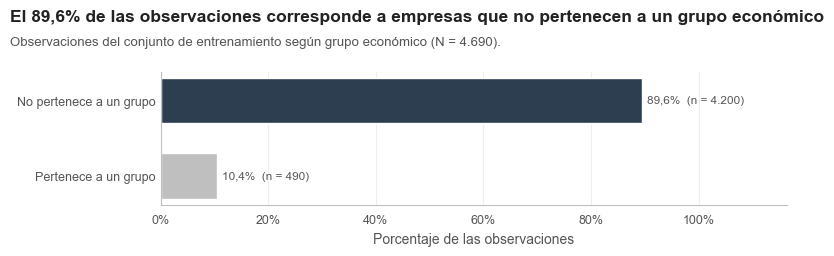

ACTIVIDAD_ECONOMICA — 16 valores unicos, 0 NaN (0.0%)


,N,Default_rate,Pct
ACTIVIDAD_ECONOMICA,,,
Otros,1591,0.070,33.923
EXPLOTACION GANADERA (EXCEPTO LECHERIA),1019,0.094,21.727
CUL.DE PROD.AGRI.EN COMB.CON CRIA DE ANIM. EXPLOT.MIXTA,387,0.047,8.252
TRANSPORTE DE CARGA POR CARRETERA,353,0.096,7.527
OTRAS ACTIVIDADES DE SERVICIOS N.C.P.,259,0.100,5.522
EXPLOTACION LECHERA,191,0.120,4.072
SERVICIOS AGRICOLAS,133,0.090,2.836
VENTA AL POR MAYOR DE OTROS PRODUCTOS,116,0.078,2.473
"VTA. MENOR ALMAC NO ESPECIALI.,DE ALIM.,BEB. TAB",102,0.049,2.175


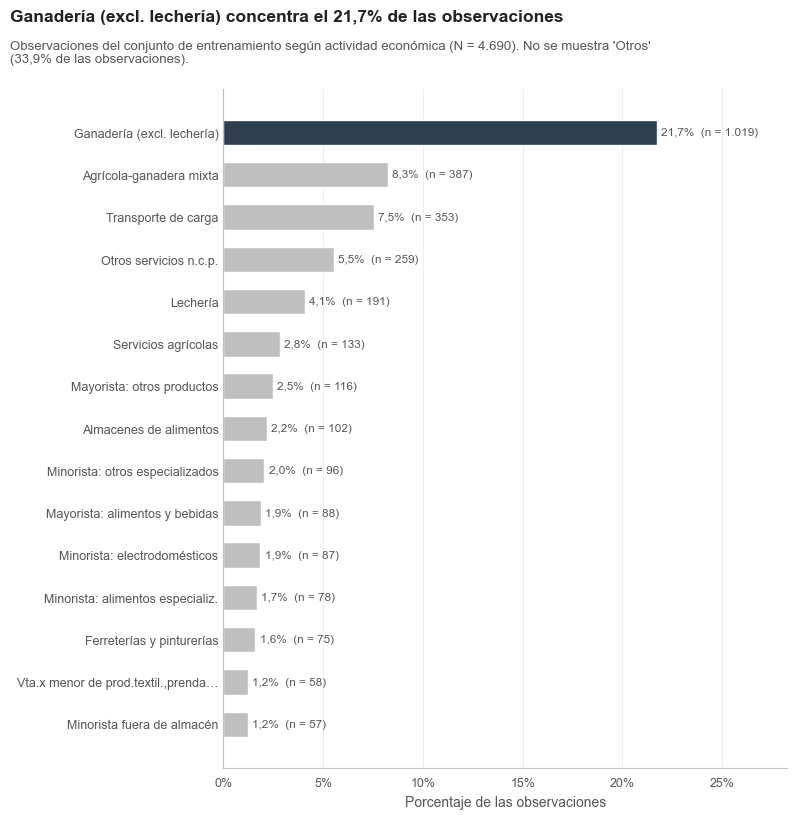

TIPO_SOCIEDAD — 6 valores unicos, 0 NaN (0.0%)


,N,Default_rate,Pct
TIPO_SOCIEDAD,,,
Unipersonal,2965,0.086,63.220
Sociedad de Resp. Limitada,763,0.080,16.269
Sociedad Anonima,572,0.070,12.196
Sociedad de Hecho,219,0.064,4.670
Otros,169,0.030,3.603
Sociedad en Comandita Simple,2,0.000,0.043


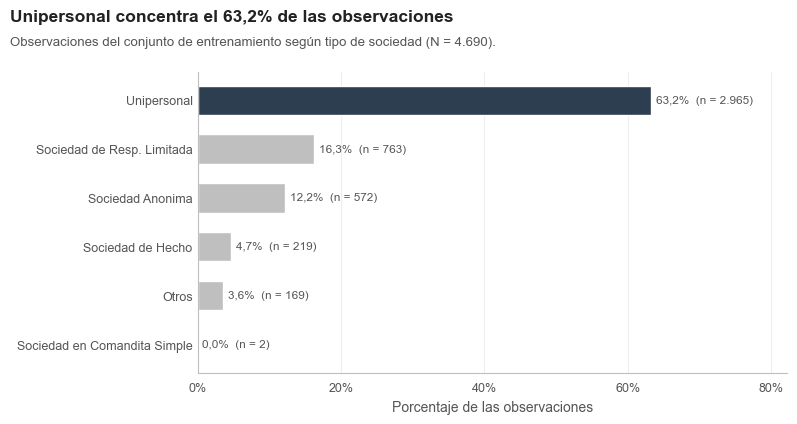

NUMERO_EMPLEADOS — 40 valores unicos, 0 NaN (0.0%)
Top 10 (de 40):


,N,Pct
NUMERO_EMPLEADOS,,
0.0,3268,69.7
1.0,570,12.2
2.0,266,5.7
3.0,126,2.7
4.0,87,1.9
5.0,78,1.7
10.0,38,0.8
7.0,36,0.8
6.0,36,0.8


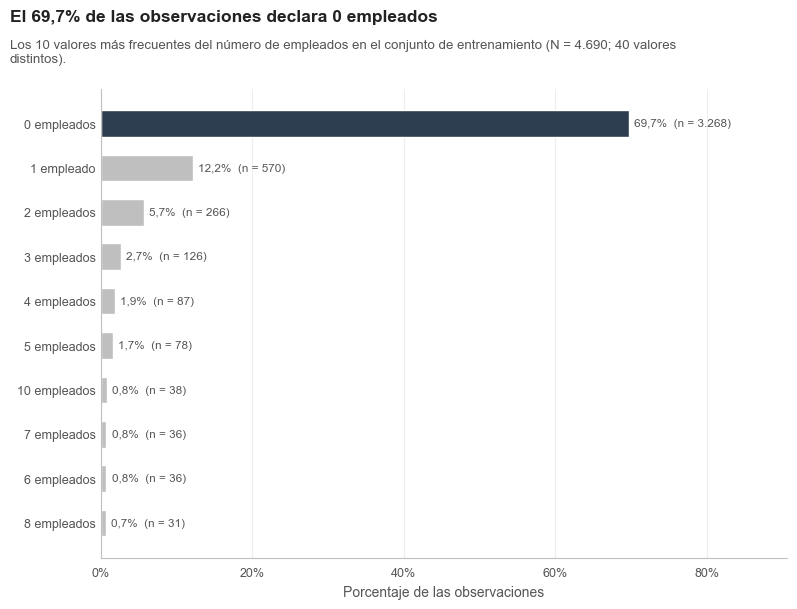

In [39]:
# Se grafica la distribucion de cada variable
# Variables con etiquetas largas: se omite el bucket residual 'Otros' (no es una actividad real)
COLS_BARRAS_HORIZONTALES = {'ACTIVIDAD_ECONOMICA'}
_NOMBRE_CUALI = {'GRUPO_ECONOMICO': 'grupo económico', 'ACTIVIDAD_ECONOMICA': 'actividad económica',
                 'TIPO_SOCIEDAD': 'tipo de sociedad', 'NUMERO_EMPLEADOS': 'número de empleados'}
_ETQ_GRUPO = {0: 'No pertenece a un grupo', 1: 'Pertenece a un grupo'}


for col in cols_cualitativas:
    data = df_train[col].dropna()
    n_unique = data.nunique()
    print(f"{col} — {n_unique} valores unicos, {len(df_train) - len(data)} NaN ({(1-len(data)/len(df_train))*100:.1f}%)")
    _sub_cuali = (f'Observaciones del conjunto de entrenamiento según {_NOMBRE_CUALI.get(col, col)} '
                  f'(N = {formato_coma(len(df_train), 0)}).')

    if n_unique <= 20:
        vc = df_train.groupby(col, dropna=False).agg(
            N=('DEFAULT_FUTURE', 'size'),
            Default_rate=('DEFAULT_FUTURE', 'mean')
        ).sort_values('N', ascending=False)
        vc['Pct'] = vc['N'] / vc['N'].sum() * 100
        display(vc.round(3))

        vc_plot = vc[vc.index != 'Otros'] if col in COLS_BARRAS_HORIZONTALES else vc
        pct_otros = vc['Pct'].get('Otros', 0.0)
        _fr = (vc_plot['N'] / vc['N'].sum()).values
        if col == 'GRUPO_ECONOMICO':
            _et = [_ETQ_GRUPO.get(v, str(v)) for v in vc_plot.index]
            _tit = (f"El {formato_porcentaje(_fr[0])} de las observaciones corresponde a empresas que "
                    f"{'no pertenecen' if vc_plot.index[0] == 0 else 'pertenecen'} a un grupo económico")
        else:
            _et = [etiqueta_actividad(v) if col == 'ACTIVIDAD_ECONOMICA' else etiqueta_corta_actividad(v, col) for v in vc_plot.index]
            _tit = f'{_et[0]} concentra el {formato_porcentaje(_fr[0])} de las observaciones'
        if col in COLS_BARRAS_HORIZONTALES and 'Otros' in vc.index:
            _sub_cuali += f" No se muestra 'Otros' ({formato_coma(pct_otros, 1)}% de las observaciones)."
        grafico_barras_composicion(_et, _fr, vc_plot['N'].values, _tit, _sub_cuali)
    else:
        top10 = data.value_counts().head(10)
        top10_pct = top10 / len(data) * 100
        print(f"Top 10 (de {n_unique}):")
        display(top10.to_frame('N').assign(Pct=lambda d: d['N']/len(data)*100).round(1))

        _et = [f"{int(v)} empleado{'' if int(v) == 1 else 's'}" if float(v).is_integer() else str(v) for v in top10.index]
        _fr = (top10 / len(data)).values
        grafico_barras_composicion(_et, _fr, top10.values,
                            f'El {formato_porcentaje(_fr[0])} de las observaciones declara {_et[0]}',
                            f'Los 10 valores más frecuentes del {_NOMBRE_CUALI.get(col, col)} en el conjunto de '
                            f'entrenamiento (N = {formato_coma(len(data), 0)}; {n_unique} valores distintos).')


In [40]:
# Distribucion por tamaño de empresa y tasa de default de cada tamaño
if 'tamaño_EMPRESA' in df_train.columns:                                                                                                                                              
    tamaño_data = df_train['tamaño_EMPRESA'].dropna()
    tamaño_order = ['Microempresa', 'Pequena', 'Mediana', 'Grande']                                                                                                                      
    tamaño_counts = tamaño_data.value_counts().reindex(tamaño_order).fillna(0).astype(int)                                                                                             
    tamaño_pct = tamaño_counts / tamaño_counts.sum() * 100                                                                                                                               
    tamaño_dr = df_train.groupby('tamaño_EMPRESA')['DEFAULT_FUTURE'].mean().reindex(tamaño_order)                                                                                     
                                                                                                                                                                                        
                                                                                                                                                                             
    print('Distribucion por tamaño de empresa (criterio BCU)')                                                                                                                           
                                                                                                                                                                             
    n_con = len(tamaño_data)
    n_sin = df_train['tamaño_EMPRESA'].isna().sum()                                                                                                                                   
    print(f'Total con tamaño asignado: {n_con:,} ({n_con/len(df_train)*100:.1f}%)')                                                                                                   
    print(f'Sin tamaño (NaN): {n_sin:,}')                                                                                                                                                
    print(f'{"tamaño":<15s} {"N":>7s} {"Pct":>7s} {"Default%":>9s}')                                                                                                                     
    for cat in tamaño_order:                                                                                                                                                             
        n = tamaño_counts[cat]                                                                                                                                                           
        porc = tamaño_pct[cat]                                                                                                                                                          
        dr = tamaño_dr[cat] * 100 if pd.notna(tamaño_dr[cat]) else 0                                                                                                                     
        print(f'{cat:<15s} {n:>7,} {porc:>6.1f}% {dr:>8.1f}%')
else:                                                                                                                                                                                  
    print('Columna tamaño_EMPRESA no encontrada')


Distribucion por tamaño de empresa (criterio BCU)
Total con tamaño asignado: 4,690 (100.0%)
Sin tamaño (NaN): 0
tamaño                N     Pct  Default%
Microempresa      2,794   59.6%      8.2%
Pequena           1,451   30.9%      8.8%
Mediana             433    9.2%      3.9%
Grande               12    0.3%     16.7%


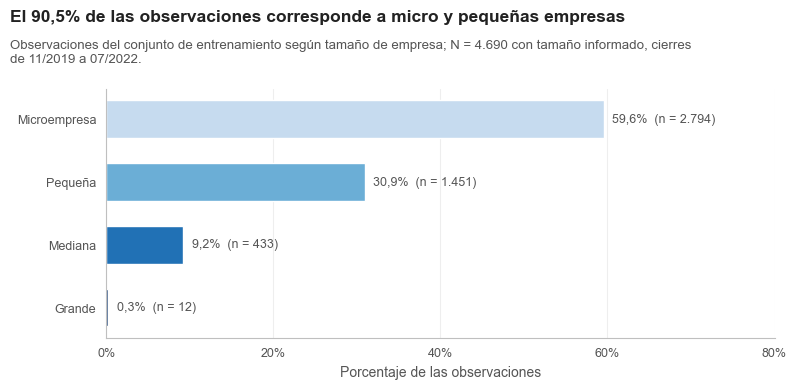

Guardada: graficos_tesis/fig_2_1_tamano_empresa.png


In [41]:
# Figura 2.1 — Composicion de la muestra por tamano de empresa (ordinal: orden natural, paleta secuencial)
_ord = ['Microempresa', 'Pequena', 'Mediana', 'Grande']
_etq = {'Microempresa': 'Microempresa', 'Pequena': 'Pequeña', 'Mediana': 'Mediana', 'Grande': 'Grande'}
_tam = df_train['tamaño_EMPRESA'].value_counts().reindex(_ord).fillna(0).astype(int)
_n_tam, _n_na = int(_tam.sum()), int(df_train['tamaño_EMPRESA'].isna().sum())
_frac = _tam / _n_tam
_pyme = _frac[['Microempresa', 'Pequena']].sum()

fig, ax = plt.subplots(figsize=(8, 3.2))
_y = np.arange(len(_ord))[::-1]
ax.barh(_y, _frac.values, color=['#c6dbef', '#6baed6', '#2171b5', '#08306b'], height=0.6)
for yy, (k, v) in zip(_y, _frac.items()):
    ax.text(v + 0.01, yy, f'{formato_porcentaje(v)}  (n = {formato_coma(_tam[k], 0)})', va='center', fontsize=9, color=GRIS_TXT)
ax.set_yticks(_y)
ax.set_yticklabels([_etq[k] for k in _ord])
ax.set_xlim(0, 0.8)
eje_porcentaje(ax, 'x')
ax.set_xlabel('Porcentaje de las observaciones', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
guardar_figura(fig,
          f'El {formato_porcentaje(_pyme)} de las observaciones corresponde a micro y pequeñas empresas',
          f'Observaciones del conjunto de entrenamiento según tamaño de empresa; N = {formato_coma(_n_tam, 0)} con tamaño '
          f'informado, cierres de {PERIODO}.',
          f'Fuente: {FUENTE_EC}; tamaño según ingresos operativos en UI, con los lineamientos del BCU.'
          + (f'\nNotas: {formato_coma(_n_na, 0)} observaciones sin tamaño informado no se muestran.' if _n_na else ''),
          'fig_2_1_tamano_empresa.png')


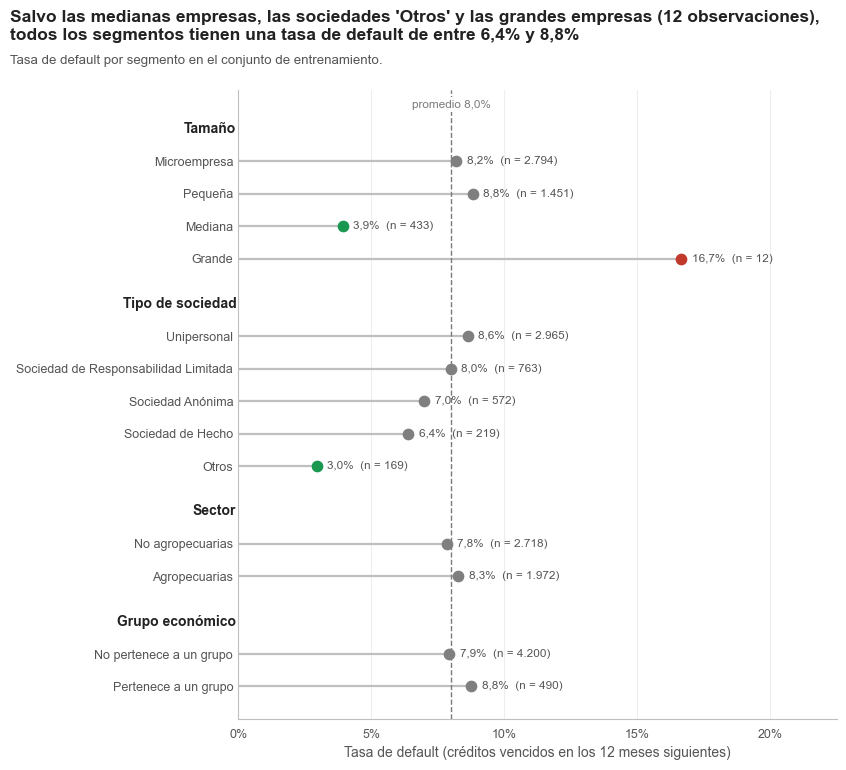

Guardada: graficos_tesis/fig_2_3_default_por_segmento.png


In [42]:
# Figura 2.3 — Tasa de default por segmento (una figura en lugar de seis): puntos, promedio, n visible
_t = df_train.copy()
_t['_tam'] = _t['tamaño_EMPRESA'].map({'Microempresa': 'Microempresa', 'Pequena': 'Pequeña',
                                       'Mediana': 'Mediana', 'Grande': 'Grande'})
_t['_grupo'] = pd.to_numeric(_t['GRUPO_ECONOMICO'], errors='coerce').map({1: 'Pertenece a un grupo',
                                                                          0: 'No pertenece a un grupo'})
_t['_sector'] = _t['SECTOR'].map({'Agro': 'Agropecuarias', 'Empresas': 'No agropecuarias'})
_bloques = [('Tamaño', '_tam', ['Microempresa', 'Pequeña', 'Mediana', 'Grande']),
            ('Tipo de sociedad', 'TIPO_SOCIEDAD', None),
            ('Sector', '_sector', ['No agropecuarias', 'Agropecuarias']),
            ('Grupo económico', '_grupo', ['No pertenece a un grupo', 'Pertenece a un grupo'])]
_filas = []
for bloque, col, orden in _bloques:
    g = _t.groupby(col)['DEFAULT_FUTURE'].agg(['mean', 'size'])
    g = g.reindex(orden) if orden else g.sort_values('mean', ascending=False)
    for cat, r in g.iterrows():
        _filas.append({'bloque': bloque, 'cat': str(cat), 'dr': r['mean'], 'n': int(r['size'])})
seg = pd.DataFrame(_filas)
# Sociedad en Comandita Simple (3 observaciones, 2 en entrenamiento) no se muestra: su tasa no es informativa
seg = seg[seg['cat'] != 'Sociedad en Comandita Simple'].reset_index(drop=True)
ETQ_SEG = {'Sociedad Anonima': 'Sociedad Anónima', 'Sociedad de Resp. Limitada': 'Sociedad de Responsabilidad Limitada'}
FRASE_SEG = {'Mediana': 'las medianas empresas', 'Grande': 'las grandes empresas', 'Otros': "las sociedades 'Otros'",
             'Sociedad de Hecho': 'las sociedades de hecho'}
_prom = df_train['DEFAULT_FUTURE'].mean()

fig, ax = plt.subplots(figsize=(8.5, 7))
y, yticks, ylabels = 0, [], []
for bloque in [b[0] for b in _bloques]:
    ax.text(-0.003, -y, bloque, fontsize=10, fontweight='bold', color='#222222', ha='right', va='center',
            transform=ax.get_yaxis_transform())
    y += 1
    for _, r in seg[seg['bloque'] == bloque].iterrows():
        chico = r['n'] < 30
        col = ENFASIS if r['dr'] > 1.5 * _prom else (VERDE if r['dr'] < 0.6 * _prom and not chico else '#7F7F7F')
        ax.plot([0, r['dr']], [-y, -y], color='#BFBFBF', lw=1.6, zorder=1)
        ax.scatter(r['dr'], -y, s=55, color=col, zorder=3)
        ax.text(r['dr'] + 0.004, -y, f"{formato_porcentaje(r['dr'])}  (n = {formato_coma(r['n'], 0)})",
                va='center', fontsize=8.5, color=GRIS_TXT)
        yticks.append(-y); ylabels.append(ETQ_SEG.get(r['cat'], r['cat']))
        y += 1
    y += 0.4
ax.axvline(_prom, color=REFERENCIA, ls='--', lw=1)
ax.text(_prom, 0.6, f'promedio {formato_porcentaje(_prom)}', color=REFERENCIA, fontsize=8.5, ha='center', va='bottom', bbox=CAJA)
ax.set_yticks(yticks)
ax.set_yticklabels(ylabels, fontsize=9)
ax.set_ylim(-y + 0.4, 1.2)
ax.set_xlim(0, max(0.2, seg['dr'].max() * 1.35))
eje_porcentaje(ax, 'x')
ax.set_xlabel('Tasa de default (créditos vencidos en los 12 meses siguientes)', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
ax.tick_params(axis='y', length=0)
_ok = seg[seg['n'] >= 30]
_bajos = _ok[_ok['dr'] < 0.6 * _prom]
_resto = _ok.drop(_bajos.index)
# 16/11: el titulo nombra tambien los segmentos con menos de 30 observaciones (las grandes empresas, 16,7%),
# que quedan fuera del rango y se muestran en la figura
_chicos = seg[seg['n'] < 30]
_excep = [FRASE_SEG.get(c, c) for c in _bajos['cat']] + \
         [f"{FRASE_SEG.get(c, c)} ({formato_coma(n, 0)} observaciones)" for c, n in zip(_chicos['cat'], _chicos['n'])]
_lista = _excep[0] if len(_excep) == 1 else ', '.join(_excep[:-1]) + ' y ' + _excep[-1] if _excep else ''
_tit = (f"Salvo {_lista}, todos los segmentos tienen una tasa de default "
        f"de entre {formato_porcentaje(_resto['dr'].min())} y {formato_porcentaje(_resto['dr'].max())}") if _excep else \
       f"La tasa de default va de {formato_porcentaje(_ok['dr'].min())} a {formato_porcentaje(_ok['dr'].max())} entre segmentos"
guardar_figura(fig, _tit,
          'Tasa de default por segmento en el conjunto de entrenamiento.',
          f'Fuente: {FUENTE_EC}, información cualitativa del BROU y {FUENTE_CR}.\n'
          f'Notas: default = {DEF_EVENTO}. Las tasas de grupos con menos de 30 observaciones no son informativas.',
          'fig_2_3_default_por_segmento.png')


In [43]:
fecha_eda = df_train['FECHA_dt']                                                                                             
rut_eda = df_train['RUT']
target_eda = df_train['DEFAULT_FUTURE']


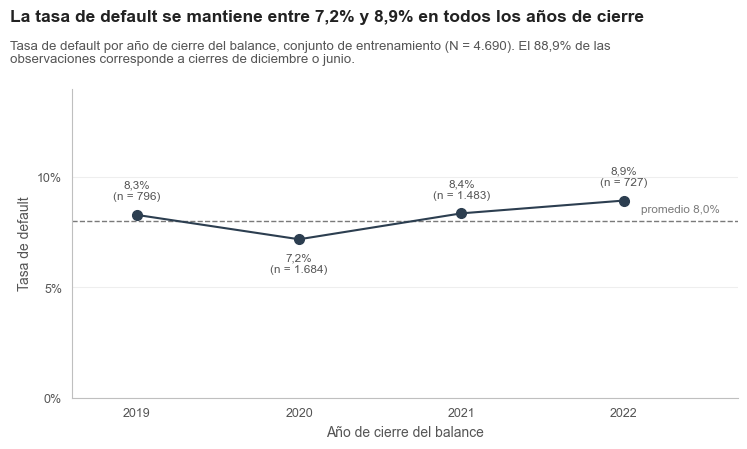

Guardada: graficos_tesis/fig_2_5_default_por_anio.png


In [44]:
# Figura 2.5 — Tasa de default por anio de cierre (reemplaza el grafico mensual con eje secundario)
_a = df_train.groupby(df_train['FECHA_dt'].dt.year)['DEFAULT_FUTURE'].agg(['mean', 'size'])
_prom = df_train['DEFAULT_FUTURE'].mean()
_dic_jun = df_train['FECHA_dt'].dt.month.isin([6, 12]).mean()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(_a.index, _a['mean'], color=OSCURO, lw=1.5, marker='o', ms=7, zorder=3)
for yr, r in _a.iterrows():
    arriba = r['mean'] >= _prom
    ax.text(yr, r['mean'] + (0.006 if arriba else -0.006), f"{formato_porcentaje(r['mean'])}\n(n = {formato_coma(r['size'], 0)})", ha='center',
            va='bottom' if arriba else 'top', fontsize=8.5, color=GRIS_TXT)
ax.axhline(_prom, color=REFERENCIA, ls='--', lw=1)
ax.text(_a.index.max() + 0.35, _prom + 0.003, f'promedio {formato_porcentaje(_prom)}', color=REFERENCIA, fontsize=8.5,
        va='bottom', ha='center')
ax.set_xticks(_a.index)
ax.set_xlim(_a.index.min() - 0.4, _a.index.max() + 0.7)
ax.set_ylim(0, max(0.14, _a['mean'].max() * 1.5))
eje_porcentaje(ax, 'y')
ax.set_xlabel('Año de cierre del balance', color=GRIS_TXT)
ax.set_ylabel('Tasa de default', color=GRIS_TXT)
limpiar_ejes(ax, grid='y')
guardar_figura(fig,
          f"La tasa de default se mantiene entre {formato_porcentaje(_a['mean'].min())} y {formato_porcentaje(_a['mean'].max())} "
          'en todos los años de cierre',
          f'Tasa de default por año de cierre del balance, conjunto de entrenamiento (N = {formato_coma(len(df_train), 0)}). '
          f'El {formato_porcentaje(_dic_jun)} de las observaciones corresponde a cierres de diciembre o junio.',
          f'Fuente: {FUENTE_EC} y {FUENTE_CR}.\n'
          f"Notas: {int(_a.index.max())} incluye cierres hasta {df_train['FECHA_dt'].max():%m/%Y}. "
          'Las observaciones con cierres de 2019 a 2021 se siguen durante la pandemia, con medidas de alivio financiero vigentes.',
          'fig_2_5_default_por_anio.png')


             mean  size  sum
sem                         
2019-S2  0.082915   796   66
2020-S1  0.077124   765   59
2020-S2  0.067465   919   62
2021-S1  0.071788   794   57
2021-S2  0.097242   689   67
2022-S1  0.091421   711   65
2022-S2  0.000000    16    0


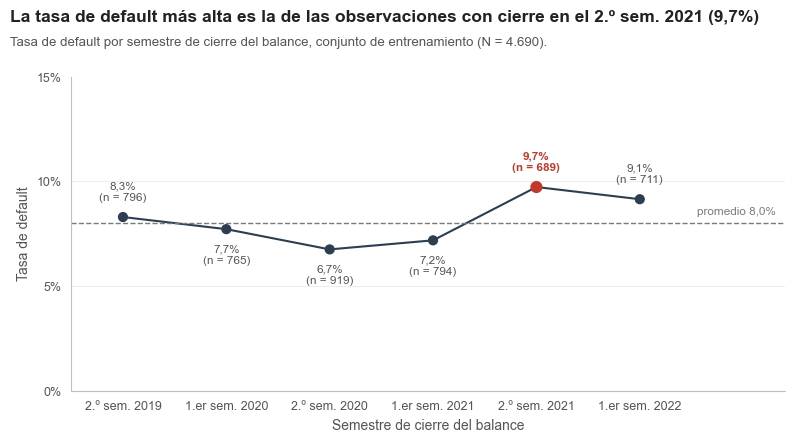

Guardada: graficos_tesis/fig_2_5b_default_por_semestre.png


In [45]:
# Figura 2.5b — Tasa de default por semestre de cierre del balance (mas detalle temporal que la anual,
# sin el ruido de los meses con pocas observaciones)
N_MIN_SEM = 100
_s = df_train[['FECHA_dt', 'DEFAULT_FUTURE']].copy()
_s['sem'] = _s['FECHA_dt'].dt.year.astype(str) + '-S' + np.where(_s['FECHA_dt'].dt.month <= 6, '1', '2')
_sem_all = _s.groupby('sem')['DEFAULT_FUTURE'].agg(['mean', 'size', 'sum']).sort_index()
print(_sem_all)
_sem = _sem_all[_sem_all['size'] >= N_MIN_SEM]
_fuera = _sem_all[_sem_all['size'] < N_MIN_SEM]
_prom = df_train['DEFAULT_FUTURE'].mean()
_imax = _sem['mean'].idxmax()

fig, ax = plt.subplots(figsize=(8, 3.9))
_x = np.arange(len(_sem))
ax.plot(_x, _sem['mean'], color=OSCURO, lw=1.5, zorder=2)
ax.scatter(_x, _sem['mean'], s=[60 if k == _imax else 40 for k in _sem.index],
           color=[ENFASIS if k == _imax else OSCURO for k in _sem.index], zorder=3)
for xx, (k, r) in zip(_x, _sem.iterrows()):
    arriba = r['mean'] >= _prom
    ax.text(xx, r['mean'] + (0.007 if arriba else -0.007), f"{formato_porcentaje(r['mean'])}\n(n = {formato_coma(r['size'], 0)})",
            ha='center', va='bottom' if arriba else 'top', fontsize=8.5,
            color=ENFASIS if k == _imax else GRIS_TXT, fontweight='bold' if k == _imax else 'normal')
ax.axhline(_prom, color=REFERENCIA, ls='--', lw=1)
ax.text(len(_sem) - 0.45, _prom + 0.003, f'promedio {formato_porcentaje(_prom)}', color=REFERENCIA, fontsize=8.5, va='bottom', ha='left')
ax.set_xticks(_x)
ax.set_xticklabels([etiqueta_semestre(k) for k in _sem.index])
ax.set_xlim(-0.5, len(_sem) + 0.4)
ax.set_ylim(0, max(0.15, _sem['mean'].max() * 1.45))
eje_porcentaje(ax, 'y')
ax.set_xlabel('Semestre de cierre del balance', color=GRIS_TXT)
ax.set_ylabel('Tasa de default', color=GRIS_TXT)
limpiar_ejes(ax, grid='y')
_nota_fuera = (f' No se muestra{"n" if len(_fuera) > 1 else ""} ' + ', '.join(f'{etiqueta_semestre(k)} (n = {int(r["size"])})' for k, r in _fuera.iterrows())
               + f', con menos de {N_MIN_SEM} observaciones.') if len(_fuera) else ''
guardar_figura(fig,
          f'La tasa de default más alta es la de las observaciones con cierre en el {etiqueta_semestre(_imax)} ({formato_porcentaje(_sem.loc[_imax, "mean"])})',
          f'Tasa de default por semestre de cierre del balance, conjunto de entrenamiento (N = {formato_coma(len(df_train), 0)}).',
          f'Fuente: {FUENTE_EC} y {FUENTE_CR}.\nNotas: el {formato_porcentaje(df_train["FECHA_dt"].dt.month.isin([6, 12]).mean())} de las observaciones '
          f'corresponde a cierres de junio o diciembre.' + _nota_fuera,
          'fig_2_5b_default_por_semestre.png')


Distribucion de calificaciones crediticias (BCU) — ANTES de los filtros muestrales
Observaciones (empresas del train): 5,235
Total con calificacion: 4,228 (80.8%)
Sin calificacion (NaN): 1,007

Calif          N     Pct
1C         1,647   39.0%
2A         1,211   28.6%
2B         1,105   26.1%
3            157    3.7%
4             96    2.3%
5             11    0.3%

En 3/4/5 (excluidas luego: default vigente en t): 264 (6.2% de las calificadas)


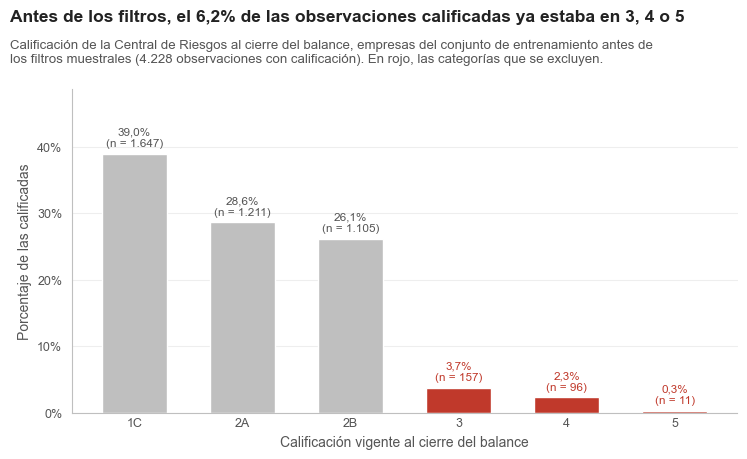

In [46]:
# Distribucion de calificaciones crediticias BCU ANTES de los filtros muestrales
# (se excluyen luego las obs ya en 3/4/5 en t; ver la celda del target).
# Muestra el punto de partida sobre el que se decidio modelar cartera no-default.
# Solo empresas del train: df_pre_filtros se guarda en la celda del target antes
# de filtrar, y aca se restringe por RUT. 1A no se muestra: sin instancias.
if 'df_pre_filtros' in dir():
    _pre = df_pre_filtros[df_pre_filtros['RUT'].isin(df_train['RUT'])]
    cal_data_pre = _pre['CALIFICACION'].dropna()
    cal_order_pre = ['1C', '2A', '2B', '3', '4', '5']
    cal_counts_pre = cal_data_pre.value_counts().reindex(cal_order_pre).fillna(0).astype(int)
    cal_pct_pre = cal_counts_pre / cal_counts_pre.sum() * 100

    print('Distribucion de calificaciones crediticias (BCU) — ANTES de los filtros muestrales')
    n_con_pre = len(cal_data_pre)
    n_sin_pre = _pre['CALIFICACION'].isna().sum()
    print(f'Observaciones (empresas del train): {len(_pre):,}')
    print(f'Total con calificacion: {n_con_pre:,} ({n_con_pre/len(_pre)*100:.1f}%)')
    print(f'Sin calificacion (NaN): {n_sin_pre:,}\n')
    print(f"{'Calif':<8s} {'N':>7s} {'Pct':>7s}")
    for cat in cal_order_pre:
        print(f'{cat:<8s} {cal_counts_pre[cat]:>7,} {cal_pct_pre[cat]:>6.1f}%')
    n_345 = int(cal_counts_pre[['3', '4', '5']].sum())
    print(f'\nEn 3/4/5 (excluidas luego: default vigente en t): {n_345:,} '
          f'({n_345/n_con_pre*100:.1f}% de las calificadas)')

    fig, ax = plt.subplots(figsize=(7.5, 3.9))
    _x = np.arange(len(cal_order_pre))
    _fr = (cal_counts_pre / cal_counts_pre.sum()).values
    _excl = [c in ('3', '4', '5') for c in cal_order_pre]
    ax.bar(_x, _fr, width=0.6, color=[ENFASIS if e else CONTEXTO for e in _excl])
    for x_, f_, n_, e in zip(_x, _fr, cal_counts_pre.values, _excl):
        ax.text(x_, f_ + 0.008, f'{formato_porcentaje(f_)}\n(n = {formato_coma(n_, 0)})', ha='center', va='bottom', fontsize=8.5,
                color=ENFASIS if e else GRIS_TXT)
    ax.set_xticks(_x)
    ax.set_xticklabels(cal_order_pre)
    ax.set_ylim(0, _fr.max() * 1.25)
    eje_porcentaje(ax, 'y')
    ax.set_xlabel('Calificación vigente al cierre del balance', color=GRIS_TXT)
    ax.set_ylabel('Porcentaje de las calificadas', color=GRIS_TXT)
    ax.tick_params(axis='x', length=0)
    limpiar_ejes(ax, grid='y')
    guardar_figura(fig, f'Antes de los filtros, el {formato_porcentaje(n_345 / n_con_pre)} de las observaciones calificadas ya estaba en 3, 4 o 5',
              f'Calificación de la Central de Riesgos al cierre del balance, empresas del conjunto de entrenamiento antes de '
              f'los filtros muestrales ({formato_coma(n_con_pre, 0)} observaciones con calificación). En rojo, las categorías que se excluyen.',
              '', None)
else:
    print('df_pre_filtros no definido: ejecutar antes la celda del target')


Distribucion de calificaciones crediticias (BCU)
Total con calificacion: 3,951 (84.2%)
Sin calificacion (NaN): 739

Calif          N     Pct  Default%
1C         1,639   41.5%      4.9%
2A         1,208   30.6%      8.9%
2B         1,103   27.9%     14.8%
3              0    0.0%      0.0%
4              0    0.0%      0.0%
5              0    0.0%      0.0%


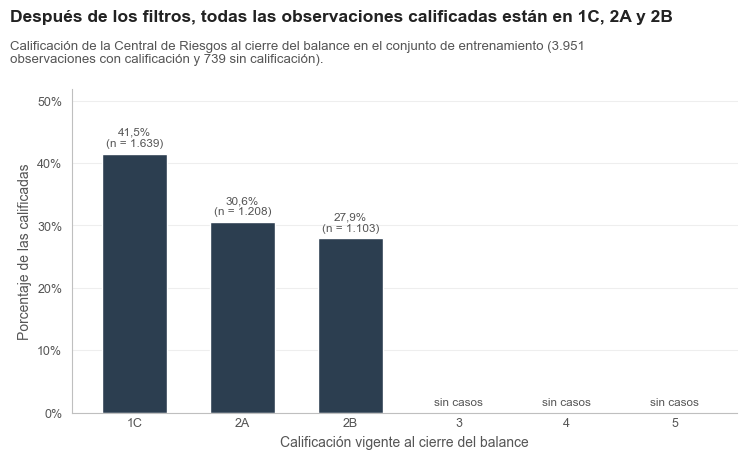

In [47]:
# Se grafica la distribucion de calificaciones crediticias BCU
if 'CALIFICACION' in df_train.columns:
    cal_data = df_train['CALIFICACION'].dropna()
    cal_order = ['1C', '2A', '2B', '3', '4', '5']   # 1A no se muestra: sin instancias
    cal_counts = cal_data.value_counts().reindex(cal_order).fillna(0).astype(int)
    cal_pct = cal_counts / cal_counts.sum() * 100
    cal_dr = df_train.groupby('CALIFICACION')['DEFAULT_FUTURE'].mean().reindex(cal_order)

     
    print('Distribucion de calificaciones crediticias (BCU)')
     
    n_con = len(cal_data)
    n_sin = df_train['CALIFICACION'].isna().sum()
    print(f'Total con calificacion: {n_con:,} ({n_con/len(df_train)*100:.1f}%)')
    print(f'Sin calificacion (NaN): {n_sin:,}\n')
    header = f"{'Calif':<8s} {'N':>7s} {'Pct':>7s} {'Default%':>9s}"
    print(header)
    for cat in cal_order:
        n = cal_counts[cat]
        porc = cal_pct[cat]
        dr = cal_dr[cat] * 100 if pd.notna(cal_dr[cat]) else 0
        print(f'{cat:<8s} {n:>7,} {porc:>6.1f}% {dr:>8.1f}%')

    fig, ax = plt.subplots(figsize=(7.5, 3.9))
    _x = np.arange(len(cal_order))
    _fr = (cal_counts / cal_counts.sum()).values
    ax.bar(_x, _fr, width=0.6, color=OSCURO)
    for x_, f_, n_ in zip(_x, _fr, cal_counts.values):
        ax.text(x_, f_ + 0.008, f'{formato_porcentaje(f_)}\n(n = {formato_coma(n_, 0)})' if n_ else 'sin casos', ha='center', va='bottom',
                fontsize=8.5, color=GRIS_TXT)
    ax.set_xticks(_x)
    ax.set_xticklabels(cal_order)
    ax.set_ylim(0, _fr.max() * 1.25)
    eje_porcentaje(ax, 'y')
    ax.set_xlabel('Calificación vigente al cierre del balance', color=GRIS_TXT)
    ax.set_ylabel('Porcentaje de las calificadas', color=GRIS_TXT)
    ax.tick_params(axis='x', length=0)
    limpiar_ejes(ax, grid='y')
    _con_casos = [c for c in cal_order if cal_counts[c] > 0]
    _lista_cal = _con_casos[0] if len(_con_casos) == 1 else ', '.join(_con_casos[:-1]) + ' y ' + _con_casos[-1]
    guardar_figura(fig, f'Después de los filtros, todas las observaciones calificadas están en {_lista_cal}',
              f'Calificación de la Central de Riesgos al cierre del balance en el conjunto de entrenamiento '
              f'({formato_coma(n_con, 0)} observaciones con calificación y {formato_coma(n_sin, 0)} sin calificación).', '', None)
else:
    print('Columna CALIFICACION no encontrada')


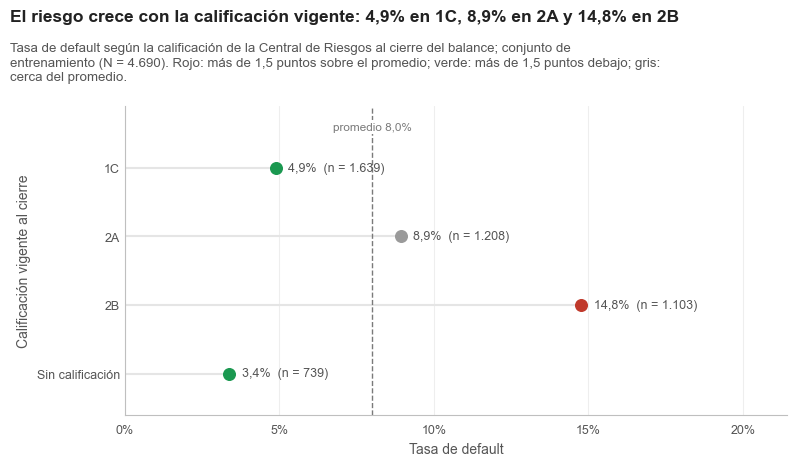

Guardada: graficos_tesis/fig_2_4_default_por_calificacion.png


In [48]:
# Figura 2.4 — Tasa de default por calificacion vigente (orden natural; mismo codigo de color que la Figura 2.3b)
_cal = df_train['CALIFICACION'].fillna('Sin calificación').astype(str).str.strip()
tab = (pd.DataFrame({'c': _cal, 'd': df_train['DEFAULT_FUTURE'].astype(int)})
       .groupby('c')['d'].agg(['mean', 'size']))
_orden = [c for c in ['1C', '2A', '2B'] if c in tab.index] + ['Sin calificación']   # 1A: una sola observacion
tab = tab.reindex(_orden)
_prom = df_train['DEFAULT_FUTURE'].mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
_y = np.arange(len(_orden))[::-1]
for yy, (c, r) in zip(_y, tab.iterrows()):
    chico = r['size'] < 30
    col = CONTEXTO if chico else (ENFASIS if r['mean'] > _prom + 0.015 else (VERDE if r['mean'] < _prom - 0.015 else '#9A9A9A'))
    ax.plot([0, r['mean']], [yy, yy], color='#E5E5E5', lw=1.5, zorder=1)
    ax.scatter(r['mean'], yy, s=70, color=col, zorder=3)
    ax.text(r['mean'] + 0.004, yy, f"{formato_porcentaje(r['mean'])}  (n = {formato_coma(r['size'], 0)}){'  · pocos casos' if chico else ''}",
            va='center', fontsize=9, color=GRIS_TXT)
ax.axvline(_prom, color=REFERENCIA, ls='--', lw=1)
ax.text(_prom, _y.max() + 0.55, f'promedio {formato_porcentaje(_prom)}', color=REFERENCIA, fontsize=8.5, ha='center', bbox=CAJA)
ax.set_yticks(_y)
ax.set_yticklabels(_orden)
ax.set_ylim(-0.6, _y.max() + 0.9)
ax.set_xlim(0, tab['mean'].max() * 1.45)
eje_porcentaje(ax, 'x')
ax.set_xlabel('Tasa de default', color=GRIS_TXT)
ax.set_ylabel('Calificación vigente al cierre', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
ax.tick_params(axis='y', length=0)
_n1a = int(tab.loc['1A', 'size']) if '1A' in tab.index else 0
guardar_figura(fig,
          f"El riesgo crece con la calificación vigente: {formato_porcentaje(tab.loc['1C', 'mean'])} en 1C, "
          f"{formato_porcentaje(tab.loc['2A', 'mean'])} en 2A y {formato_porcentaje(tab.loc['2B', 'mean'])} en 2B",
          f'Tasa de default según la calificación de la Central de Riesgos al cierre del balance; conjunto de entrenamiento '
          f'(N = {formato_coma(len(df_train), 0)}). Rojo: más de 1,5 puntos sobre el promedio; verde: más de 1,5 puntos debajo; '
          'gris: cerca del promedio.',
          f'Fuente: {FUENTE_CR}; peor calificación entre instituciones del último mes informado en los 12 meses previos.\n'
          'Notas: las calificaciones 3, 4 y 5 se excluyen de la muestra (empresas ya en default). '
          "'Sin calificación': sin deuda bancaria informada al cierre"
          + ((f'. 1A: {_n1a} observación, en gris.' if _n1a == 1 else f'. 1A: {_n1a} observaciones, en gris.')
             if 0 < _n1a < 30 else '.'),
          'fig_2_4_default_por_calificacion.png')


In [49]:
# Distribucion de la variable objetivo (DEFAULT_FUTURE) en train
target_counts = df_train['DEFAULT_FUTURE'].astype(int).value_counts().reindex([0, 1]).fillna(0).astype(int)
target_pct = target_counts / target_counts.sum() * 100
target_labels = ['No default', 'Default']

print('Distribucion de la variable objetivo (DEFAULT_FUTURE) — train')
print(f'Observaciones: {len(df_train):,} | Empresas: {df_train["RUT"].nunique():,}')
print(f"{'Clase':<18s} {'N':>7s} {'Pct':>7s}")
for k, lbl in zip([0, 1], target_labels):
    print(f'{lbl:<18s} {target_counts[k]:>7,} {target_pct[k]:>6.1f}%')
print(f'\nRelacion no default : default = {target_counts[0] / max(target_counts[1], 1):.1f} : 1')


Distribucion de la variable objetivo (DEFAULT_FUTURE) — train
Observaciones: 4,690 | Empresas: 2,547
Clase                    N     Pct
No default           4,314   92.0%
Default                376    8.0%

Relacion no default : default = 11.5 : 1


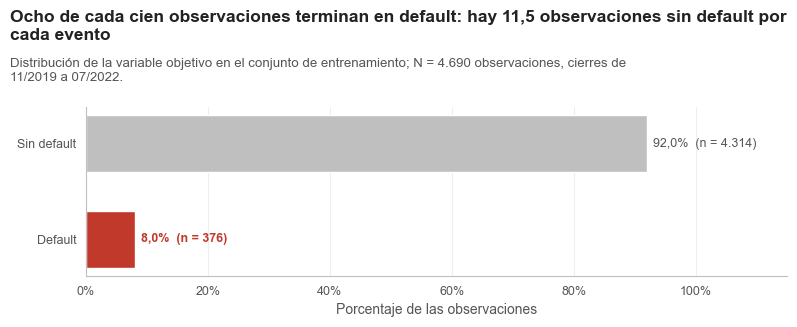

Guardada: graficos_tesis/fig_2_2b_distribucion_clases.png


In [50]:
# Figura 2.2b — Distribucion de la variable objetivo en entrenamiento (desbalance de clases)
_n_def = int(df_train['DEFAULT_FUTURE'].sum())
_n_ok = len(df_train) - _n_def
_tasa = _n_def / len(df_train)
_ratio = _n_ok / _n_def

fig, ax = plt.subplots(figsize=(8, 2.4))
_cls = [('Sin default', _n_ok, CONTEXTO), ('Default', _n_def, ENFASIS)]
for yy, (etq, n, col) in zip([1, 0], _cls):
    ax.barh(yy, n / len(df_train), color=col, height=0.6)
    ax.text(n / len(df_train) + 0.01, yy, f'{formato_porcentaje(n / len(df_train))}  (n = {formato_coma(n, 0)})', va='center', fontsize=9,
            color=ENFASIS if etq == 'Default' else GRIS_TXT, fontweight='bold' if etq == 'Default' else 'normal')
ax.set_yticks([1, 0])
ax.set_yticklabels([c[0] for c in _cls])
ax.set_xlim(0, 1.15)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
eje_porcentaje(ax, 'x')
ax.set_xlabel('Porcentaje de las observaciones', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
guardar_figura(fig,
          f'Ocho de cada cien observaciones terminan en default: hay {formato_coma(_ratio, 1)} observaciones sin default por cada evento'
          if round(_tasa * 100) == 8 else
          f'El {formato_porcentaje(_tasa)} de las observaciones termina en default: hay {formato_coma(_ratio, 1)} sin default por cada evento',
          f'Distribución de la variable objetivo en el conjunto de entrenamiento; N = {formato_coma(len(df_train), 0)} observaciones, '
          f'cierres de {PERIODO}.',
          f'Fuente: {FUENTE_CR}.\nNotas: default = {DEF_EVENTO}.',
          'fig_2_2b_distribucion_clases.png')


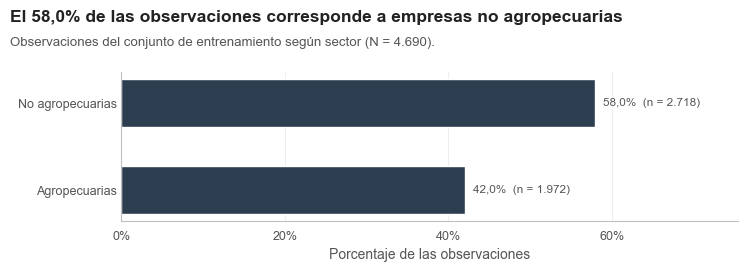

In [51]:
# Se grafica la distribucion por sector
if 'SECTOR' in df_train.columns:
    sector_counts = df_train['SECTOR'].value_counts()
    sector_pct = sector_counts / sector_counts.sum() * 100

    _etq_sec = {'Empresas': 'No agropecuarias', 'Agro': 'Agropecuarias'}
    _fr = sector_counts / sector_counts.sum()
    fig, ax = plt.subplots(figsize=(7.5, 2.2))
    _yy = np.arange(len(_fr))[::-1]
    ax.barh(_yy, _fr.values, height=0.55, color=OSCURO)
    for y_, f_, n_ in zip(_yy, _fr.values, sector_counts.values):
        ax.text(f_ + 0.01, y_, f'{formato_porcentaje(f_)}  (n = {formato_coma(n_, 0)})', va='center', fontsize=8.5, color=GRIS_TXT)
    ax.set_yticks(_yy)
    ax.set_yticklabels([_etq_sec.get(s, s) for s in _fr.index])
    ax.set_xlim(0, _fr.max() * 1.3)
    eje_porcentaje(ax, 'x')
    ax.set_xlabel('Porcentaje de las observaciones', color=GRIS_TXT)
    ax.tick_params(axis='y', length=0)
    limpiar_ejes(ax, grid='x')
    guardar_figura(fig, f"El {formato_porcentaje(_fr.iloc[0])} de las observaciones corresponde a empresas "
                   f"{_etq_sec.get(_fr.index[0], _fr.index[0]).lower()}",
              f'Observaciones del conjunto de entrenamiento según sector (N = {formato_coma(len(df_train), 0)}).', '', None)
else:
    print('Columna SECTOR no encontrada')


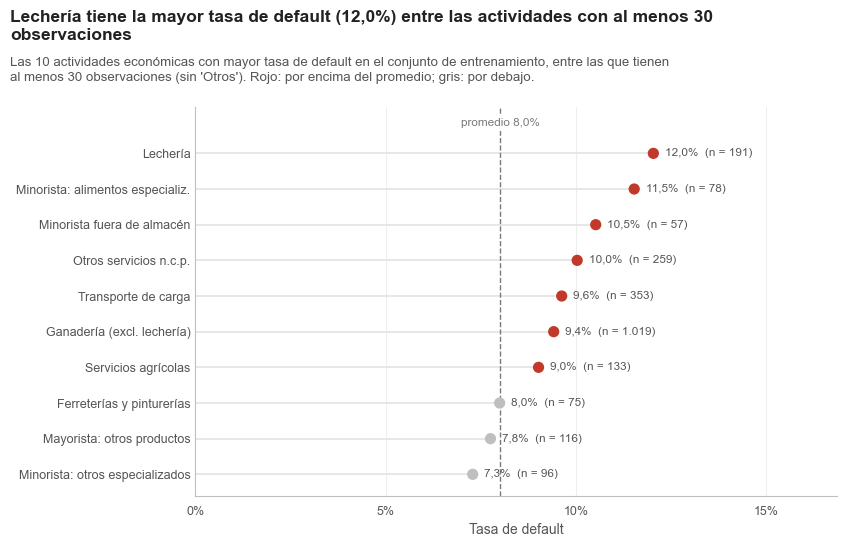

In [52]:
# Se grafican las top 10 actividades economicas con mayor default
if 'ACTIVIDAD_ECONOMICA' in df_train.columns:
    df_act = df_train[['ACTIVIDAD_ECONOMICA', 'DEFAULT_FUTURE']].dropna()
    act_stats = df_act.groupby('ACTIVIDAD_ECONOMICA')['DEFAULT_FUTURE'].agg(
        n='size', default_rate='mean')
    act_stats = act_stats[act_stats.index != 'Otros']  # excluir bucket residual (no es actividad real)
    act_stats = act_stats[act_stats['n'] >= 30]  # se filtran actividades con pocas obs
    top10 = act_stats.sort_values('default_rate', ascending=False).head(10)
    top10 = top10.sort_values('default_rate')  

    _prom_act = df_act['DEFAULT_FUTURE'].mean()
    colors = [ENFASIS if dr > _prom_act else CONTEXTO for dr in top10['default_rate']]
    etiquetas_top10 = [etiqueta_actividad(v) for v in top10.index]
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    _yy = np.arange(len(top10))   # top10 va de menor a mayor tasa: la mayor queda arriba
    ax.hlines(_yy, 0, top10['default_rate'], color='#E5E5E5', lw=1.3, zorder=1)
    ax.scatter(top10['default_rate'], _yy, s=50, color=colors, zorder=3)
    for y_, (_, r_) in zip(_yy, top10.iterrows()):
        ax.text(r_['default_rate'] + 0.003, y_, f"{formato_porcentaje(r_['default_rate'])}  (n = {formato_coma(r_['n'], 0)})", va='center',
                fontsize=8.5, color=GRIS_TXT)
    ax.axvline(_prom_act, color=REFERENCIA, ls='--', lw=1)
    ax.text(_prom_act, len(top10) - 0.3, f'promedio {formato_porcentaje(_prom_act)}', color=REFERENCIA, fontsize=8.5, ha='center',
            va='bottom', bbox=CAJA)
    ax.set_yticks(_yy)
    ax.set_yticklabels(etiquetas_top10, fontsize=9)
    ax.set_ylim(-0.6, len(top10) + 0.3)
    ax.set_xlim(0, top10['default_rate'].max() * 1.4)
    eje_porcentaje(ax, 'x')
    ax.set_xlabel('Tasa de default', color=GRIS_TXT)
    ax.tick_params(axis='y', length=0)
    limpiar_ejes(ax, grid='x')
    guardar_figura(fig, f"{etiquetas_top10[-1]} tiene la mayor tasa de default ({formato_porcentaje(top10['default_rate'].iloc[-1])}) entre "
                   'las actividades con al menos 30 observaciones',
              "Las 10 actividades económicas con mayor tasa de default en el conjunto de entrenamiento, entre las que tienen "
              "al menos 30 observaciones (sin 'Otros'). Rojo: por encima del promedio; gris: por debajo.", '', None)
else:
    print('Columna ACTIVIDAD_ECONOMICA no encontrada')


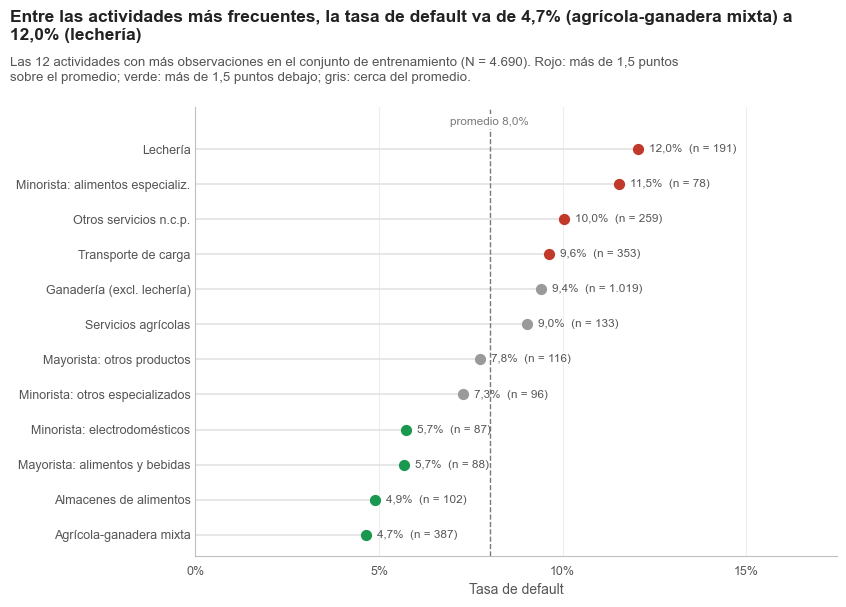

Guardada: graficos_tesis/fig_2_3b_default_por_actividad.png


In [53]:
# Figura 2.3b — Tasa de default por actividad economica: las 12 actividades mas frecuentes, ordenadas por tasa
_act = df_train['ACTIVIDAD_ECONOMICA'].astype(str)
_g = (pd.DataFrame({'a': _act, 'd': df_train['DEFAULT_FUTURE'].astype(int)})
      .groupby('a')['d'].agg(['mean', 'size']))
_otros_act = _g.loc['Otros'] if 'Otros' in _g.index else None
_g = _g.drop(index='Otros', errors='ignore').sort_values('size', ascending=False).head(12).sort_values('mean')
_prom = df_train['DEFAULT_FUTURE'].mean()
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for i, (a, r) in enumerate(_g.iterrows()):
    col = ENFASIS if r['mean'] > _prom + 0.015 else (VERDE if r['mean'] < _prom - 0.015 else '#9A9A9A')
    ax.plot([0, r['mean']], [i, i], color='#E5E5E5', lw=1.3, zorder=1)
    ax.scatter(r['mean'], i, s=50, color=col, zorder=3)
    ax.text(r['mean'] + 0.003, i, f"{formato_porcentaje(r['mean'])}  (n = {formato_coma(r['size'], 0)})", va='center', fontsize=8.5, color=GRIS_TXT)
ax.axvline(_prom, color=REFERENCIA, ls='--', lw=1)
ax.text(_prom, len(_g) - 0.3, f'promedio {formato_porcentaje(_prom)}', color=REFERENCIA, fontsize=8.5, ha='center', bbox=CAJA)
ax.set_yticks(range(len(_g)))
ax.set_yticklabels([etiqueta_actividad(a) for a in _g.index], fontsize=9)
ax.set_ylim(-0.6, len(_g) + 0.2)
ax.set_xlim(0, _g['mean'].max() * 1.45)
eje_porcentaje(ax, 'x')
ax.set_xlabel('Tasa de default', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
ax.tick_params(axis='y', length=0)
_alto, _bajo = _g['mean'].idxmax(), _g['mean'].idxmin()
guardar_figura(fig,
          f"Entre las actividades más frecuentes, la tasa de default va de {formato_porcentaje(_g.loc[_bajo, 'mean'])} "
          f"({etiqueta_actividad(_bajo).lower()}) a {formato_porcentaje(_g.loc[_alto, 'mean'])} "
          f"({etiqueta_actividad(_alto).lower()})",
          f'Las 12 actividades con más observaciones en el conjunto de entrenamiento (N = {formato_coma(len(df_train), 0)}). '
          'Rojo: más de 1,5 puntos sobre el promedio; verde: más de 1,5 puntos debajo; gris: cerca del promedio.',
          f'Fuente: información cualitativa del BROU (actividad económica principal) y {FUENTE_CR}.\n'
          + (f"Notas: el grupo 'Otros' agrupa las actividades poco frecuentes ({formato_coma(_otros_act['size'], 0)} observaciones, "
             f"tasa {formato_porcentaje(_otros_act['mean'])}) y no se muestra." if _otros_act is not None else ''),
          'fig_2_3b_default_por_actividad.png')


In [54]:
# Top 10 features por mutual information + funcion para graficar su distribucion por clase 
cols_num_eda = df_train.select_dtypes(include='number').columns.drop('DEFAULT_FUTURE', errors='ignore').tolist()
target_eda = df_train['DEFAULT_FUTURE'].astype(int)

# Filtrar features esparzas (>70% ceros) y constantes
keep = []
for col in cols_num_eda:
    s = df_train[col].dropna()
    if s.nunique() < 2:
        continue
    zero_frac = (s == 0).mean()
    if zero_frac > 0.70:
        continue
    keep.append(col)

# Mutual information (imputa NaN con mediana solo para el ranking)
X_mi = df_train[keep].fillna(df_train[keep].median(numeric_only=True))
mi = mutual_info_classif(X_mi.values, target_eda.values, random_state=42, n_neighbors=5)
mi_series = pd.Series(mi, index=keep).sort_values(ascending=False)
top10_eda = mi_series.head(10).index.tolist()

print("Top 10 features por mutual information:")
for i, (f, score) in enumerate(mi_series.head(10).items(), 1):
    print(f"  {i:2d}. {f:<45s} MI={score:.4f}")


# Distribucion por clase: una figura por variable (celdas siguientes), con el formato de las figuras de la tesis.
# Cajas por cuantiles (no dependen de un KDE); colas pesadas: escala logaritmica simetrica para las partidas en
# pesos, con recorte P1-P99 solo para dibujar (mediana y cuartiles no cambian); ratios en escala lineal, con el eje
# acotado al rango de los bigotes.



Top 10 features por mutual information:
   1. Importe_sobre_Patrimonio                      MI=0.0129
   2. Importe_sobre_Ventas                          MI=0.0099
   3. Revaluaciones                                 MI=0.0084
   4. Cobertura_de_intereses                        MI=0.0066
   5. Ratio_Patrimonio                              MI=0.0065
   6. Resultado Sin Amortizaciones                  MI=0.0059
   7. Relacion_deuda_patrimonio                     MI=0.0055
   8. Multiplicador                                 MI=0.0054
   9. Ratio_Corriente                               MI=0.0054
  10. delta_Pasivo                                  MI=0.0044


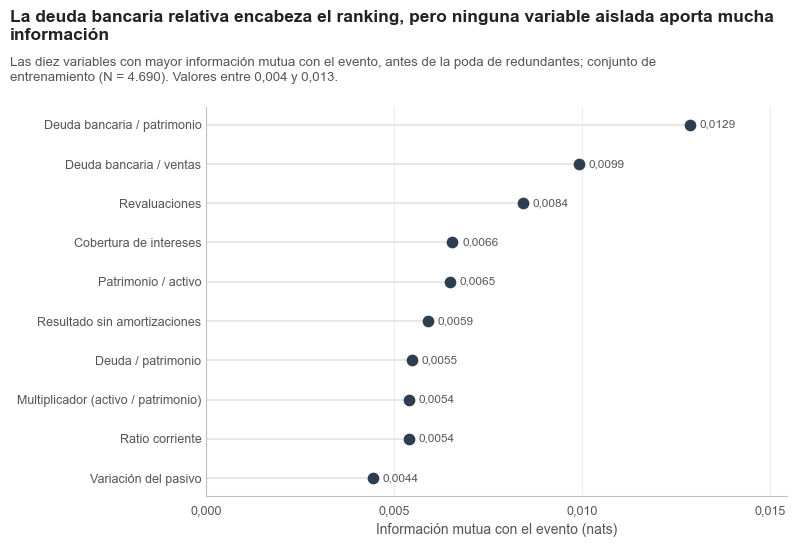

Guardada: graficos_tesis/fig_3_1_informacion_mutua.png


In [55]:
# Figura 3.1 — Informacion mutua: el mismo ranking que el texto (mi_series, celda cc513df2)
_mi = mi_series.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(_mi.values, range(len(_mi)), s=55, color=OSCURO, zorder=3)
for i, v in enumerate(_mi.values):
    ax.plot([0, v], [i, i], color='#E5E5E5', lw=1.3, zorder=1)
    ax.text(v + _mi.max() * 0.02, i, formato_coma(v, 4), va='center', fontsize=8.5, color=GRIS_TXT)
ax.set_yticks(range(len(_mi)))
ax.set_yticklabels([nombre_variable(f) for f in _mi.index], fontsize=9)
ax.set_xlim(0, _mi.max() * 1.2)
eje_decimal_coma(ax, 'x', 3)
ax.set_xlabel('Información mutua con el evento (nats)', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
ax.tick_params(axis='y', length=0)
_top2 = [nombre_variable(f).lower() for f in mi_series.index[:2]]
guardar_figura(fig,
          f'La deuda bancaria relativa encabeza el ranking, pero ninguna variable aislada aporta mucha información'
          if all('deuda bancaria' in t for t in _top2) else
          f'{nombre_variable(mi_series.index[0])} encabeza el ranking, pero ninguna variable aislada aporta mucha información',
          f'Las diez variables con mayor información mutua con el evento, antes de la poda de redundantes; '
          f'conjunto de entrenamiento (N = {formato_coma(len(df_train), 0)}). Valores entre {formato_coma(_mi.min(), 3)} y {formato_coma(_mi.max(), 3)}.',
          f'Fuente: {FUENTE_EC}, información cualitativa del BROU y {FUENTE_CR}.\n'
          'Notas: estimador por vecinos más cercanos (k = 5). Con valores tan bajos y próximos, el orden dentro del grupo '
          'cambia con pequeñas variaciones de la muestra y no debe leerse como una jerarquía estricta.',
          'fig_3_1_informacion_mutua.png')


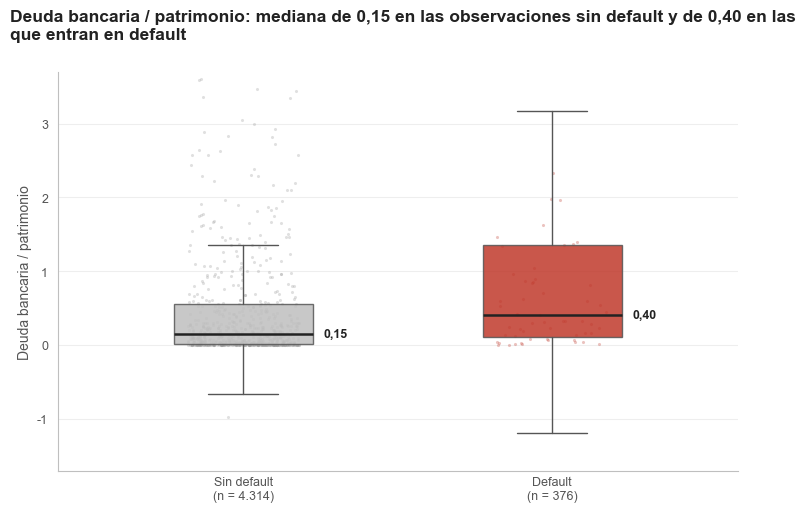

In [56]:
# Distribucion por clase — variable #1 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[0], rank=1)


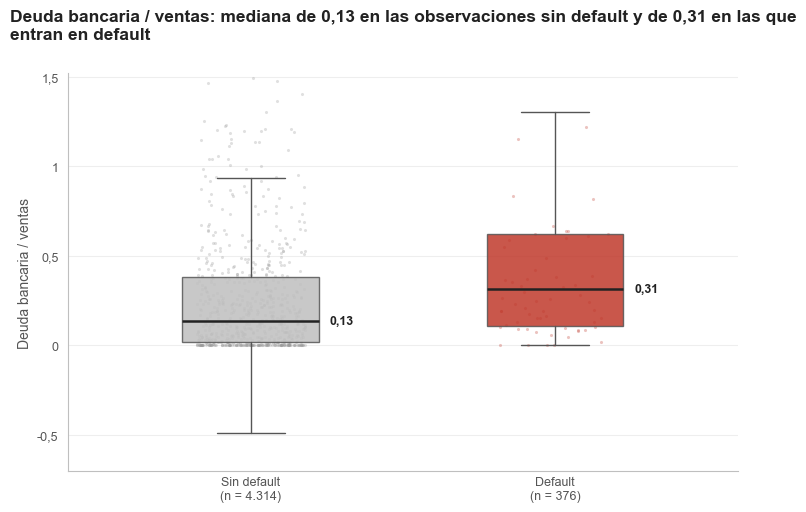

In [57]:
# Distribucion por clase — variable #2 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[1], rank=2)


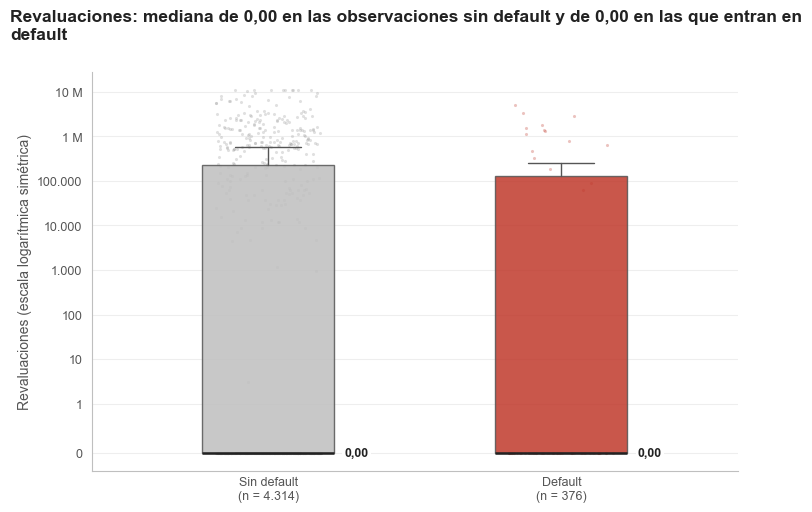

In [58]:
# Distribucion por clase — variable #3 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[2], rank=3)


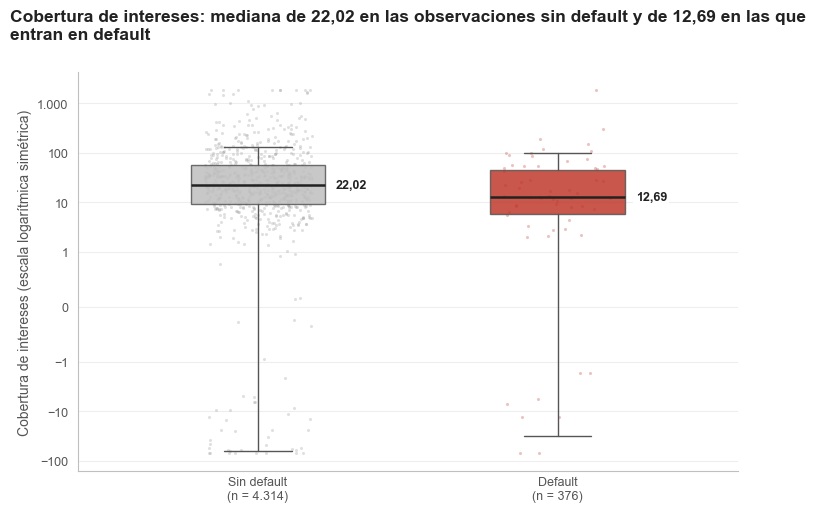

In [59]:
# Distribucion por clase — variable #4 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[3], rank=4)


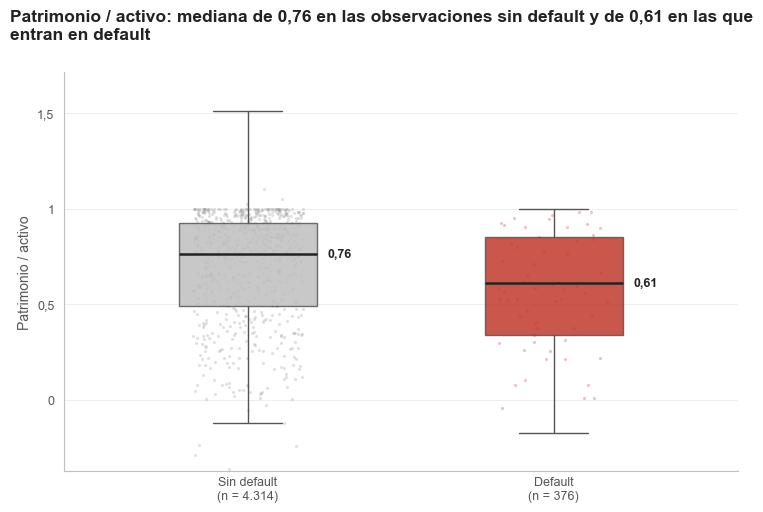

In [60]:
# Distribucion por clase — variable #5 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[4], rank=5)


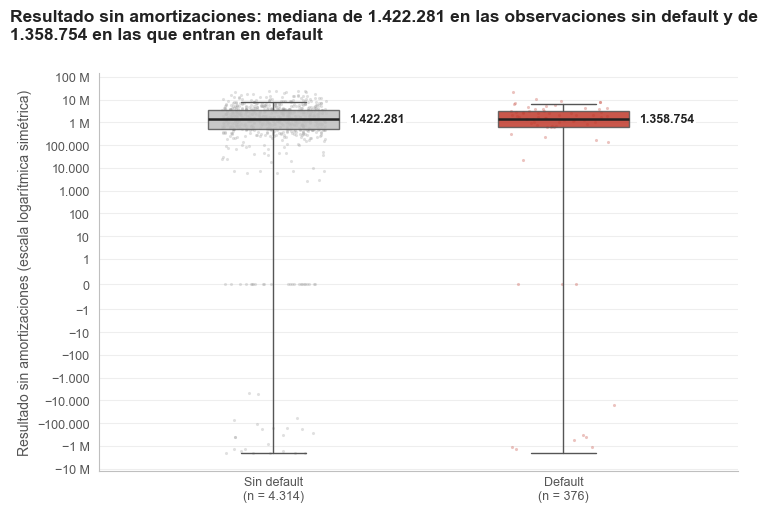

In [61]:
# Distribucion por clase — variable #6 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[5], rank=6)


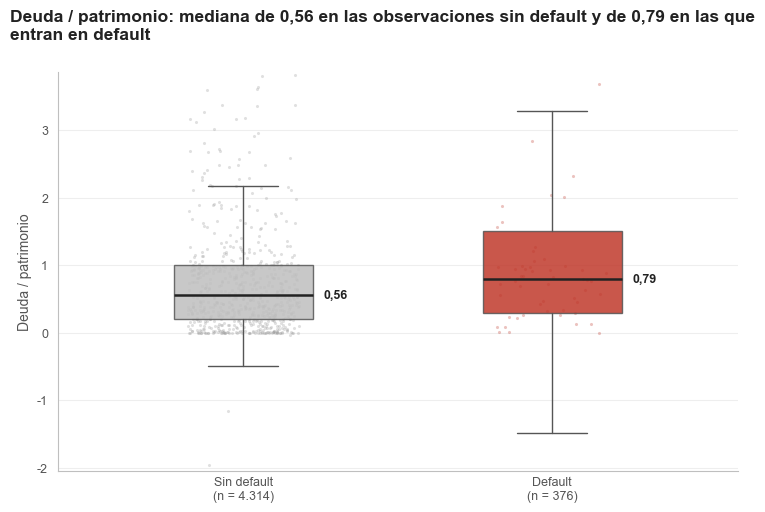

In [62]:
# Distribucion por clase — variable #7 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[6], rank=7)


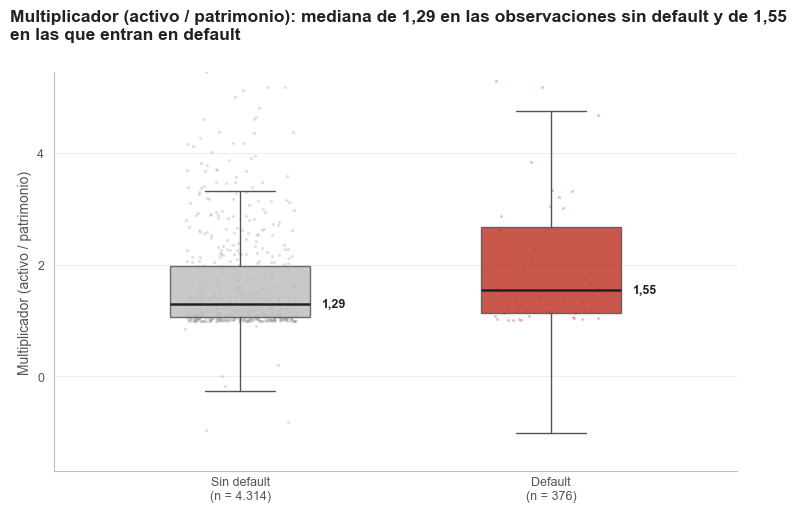

In [63]:
# Distribucion por clase — variable #8 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[7], rank=8)


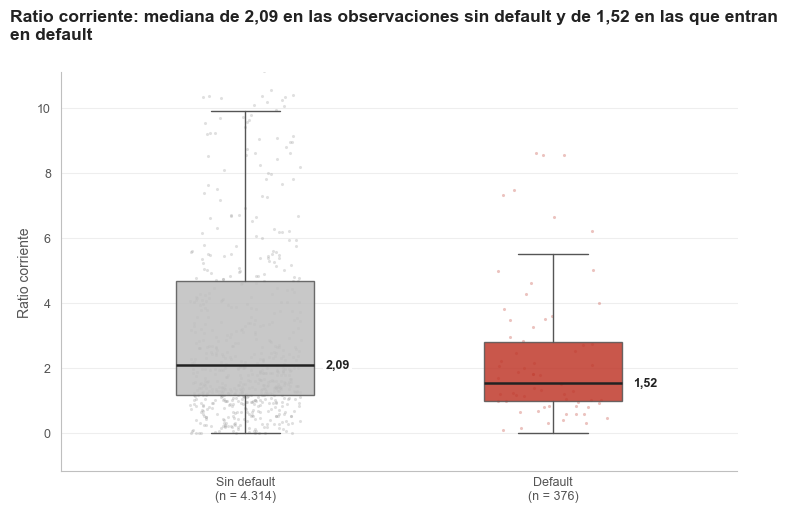

In [64]:
# Distribucion por clase — variable #9 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[8], rank=9)


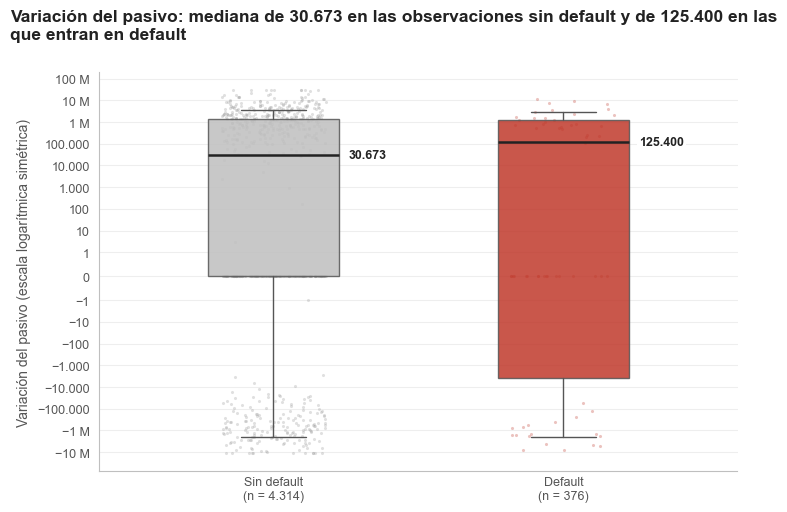

In [65]:
# Distribucion por clase — variable #10 del ranking por informacion mutua
grafico_distribucion_clase(df_train, target_eda, top10_eda[9], rank=10)


In [66]:
# Asimetria y valores extremos (fuera de P1-P99) de las variables numericas en train
outlier_summary = []
for col in cols_num_eda:
    data = df_train[col].dropna()
    if len(data) < 10:
        continue
    lo, hi = data.quantile([0.01, 0.99])
    n_out = ((data < lo) | (data > hi)).sum()
    skew = data.skew()
    kurt = data.kurtosis()
    outlier_summary.append({
        'Feature': col,
        'N_out_P1P99': n_out,
        'Pct_out': round(n_out / len(data) * 100, 1),
        'Skew': round(skew, 2),
        'Kurtosis': round(kurt, 1),
    })
outlier_df = pd.DataFrame(outlier_summary).sort_values('Skew', key=abs, ascending=False)

print(f'\nFeatures analizadas: {len(outlier_df)} de {len(cols_num_eda)}')
print(f'\nTop 10 mas sesgadas (|skew| alto = candidatas a log/winsorizar):')
print(outlier_df.head(10).to_string(index=False))
print(f'\nFeatures bien comportadas (|skew| < 1): {(outlier_df["Skew"].abs() < 1).sum()}')
print(f'Features muy sesgadas (|skew| > 5):    {(outlier_df["Skew"].abs() > 5).sum()}')

# ¿Una sola observacion domina los momentos? Con n obs., |skew| <= ~sqrt(n) y kurtosis <= ~n:
# si se alcanza el maximo, un unico valor extremo determina la distribucion.
print('\nTop 5 por |skew|: fila del valor mas extremo y momentos sin ella')
for col in outlier_df.head(5)['Feature']:
    data = df_train[col].dropna().astype(float)
    idx_ext = (data - data.median()).abs().idxmax()
    sin_ext = data.drop(idx_ext)
    print(f'  {col:35s} n={len(data):,}  sqrt(n)={np.sqrt(len(data)):.1f}  fila={idx_ext}  '
          f'skew {data.skew():+.1f} -> {sin_ext.skew():+.1f}  kurt {data.kurtosis():.0f} -> {sin_ext.kurtosis():.0f}')



Features analizadas: 162 de 162

Top 10 mas sesgadas (|skew| alto = candidatas a log/winsorizar):
                                   Feature  N_out_P1P99  Pct_out   Skew  Kurtosis
                              Margen_Bruto           66      1.5 -60.30    3953.5
                     Depositos en Garantia           29      0.6  56.75    3490.3
                          Margen_Operativo           92      2.0 -56.66    3567.9
                  Importe_sobre_Patrimonio           92      2.0  55.28    3335.4
                               Margen_Neto           92      2.0 -55.20    3392.8
                                 Ratio_GAV           61      1.4  50.27    3022.1
TIPO_SOCIEDAD_Sociedad en Comandita Simple            2      0.0  48.41    2342.5
      - Otros Resultados- Extraordinarios.           55      2.0 -48.32    2446.4
                      Importe_sobre_Ventas           62      1.4 -43.80    2523.4
                            Ratio_Efectivo           48      1.1  43.46    2191.6

In [67]:
# Seccion 2.3: en los tres margenes, el valor mas extremo es la misma observacion de entrenamiento, con ingresos
# operativos casi nulos. Cifras del texto: los ingresos de esa observacion y la asimetria y curtosis sin ella.
_ext = {}
for c in ['Margen_Bruto', 'Margen_Operativo', 'Margen_Neto']:
    x = df_train[c].replace([np.inf, -np.inf], np.nan).dropna().astype(float)
    i = (x - x.median()).abs().idxmax()
    s = x.drop(i)
    _ext[c] = i
    print(f'{c:18s} fila {i}  valor {x[i]:,.1f}  asimetria {x.skew():+.1f} -> {s.skew():+.1f}  '
          f'curtosis {x.kurtosis():,.1f} -> {s.kurtosis():,.1f}')
assert len(set(_ext.values())) == 1, 'El valor mas extremo no es la misma observacion en los tres margenes'
_fila = next(iter(_ext.values()))
print(f"\nObservacion {_fila}: Total Ingresos Operativos = {df_train.loc[_fila, 'Total Ingresos Operativos']:,.0f} pesos")


Margen_Bruto       fila 2693  valor -165.4  asimetria -60.3 -> +26.9  curtosis 3,953.5 -> 1,600.4
Margen_Operativo   fila 2693  valor -182.9  asimetria -56.7 -> -14.8  curtosis 3,567.9 -> 1,488.1
Margen_Neto        fila 2693  valor -188.6  asimetria -55.2 -> -27.7  curtosis 3,392.8 -> 1,988.4

Observacion 2693: Total Ingresos Operativos = 15,062 pesos


Ratio_Corriente: n = 4,257, asimetria 32.38, valor mas extremo 4,065.0 (fila 4247)
Ratio_Efectivo: n = 4,257, asimetria 43.46, valor mas extremo 1,453.2 (fila 10676)


Text(0, 0.5, 'Observaciones')

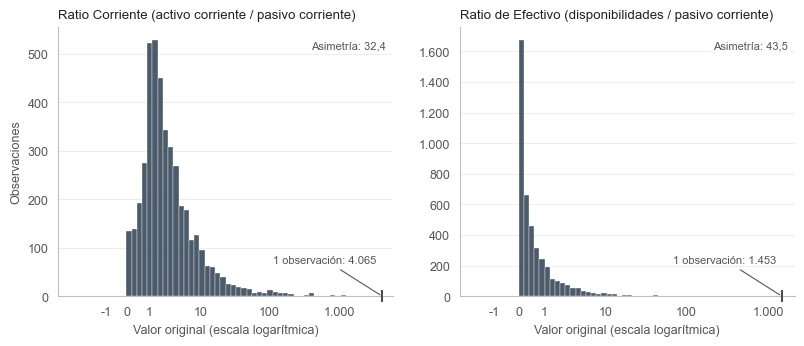

In [68]:
# Figura 2.7 — Asimetria de dos variables de liquidez en escala logaritmica (Figura 8 de la tesis, seccion 2.3).
# Solo los datos originales de entrenamiento: el recorte IQR y Yeo-Johnson son preprocesamiento (capitulo 3).
# La escala signo(x)·log10(1 + |x|) admite ceros y negativos. Se marca la observacion mas alejada de la mediana.
_titulos = {'Ratio_Corriente': 'Ratio Corriente (activo corriente / pasivo corriente)',
            'Ratio_Efectivo': 'Ratio de Efectivo (disponibilidades / pasivo corriente)'}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5), gridspec_kw={'wspace': 0.2})
for ax, c in zip(axes, _titulos):
    x = df_train[c].replace([np.inf, -np.inf], np.nan).dropna().astype(float)
    t = log_simetrico(x)
    ax.hist(t, bins=60, color=OSCURO, alpha=0.85, edgecolor='white', linewidth=0.3)
    iext = (x - x.median()).abs().idxmax()
    izq = x[iext] < x.median()
    ax.plot([t[iext]], [0], '|', color=OSCURO, markersize=9, markeredgewidth=1.3, clip_on=False, zorder=4)
    ax.annotate(f'1 observación: {formato_coma(x[iext], 0)}', xy=(t[iext], 0), xytext=(4 if izq else -4, 24),
                textcoords='offset points', ha='left' if izq else 'right', fontsize=8, color=GRIS_TXT,
                arrowprops=dict(arrowstyle='-', color=GRIS_TXT, lw=0.8))
    lo, hi = t.min() - 0.15, t.max() + 0.15
    tk = [v for v in [-1000, -100, -10, -1, 0, 1, 10, 100, 1000] if lo <= log_simetrico(v) <= hi]
    ax.set_xticks([log_simetrico(v) for v in tk]); ax.set_xticklabels([formato_coma(v, 0) for v in tk])
    ax.set_xlim(lo, hi)
    ax.set_title(_titulos[c], fontsize=9.5, color='#222222', loc='left')
    ax.text(0.98, 0.95, f'Asimetría: {formato_coma(x.skew(), 1)}', transform=ax.transAxes, ha='right', va='top',
            fontsize=8, color=GRIS_TXT, bbox=CAJA)
    limpiar_ejes(ax, grid='y')
    ax.set_xlabel('Valor original (escala logarítmica)', color=GRIS_TXT, fontsize=9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: formato_coma(v, 0)))
    print(f'{c}: n = {len(x):,}, asimetria {x.skew():.2f}, valor mas extremo {x[iext]:,.1f} (fila {iext})')
axes[0].set_ylabel('Observaciones', color=GRIS_TXT, fontsize=9)



In [69]:
# Analisis general del dataset

num_cols_eda = df_train.select_dtypes(include='number').columns.drop('DEFAULT_FUTURE', errors='ignore').tolist()
cat_cols_eda = [c for c in cols_categoricas if c in df_train.columns]

print(f"Shape: {df_train.shape[0]:,} filas x {df_train.shape[1]} columnas")
print(f"  Features numericas: {len(num_cols_eda)}")
print(f"  Features categoricas: {len(cat_cols_eda)} ({', '.join(cat_cols_eda)})")
print(f"  Empresas unicas (RUT): {df_train['RUT'].nunique():,}")
print(f"  Default rate: {df_train['DEFAULT_FUTURE'].mean():.2%}")

n_dup = df_train.duplicated().sum()
n_dup_no_id = df_train.drop(columns=['RUT', 'FECHA_dt'], errors='ignore').duplicated().sum()
print(f"\nDuplicados exactos (todas las columnas): {n_dup} ({n_dup/len(df_train)*100:.2f}%)")
print(f"Duplicados sin RUT/FECHA_dt:              {n_dup_no_id} ({n_dup_no_id/len(df_train)*100:.2f}%)")

# (c) Cobertura temporal
obs_by_month = df_train['FECHA_dt'].dt.to_period('M').value_counts().sort_index()
all_months = pd.period_range(obs_by_month.index.min(), obs_by_month.index.max(), freq='M')

print(f"\nCobertura temporal:")
print(f"  Primer periodo: {obs_by_month.index.min()}")
print(f"  Ultimo periodo: {obs_by_month.index.max()}")


if 'SECTOR' in df_train.columns:
    print(f"\nMix sectorial:")
    for sector, group in df_train.groupby('SECTOR'):
        print(f"  {sector}: {len(group):,} obs ({len(group)/len(df_train)*100:.1f}%), "
              f"{group['RUT'].nunique():,} empresas, "
              f"default rate {group['DEFAULT_FUTURE'].mean():.2%}")



Shape: 4,690 filas x 170 columnas
  Features numericas: 162
  Features categoricas: 4 (TIPO_SOCIEDAD, ACTIVIDAD_ECONOMICA, tamaño_EMPRESA, SECTOR)
  Empresas unicas (RUT): 2,547
  Default rate: 8.02%

Duplicados exactos (todas las columnas): 0 (0.00%)
Duplicados sin RUT/FECHA_dt:              14 (0.30%)

Cobertura temporal:
  Primer periodo: 2019-11
  Ultimo periodo: 2022-07

Mix sectorial:
  Agro: 1,972 obs (42.0%), 1,239 empresas, default rate 8.27%
  Empresas: 2,718 obs (58.0%), 1,313 empresas, default rate 7.84%


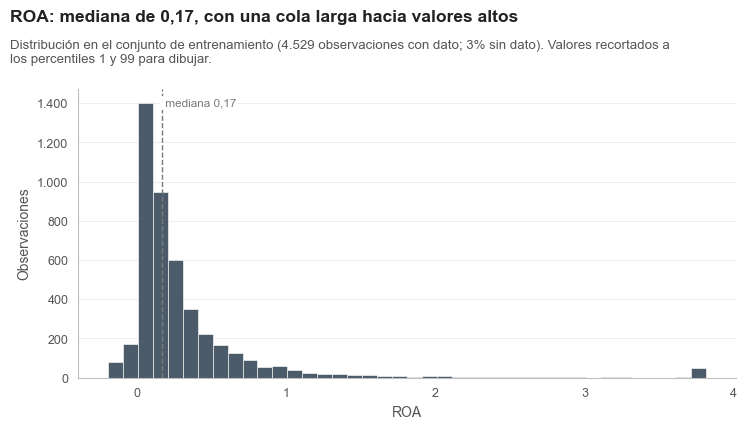

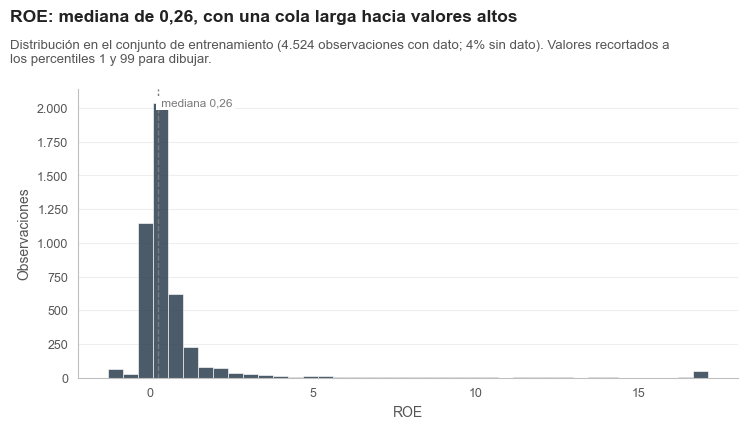

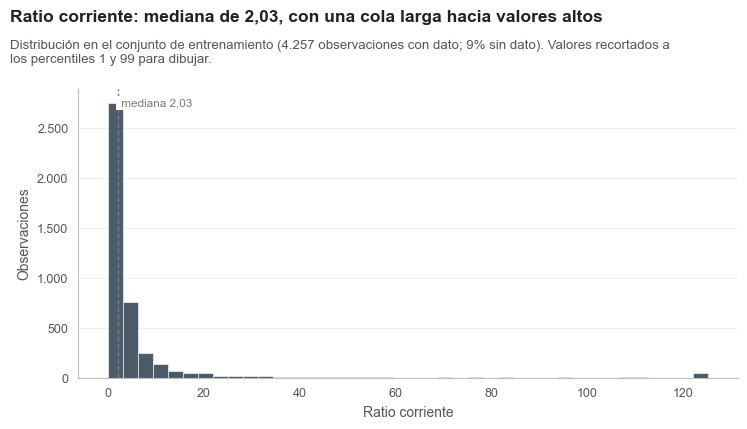

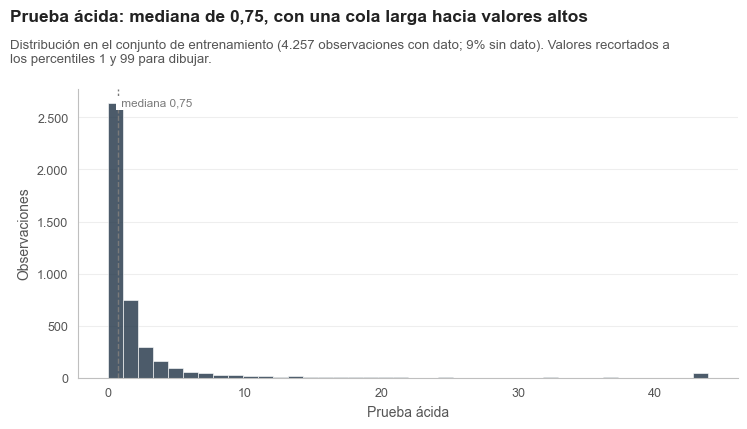

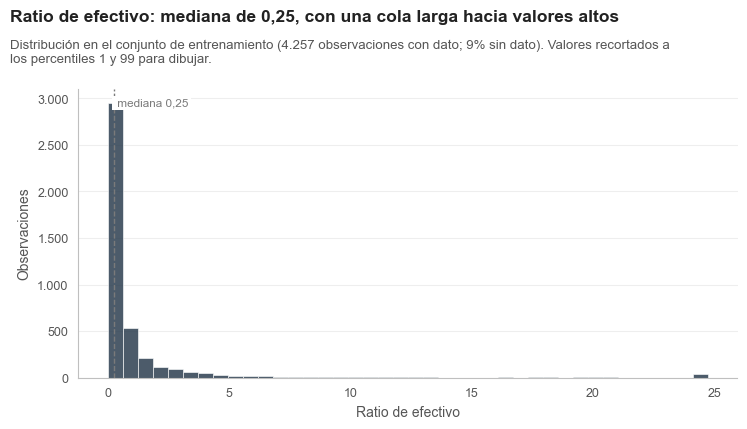

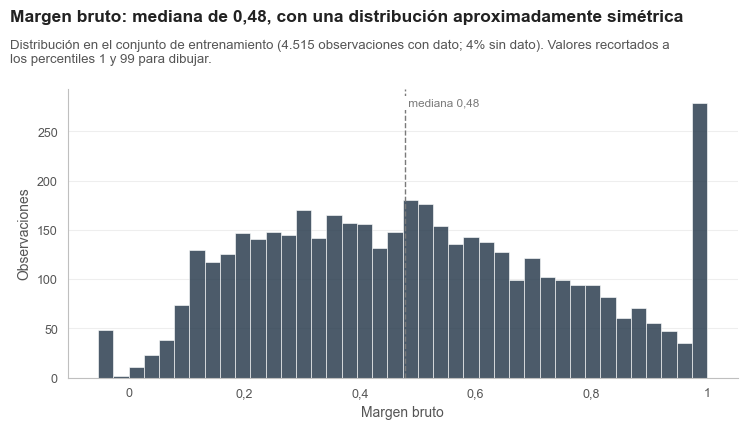

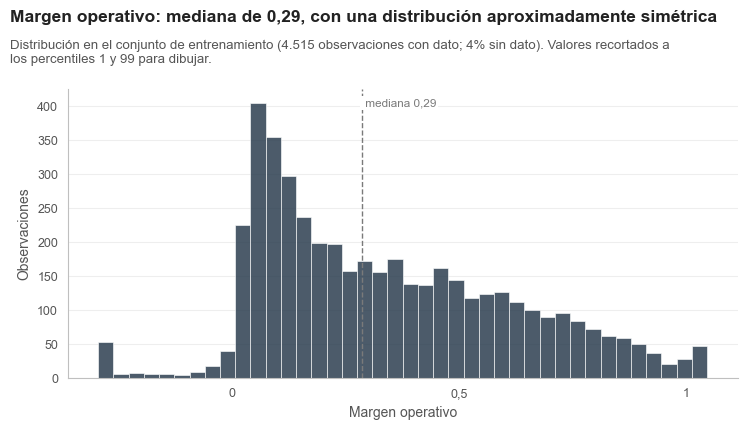

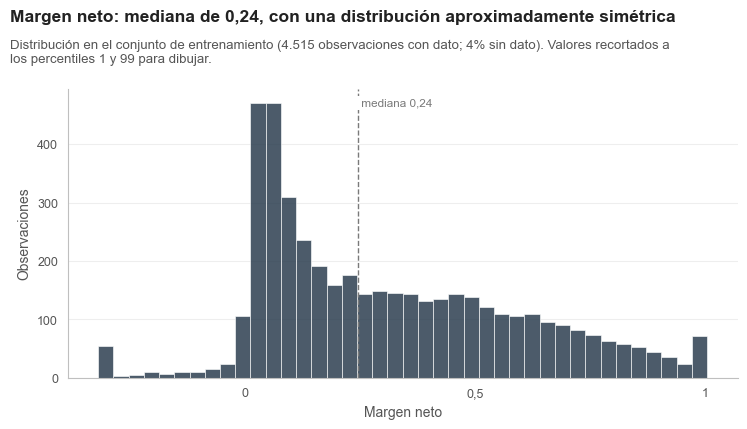

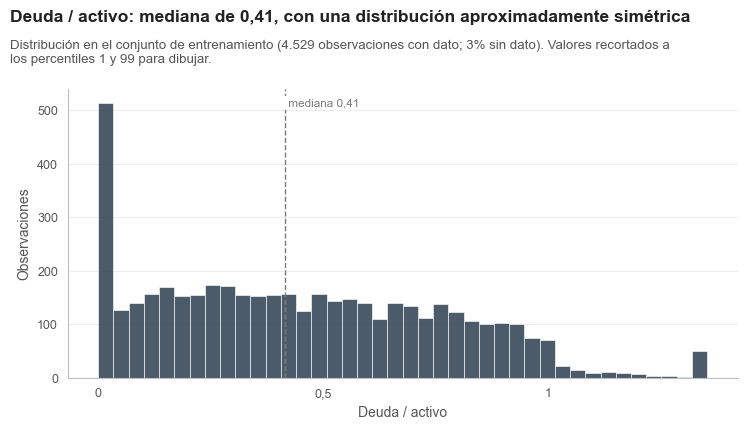

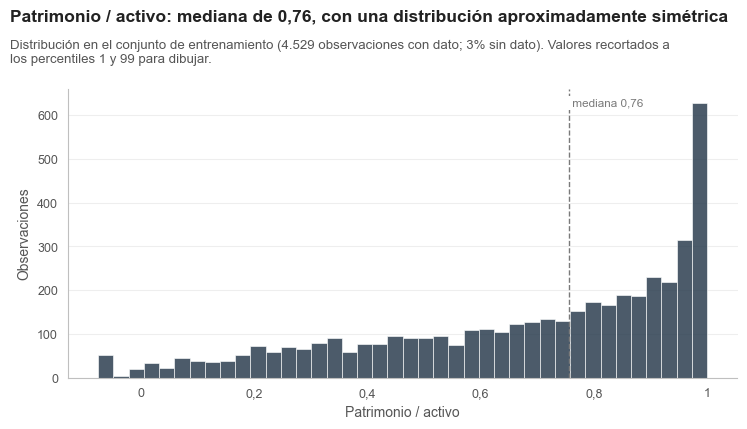

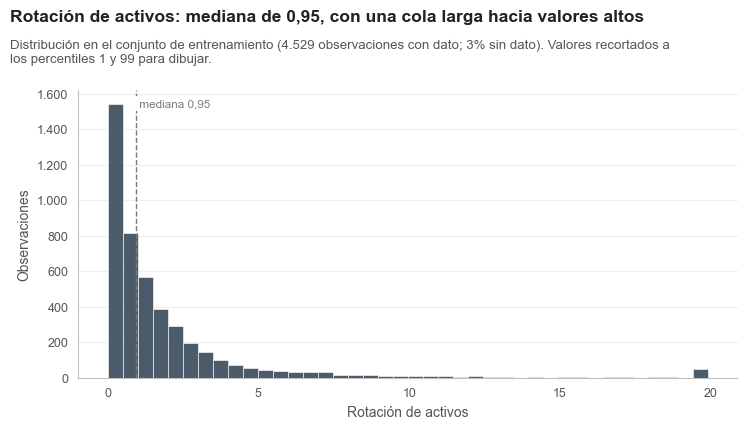

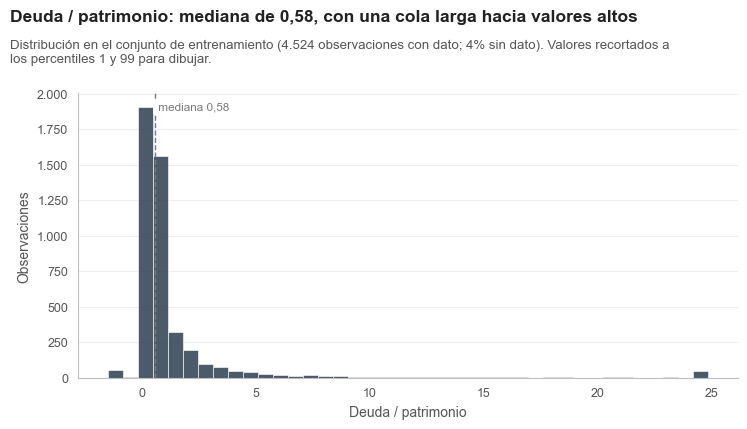

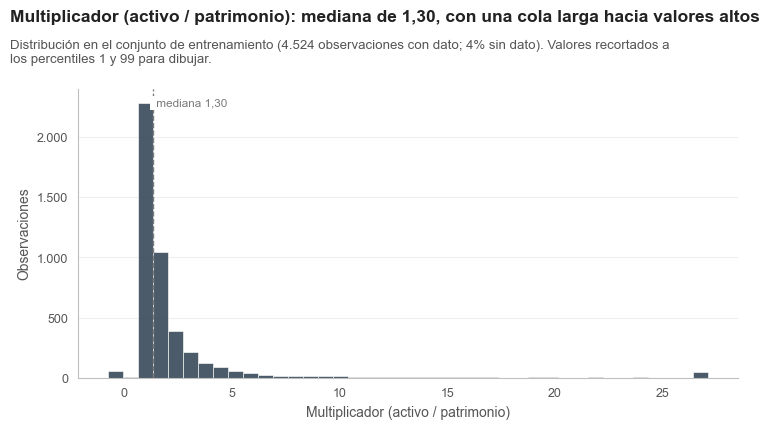

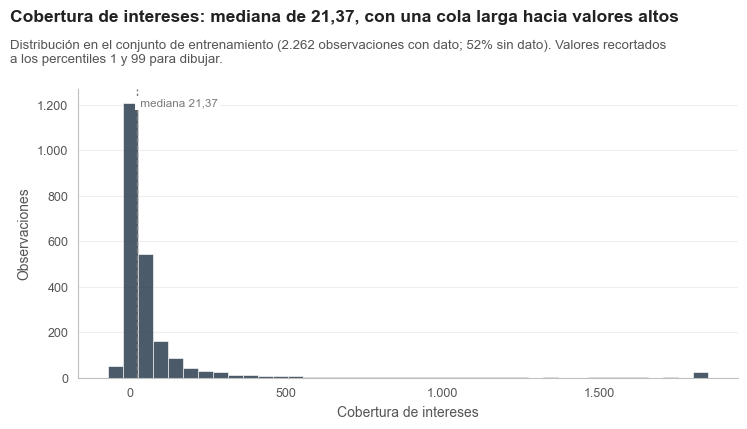

In [70]:
# Se grafican los ratios financieros
ratio_cols = [c for c in ['ROA', 'ROE', 'Ratio_Corriente', 'Prueba_Acida', 'Ratio_Efectivo',                                                   
                            'Margen_Bruto', 'Margen_Operativo', 'Margen_Neto', 'Margen_EBITDA',                                                 
                            'Deuda_sobre_Activos', 'Ratio_Patrimonio', 'Rotacion_Activos',                                                      
                            'Relacion_deuda_patrimonio', 'Multiplicador', 'Cobertura_de_intereses']                                             
                if c in df_train.columns]                                                                                                     
                                                                
for col in ratio_cols:
    data = df_train[col].dropna()
    if len(data) > 10:
        lo, hi = data.quantile([0.01, 0.99])
        clipped = data.clip(lo, hi)
        miss = df_train[col].isnull().mean() * 100
        _med, _sk = data.median(), clipped.skew()
        fig, ax = plt.subplots(figsize=(7.5, 3.6))
        ax.hist(clipped, bins=40, color=OSCURO, alpha=0.85, edgecolor='white', linewidth=0.5)
        ax.axvline(_med, color=REFERENCIA, ls='--', lw=1)
        ax.text(_med, ax.get_ylim()[1] * 0.97, f' mediana {formato_coma(_med, 2)}', color=REFERENCIA, fontsize=8.5,
                ha='left', va='top', bbox=CAJA)
        eje_decimal_coma(ax, 'x', 0)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: formato_coma(v, 0)))
        ax.set_xlabel(nombre_variable(col), color=GRIS_TXT)
        ax.set_ylabel('Observaciones', color=GRIS_TXT)
        limpiar_ejes(ax, grid='y')
        _cola = ('con una cola larga hacia valores altos' if _sk > 1 else
                 'con una cola larga hacia valores bajos' if _sk < -1 else 'con una distribución aproximadamente simétrica')
        guardar_figura(fig, f'{nombre_variable(col)}: mediana de {formato_coma(_med, 2)}, {_cola}',
                  f'Distribución en el conjunto de entrenamiento ({formato_coma(len(data), 0)} observaciones con dato; '
                  f'{formato_coma(miss, 0)}% sin dato). Valores recortados a los percentiles 1 y 99 para dibujar.', '', None)
# Se analizan los flags (indicadores de denominador = 0)
flag_cols = [c for c in df_train.columns if c.startswith('flag_')]
if flag_cols:                                                                                                                                  
    print("Activacion de flags (indicadores de denominador = 0):")
    flag_stats = []                                                                                                                            
    for fc in flag_cols:                                       
        rate = df_train[fc].mean() * 100 if df_train[fc].notna().sum() > 0 else 0
        flag_stats.append({'flag': fc, 'activacion_%': rate})                                                                                 
    flag_df = pd.DataFrame(flag_stats).sort_values('activacion_%', ascending=False)
    display(flag_df.round(1))                                                                                                                  
                                                                
    high_flags = flag_df[flag_df['activacion_%'] > 50]                                                                                       
    if len(high_flags) > 0:                                    
        print(f"\nFlags con >50% activacion (ratio asociado tiene poca senal):")                                                                
        for _, row in high_flags.iterrows():
            print(f"  {row['flag']}: {row['activacion_%']:.1f}%")


In [71]:
# Se calcula la tasa de default por decil para el top 10 de features por Mutual Information
print("Chequeo monoticidad")
print(f"{'Feature':40s} {'Monotona':10s} {'Direccion':12s} {'Breaks':8s}")
for col in top10_eda:
    d = df_train[[col, 'DEFAULT_FUTURE']].dropna().copy()
    if len(d) < 50 or d[col].nunique() < 2:
        continue
    try:
        d['bin'] = pd.qcut(d[col].rank(method='first'), 10, labels=False, duplicates='drop')
        rates = d.groupby('bin')['DEFAULT_FUTURE'].mean()
        diffs = rates.diff().dropna()
        n_pos = (diffs > 0).sum()
        n_neg = (diffs < 0).sum()
        is_mono = n_pos <= 1 or n_neg <= 1
        direction = 'Creciente' if n_pos > n_neg else 'Decreciente'
        breaks = min(n_pos, n_neg)
        print(f"{col:40s} {'Si' if is_mono else 'NO':10s} {direction:12s} {breaks:8d}")
    except Exception:
        pass


Chequeo monoticidad
Feature                                  Monotona   Direccion    Breaks  
Importe_sobre_Patrimonio                 NO         Creciente           2
Importe_sobre_Ventas                     NO         Creciente           3
Revaluaciones                            NO         Creciente           4
Cobertura_de_intereses                   NO         Decreciente         4
Ratio_Patrimonio                         NO         Decreciente         2
Resultado Sin Amortizaciones             NO         Creciente           4
Relacion_deuda_patrimonio                NO         Decreciente         4
Multiplicador                            NO         Creciente           4
Ratio_Corriente                          NO         Decreciente         4
delta_Pasivo                             NO         Decreciente         2


In [72]:
# Rubro mas grave alcanzado en la ventana [t+1, t+12] por los eventos de entrenamiento (la Figura 1.y usa _grav_mes)
# (el target se define con los rubros de atraso de la Central, no con la calificacion)
ORDEN_RUBRO = ['F_COL_VENCIDA', 'F_GESTION', 'F_MOROSOS', 'F_CAST_ATRASO']   # de menor a mayor gravedad
ETQ_RUBRO = {'F_COL_VENCIDA': 'Colocación vencida', 'F_GESTION': 'Créditos en gestión',
             'F_MOROSOS': 'Créditos morosos', 'F_CAST_ATRASO': 'Castigado por atraso'}
_cm = _central_mensual[['ID_CLIENTE', 'YEAR_MONTH'] + ORDEN_RUBRO].copy()
_cm['periodo'] = pd.PeriodIndex(_cm['YEAR_MONTH'], freq='M')
_cm['grav'] = 0
for k, f in enumerate(ORDEN_RUBRO, start=1):
    _cm.loc[_cm[f].astype(bool), 'grav'] = k            # se queda con el rubro mas grave del mes
_grav_mes = dict(zip(zip(_cm['ID_CLIENTE'].astype(str), _cm['periodo']), _cm['grav']))

_ev = df_train.loc[df_train['DEFAULT_FUTURE'] == 1, ['RUT', 'FECHA_dt']].copy()
_ev['p0'] = _ev['FECHA_dt'].dt.to_period('M') + OFFSET_VENTANA
_ev['peor'] = [max(_grav_mes.get((str(r), p + k), 0) for k in range(12)) for r, p in zip(_ev['RUT'], _ev['p0'])]
assert (_ev['peor'] > 0).all(), 'todo evento debe tener al menos un rubro de atraso en la ventana'
_rub = _ev['peor'].value_counts().reindex(range(1, 5), fill_value=0)
_rub.index = ORDEN_RUBRO
_frac = _rub / _rub.sum()
print(pd.DataFrame({'n': _rub, 'pct': (_frac * 100).round(1)}))
_sup = _frac.iloc[1:].sum()


                 n   pct
F_COL_VENCIDA  303  80.6
F_GESTION       47  12.5
F_MOROSOS       26   6.9
F_CAST_ATRASO    0   0.0


                  n    pct
SIN            4314  91.98
F_COL_VENCIDA   303   6.46
F_GESTION        47   1.00
F_MOROSOS        26   0.55
F_CAST_ATRASO     0   0.00


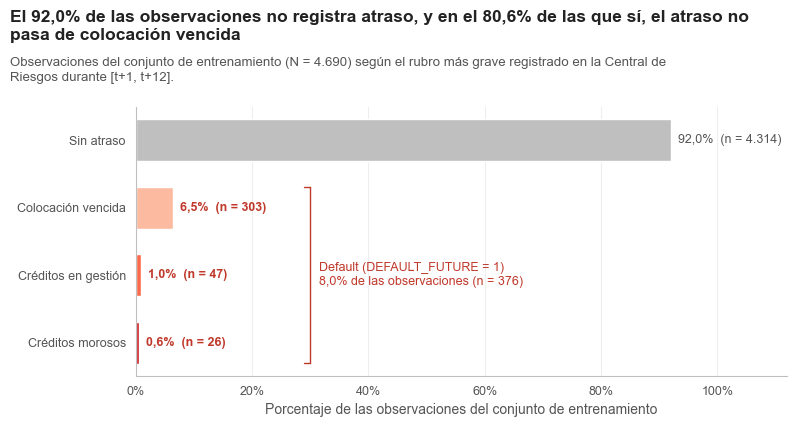

Guardada: graficos_tesis/fig_1_y_rubros_train.png


In [73]:
# Figura 1.y — Variable objetivo en entrenamiento segun el rubro mas grave alcanzado en [t+1, t+12]
# (desbalance y gravedad del evento en una sola figura; reusa _grav_mes, ORDEN_RUBRO y ETQ_RUBRO de narr_f5b_rubros)
_tr = df_train[['RUT', 'FECHA_dt', 'DEFAULT_FUTURE']].copy()
_tr['p0'] = _tr['FECHA_dt'].dt.to_period('M') + OFFSET_VENTANA
_tr['peor'] = [max(_grav_mes.get((str(r), p + k), 0) for k in range(12)) for r, p in zip(_tr['RUT'], _tr['p0'])]
assert ((_tr['peor'] > 0) == (_tr['DEFAULT_FUTURE'] == 1)).all(), 'el rubro debe coincidir con DEFAULT_FUTURE'
_cats = ['SIN'] + ORDEN_RUBRO
_etq = {'SIN': 'Sin atraso', **ETQ_RUBRO}
_n = _tr['peor'].value_counts().reindex(range(0, 5), fill_value=0)
_n.index = _cats
_f = _n / len(_tr)
print(pd.DataFrame({'n': _n, 'pct': (_f * 100).round(2)}))
_tasa = _f.iloc[1:].sum()
_sin_cast = _n['F_CAST_ATRASO'] == 0          # el castigo exige mas de 2 anos de atraso: inalcanzable en la ventana
_colores = [CONTEXTO] + SEC_RIESGO
if _sin_cast:
    _cats = _cats[:-1]
    _colores = _colores[:-1]
    _n, _f = _n[_cats], _f[_cats]
_venc_ev = _n['F_COL_VENCIDA'] / _n.iloc[1:].sum()

fig, ax = plt.subplots(figsize=(8, 3.4))
_y = np.arange(len(_cats))[::-1]
ax.barh(_y, _f.values, color=_colores, height=0.62)
for yy, (k, v) in zip(_y, _f.items()):
    ax.text(v + 0.012, yy, f'{formato_porcentaje(v)}  (n = {formato_coma(_n[k], 0)})', va='center', fontsize=9,
            color=GRIS_TXT if k == 'SIN' else ENFASIS, fontweight='normal' if k == 'SIN' else 'bold')
ax.set_yticks(_y)
ax.set_yticklabels([_etq[k] for k in _cats])
# llave que agrupa los rubros de atraso = DEFAULT_FUTURE = 1
_x0 = 0.30
ax.plot([_x0, _x0], [_y[-1] - 0.3, _y[1] + 0.3], color=ENFASIS, lw=1)
for yy in (_y[-1] - 0.3, _y[1] + 0.3):
    ax.plot([_x0 - 0.01, _x0], [yy, yy], color=ENFASIS, lw=1)
ax.text(_x0 + 0.015, (_y[1] + _y[-1]) / 2, f'Default (DEFAULT_FUTURE = 1)\n{formato_porcentaje(_tasa)} de las observaciones (n = {formato_coma(_n.iloc[1:].sum(), 0)})',
        va='center', ha='left', fontsize=9, color=ENFASIS)
ax.set_xlim(0, 1.12)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
eje_porcentaje(ax, 'x')
ax.set_xlabel('Porcentaje de las observaciones del conjunto de entrenamiento', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
guardar_figura(fig,
          f'El {formato_porcentaje(_f["SIN"])} de las observaciones no registra atraso, y en el {formato_porcentaje(_venc_ev)} de las que sí, '
          'el atraso no pasa de colocación vencida',
          f'Observaciones del conjunto de entrenamiento (N = {formato_coma(len(_tr), 0)}) según el rubro más grave registrado en la '
          'Central de Riesgos durante [t+1, t+12].',
          f'Fuente: {FUENTE_CR}.\nNotas: rubros ordenados de menor a mayor gravedad según el Marco Contable del BCU '
          '(Anexo 1); cada observación es un balance; se toma el rubro más grave en cualquier institución y mes de la ventana. Cualquier rubro de atraso '
          'define el default.' + (' No se muestra el castigo por atraso: exige más de dos años de atraso (fin del plazo de moroso) y ninguna '
             'observación lo alcanza dentro de la ventana.' if _sin_cast else ''),
          'fig_1_y_rubros_train.png')


In [74]:
# Poda de variables redundantes — antes de la imputacion y de toda seleccion.
# Chi2 e IV evaluan cada variable por separado y dejan pasar variables que dicen lo mismo,
# lo que reparte el efecto entre "gemelas" en los coeficientes y en LIME/SHAP.
# Regla: en cada grupo con |rho| >= 0.9 (Spearman sobre deciles de train) o con equivalencia
# contable se conserva UNA variable, elegida por criterio de dominio y SIN usar el target.
# Una sola forma de variacion temporal por variable (delta_).
# Todo lo posterior (imputacion, RFECV, IV, Chi2, outliers, CV anidada, export) hereda la lista.

UMBRAL_RHO = 0.9

REDUNDANTES = [
    # identidades contables y duplicados
    'TOTAL PASIVO Y PATRIMONIO',          # = TOTAL ACTIVO
    'Total Ingresos Operativos Netos',    # ~ Total Ingresos Operativos
    'Ventas Plaza', 'Exportaciones',      # componentes de los ingresos (queda Ratio_Exportaciones)
    '+(gan) -(pérd) Res Periodo',         # = Resultado Neto (100% en agro, 77% en empresas)
    # un solo resultado (Resultado Operativo se conserva: decision del autor)
    'Resultado Sin Amortizaciones',       # = Resultado Neto en agro
    # un ratio por concepto
    'Margen_Operativo',                   # gemela de Margen_Neto
    'Multiplicador',                      # gemela de Ratio_Patrimonio
    # sin variaciones de variables quitadas
    'delta_Res_SinAmort', 'delta_Res_Periodo', 'delta_MgnOp',
] + [c for c in X_train.columns if c.startswith('pct_chg_')]   # una sola variacion: delta_

_faltan = [c for c in REDUNDANTES if c not in X_train.columns]
assert not _faltan, f'Columnas a podar que no existen: {_faltan}'

_cand_antes = [c for c in X_train.select_dtypes(include='number').columns
               if X_train[c].nunique(dropna=True) > 1]
_pares_antes = pares_redundantes(X_train, _cand_antes, UMBRAL_RHO)

X_train = X_train.drop(columns=REDUNDANTES)
X_test  = X_test.drop(columns=REDUNDANTES)

_cand_despues = [c for c in X_train.select_dtypes(include='number').columns
                 if X_train[c].nunique(dropna=True) > 1]
_pares_despues = pares_redundantes(X_train, _cand_despues, UMBRAL_RHO)

print(f'Candidatas: {len(_cand_antes)} -> {len(_cand_despues)} (-{len(REDUNDANTES)} redundantes)')
print(f'Pares con |rho| >= {UMBRAL_RHO} (Spearman sobre deciles, train): '
      f'{len(_pares_antes)} antes -> {len(_pares_despues)} despues')
print('\nPares antes de la poda:')
print(_pares_antes.round(3).to_string())
if len(_pares_despues):
    print('\nPares que quedan despues de la poda:')
    print(_pares_despues.round(3).to_string())

Candidatas: 161 -> 137 (-24 redundantes)
Pares con |rho| >= 0.9 (Spearman sobre deciles, train): 25 antes -> 3 despues

Pares antes de la poda:
Total Ingresos Operativos   Total Ingresos Operativos Netos    0.998
TOTAL ACTIVO                TOTAL PASIVO Y PATRIMONIO          0.996
delta_MgnOp                 pct_chg_MgnOp                      0.984
delta_ROA                   pct_chg_ROA                        0.981
Resultado Neto              Resultado Sin Amortizaciones       0.980
delta_ROE                   pct_chg_ROE                        0.979
delta_MgnNeto               pct_chg_MgnNeto                    0.979
delta_Res_SinAmort          delta_Res_Neto                     0.974
Margen_Operativo            Margen_Neto                        0.972
pct_chg_Res_SinAmort        pct_chg_Res_Neto                   0.965
delta_MgnBruto              pct_chg_MgnBruto                   0.959
Resultado Operativo         Resultado Sin Amortizaciones       0.958
                            

In [75]:
# Copia de los datos despues de la poda y ANTES de imputar. La usa la busqueda con todo el
# preprocesamiento dentro del pipeline, ahi la imputacion,
# la seleccion, los outliers, la transformacion y el balanceo se ajustan en cada particion.
# Las celdas que siguen hasta el entrenamiento (imputacion, outliers, RFECV, IV, Chi-cuadrado,
# correlaciones) quedan como analisis descriptivo del conjunto de entrenamiento.
_num_crudo = X_train.select_dtypes(include='number').columns
cols_pipe = [c for c in _num_crudo if X_train[c].nunique(dropna=True) > 1]
X_train_crudo = X_train[cols_pipe].replace([np.inf, -np.inf], np.nan).astype('float64')
X_test_crudo  = X_test[cols_pipe].replace([np.inf, -np.inf], np.nan).astype('float64')
assert 'Valor_UI' not in cols_pipe
print(f'Datos crudos para el pipeline: {X_train_crudo.shape[1]} variables candidatas, '
      f'{int(X_train_crudo.isna().sum().sum()):,} faltantes en entrenamiento')


Datos crudos para el pipeline: 137 variables candidatas, 88,052 faltantes en entrenamiento


In [76]:
# Imputacion y limpieza
# Imputer fit en train, transform en test. Sin leakage.
# Despues de esta celda X_train y X_test no tienen NaN ni inf.

num_cols = X_train.select_dtypes(include='number').columns
nonconst = [c for c in num_cols if X_train[c].nunique(dropna=True) > 1]
const    = [c for c in num_cols if c not in nonconst]

# Se eliminan columnas constantes (no aportan informacion)
if const:
    print(f"Columnas constantes eliminadas: {const}")
    X_train = X_train.drop(columns=const)
    X_test  = X_test.drop(columns=const)

# Se limpian inf -> NaN
X_train[nonconst] = X_train[nonconst].replace([np.inf, -np.inf], np.nan).astype('float64')
X_test[nonconst]  = X_test[nonconst].replace([np.inf, -np.inf], np.nan).astype('float64')

# Se imputan NaN con mediana (fit en train)
imp = SimpleImputer(strategy='median')
X_train[nonconst] = imp.fit_transform(X_train[nonconst])
X_test[nonconst]  = imp.transform(X_test[nonconst])

print(f"Imputacion completada: {len(nonconst)} columnas")
print(f"NaN restantes en X_train: {X_train.isna().sum().sum()}")
print(f"NaN restantes en X_test:  {X_test.isna().sum().sum()}")


Columnas constantes eliminadas: ['Resultado por Tenencia - NIC 41 -']
Imputacion completada: 137 columnas
NaN restantes en X_train: 0
NaN restantes en X_test:  0


## Tratamiento de Outliers

- Limites calculados solo en train
- 3 metodos comparados: Winsorization (P1/P99), IQR Clipping, Z-score Clipping.


In [77]:
# apply_outlier_treatment 

In [78]:
# Metodo 1: Winsorization (percentil 1/99)
# Se recortan percentiles 1 y 99 calculados en train.


X_train_winsor, X_test_winsor = apply_outlier_treatment(X_train[nonconst].values, X_test[nonconst].values, 'Winsorization')

n_clipped = np.sum(X_train_winsor != X_train[nonconst].values)
pct_clipped = n_clipped / X_train[nonconst].values.size * 100

print('Winsorization (P1/P99)')
print(f'Valores clippeados en train: {n_clipped:,} ({pct_clipped:.2f}%)')
print(f'Datos: {X_train_winsor.shape[0]} filas × {X_train_winsor.shape[1]} features')

Winsorization (P1/P99)
Valores clippeados en train: 6,869 (1.07%)
Datos: 4690 filas × 137 features


In [79]:
# Metodo 2: IQR clipping (Q1 - 1.5*IQR, Q3 + 1.5*IQR)
# Metodo estadistico clasico. Mas agresivo que Winsorization en distribuciones con colas largas (tipico de datos financieros).

X_train_iqr, X_test_iqr = apply_outlier_treatment(X_train[nonconst].values, X_test[nonconst].values, 'IQR')

# Se calculan estadisticas 
n_clipped = np.sum(X_train_iqr != X_train[nonconst].values)
pct_clipped = n_clipped / X_train[nonconst].values.size * 100

  
print('IQR clipping (Q1 - 1.5*IQR, Q3 + 1.5*IQR)')
  
print(f'Valores clippeados en train: {n_clipped:,} ({pct_clipped:.2f}%)')
print(f'Datos: {X_train_iqr.shape[0]} filas × {X_train_iqr.shape[1]} features')

# Se muestran las top 10 features mas afectadas
pcts_by_feat = np.sum(X_train_iqr != X_train[nonconst].values, axis=0) / X_train[nonconst].values.shape[0] * 100
feat_impact = pd.Series(pcts_by_feat, index=nonconst).sort_values(ascending=False).head(10)
print(f'\nTop 10 features mas afectadas:')
for feat, porc in feat_impact.items():
    print(f'  {feat:45s} {porc:6.2f}% clippeado')



IQR clipping (Q1 - 1.5*IQR, Q3 + 1.5*IQR)
Valores clippeados en train: 27,054 (4.21%)
Datos: 4690 filas × 137 features

Top 10 features mas afectadas:
  Ajustes al Patrim.                             30.77% clippeado
  Amortizaciones                                 22.77% clippeado
  - Dividendo Provisorio                         22.75% clippeado
  Bancos                                         19.89% clippeado
  Amort. Acumuladas                              19.66% clippeado
  Deudas BROU MNal.                              19.34% clippeado
  Impto. a la Renta                              19.19% clippeado
  Deudas Comercs                                 15.91% clippeado
  Deudas BROU MExt.                              15.71% clippeado
  Deudas Diversas                                15.25% clippeado


In [80]:
# Metodo 3: Z-score clipping (|z| > 3)
# Recorte a mean ± 3*std. Asume distribucion aproximadamente normal.

X_train_zscore, X_test_zscore = apply_outlier_treatment(X_train[nonconst].values, X_test[nonconst].values, 'Z-score')

# Se calculan estadisticas 
n_clipped = np.sum(X_train_zscore != X_train[nonconst].values)
pct_clipped = n_clipped / X_train[nonconst].values.size * 100

  
print('Z-score clipping (|z| > 3)')
  
print(f'Valores clippeados en train: {n_clipped:,} ({pct_clipped:.2f}%)')
print(f'Datos: {X_train_zscore.shape[0]} filas × {X_train_zscore.shape[1]} features')

# Se muestran las top 10 features mas afectadas
pcts_by_feat = np.sum(X_train_zscore != X_train[nonconst].values, axis=0) / X_train[nonconst].values.shape[0] * 100
feat_impact = pd.Series(pcts_by_feat, index=nonconst).sort_values(ascending=False).head(10)
print(f'\nTop 10 features mas afectadas:')
for feat, porc in feat_impact.items():
    print(f'  {feat:45s} {porc:6.2f}% clippeado')



Z-score clipping (|z| > 3)
Valores clippeados en train: 7,994 (1.24%)
Datos: 4690 filas × 137 features

Top 10 features mas afectadas:
  tamaño_EMPRESA_Mediana                          9.23% clippeado
  ACTIVIDAD_ECONOMICA_CUL.DE PROD.AGRI.EN COMB.CON CRIA DE ANIM. EXPLOT.MIXTA   8.25% clippeado
  ACTIVIDAD_ECONOMICA_TRANSPORTE DE CARGA POR CARRETERA   7.53% clippeado
  ACTIVIDAD_ECONOMICA_OTRAS ACTIVIDADES DE SERVICIOS N.C.P.   5.52% clippeado
  TIPO_SOCIEDAD_Sociedad de Hecho                 4.67% clippeado
  ACTIVIDAD_ECONOMICA_EXPLOTACION LECHERA         4.07% clippeado
  TIPO_SOCIEDAD_Otros                             3.60% clippeado
  PIB                                             3.11% clippeado
  ACTIVIDAD_ECONOMICA_SERVICIOS AGRICOLAS         2.84% clippeado
  Deudas BROU MExt.                               2.62% clippeado


## Feature Selection

Se aplican tres tecnicas de seleccion de features recomendadas en la literatura de credit scoring, chi-squared, RFECV e Information Value.

In [81]:
# RFECV MULTI-ESTIMATOR 


from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

cv_rfecv = GroupKFold(n_splits=5)  # sin shuffle -> deterministico; agrupado por RUT -> sin leakage de empresa
step_rfecv = 5
min_feat = 5

# X_train ya esta imputado por la celda principal de imputacion.
X_for_rfe = X_train[nonconst].copy()

scaler_rfe = StandardScaler()
X_for_rfe_scaled = pd.DataFrame(
    scaler_rfe.fit_transform(X_for_rfe),
    columns=nonconst, index=X_for_rfe.index,
)

# scale_pos_weight para XGB
spw_rfecv = (y_train == 0).sum() / max((y_train == 1).sum(), 1)


print(f'  Folds: 5 (GroupKFold), step={step_rfecv}, min_feat={min_feat}')
print(f'  Features de entrada: {len(nonconst)}')
print(f'  Estimadores: RF, LR-L2 (C=1.0), XGB (cada uno en su celda)')


  Folds: 5 (GroupKFold), step=5, min_feat=5
  Features de entrada: 137
  Estimadores: RF, LR-L2 (C=1.0), XGB (cada uno en su celda)


In [82]:
# RFECV con Random Forest

rfecv_RF_estimator = RandomForestClassifier(
    n_estimators=100, max_depth=8, min_samples_leaf=50,
    class_weight='balanced', random_state=42, n_jobs=1,
)
rfecv_RF = ejecutar_rfecv('RF', rfecv_RF_estimator, X_for_rfe, y_train, grupos_train, nonconst, cv_rfecv, step_rfecv, min_feat)


  RF:
    Optimo:    107 feats, AUC=0.6822 ± 0.0348
    Tiempo:    18.1s


In [83]:
# RFECV con LR
# Esta lista la usan los combos con RFECV de la LR y del MLP
rfecv_LR_estimator = LogisticRegression(
    penalty='l2', solver='liblinear', C=1.0,
    class_weight='balanced', max_iter=1000, random_state=42,
)
rfecv_LR = ejecutar_rfecv('LR', rfecv_LR_estimator, X_for_rfe_scaled, y_train, grupos_train, nonconst, cv_rfecv, step_rfecv, min_feat)


  LR:
    Optimo:     22 feats, AUC=0.6369 ± 0.0430
    Tiempo:    4.6s


In [84]:
# RFECV con XGBoost
# Esta lista la usan los combos con RFECV del XGB
rfecv_XGB_estimator = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
    reg_alpha=1.0, reg_lambda=5.0, gamma=0.5,
    scale_pos_weight=spw_rfecv, eval_metric='logloss',
    random_state=42, n_jobs=1,
)
rfecv_XGB = ejecutar_rfecv('XGB', rfecv_XGB_estimator, X_for_rfe, y_train, grupos_train, nonconst, cv_rfecv, step_rfecv, min_feat)


  XGB:
    Optimo:     42 feats, AUC=0.6531 ± 0.0271
    Tiempo:    9.7s


In [85]:
rfecv_results = {
    'RF':    rfecv_RF,
    'LR': rfecv_LR,
    'XGB':   rfecv_XGB,
}



In [86]:
# Calibracion del umbral de IV por ruido muestral.
# El IV tiene sesgo positivo: con B bins y pocos eventos, una feature SIN
# relacion con el target registra IV espurio ~ (B-1)*(1/n_bads + 1/n_goods).

_rng_iv = np.random.default_rng(42)
_y_sim = y_train.values.astype(float)
_ivs_ruido = []
for _ in range(500):
    _x_ruido = _rng_iv.normal(size=len(_y_sim))
    _iv_r, _tab = calc_iv_train(_x_ruido, _y_sim)
    _ivs_ruido.append(_iv_r)
_ivs_ruido = np.array(_ivs_ruido)

pct_ruido_002 = float((_ivs_ruido >= 0.02).mean() * 100)
pct_ruido_010 = float((_ivs_ruido >= 0.10).mean() * 100)
p95_ruido = float(np.percentile(_ivs_ruido, 95))
max_ruido = float(_ivs_ruido.max())

print(f"IV de 500 features de ruido puro (N={len(_y_sim):,}, {int(_y_sim.sum())} eventos, 10 bins):")
print(f"  media: {_ivs_ruido.mean():.4f} | mediana: {np.median(_ivs_ruido):.4f} | "
      f"p95: {p95_ruido:.4f} | max: {max_ruido:.4f}")
print(f"  % de ruido que supera 0.02 (umbral Siddiqi): {pct_ruido_002:.0f}%")
print(f"  % de ruido que supera 0.10 (umbral adoptado): {pct_ruido_010:.0f}%")
# Conclusion construida desde los datos (antes tenia un 84% escrito a mano de un run
# anterior, que contradecia el valor calculado arriba; #30).
print(f"\nConclusion: 0.02 esta DEBAJO del piso de ruido a esta escala muestral "
      f"(lo supera el {pct_ruido_002:.0f}% del ruido puro); 0.1 esta "
      f"{'por encima' if 0.10 > p95_ruido else 'DENTRO'} del techo del ruido (p95 = {p95_ruido:.3f}"
      f"{'' if pct_ruido_010 == 0 else f'; ATENCION: {pct_ruido_010:.1f}% del ruido lo supera'}).")

IV de 500 features de ruido puro (N=4,690, 376 eventos, 10 bins):
  media: 0.0262 | mediana: 0.0238 | p95: 0.0521 | max: 0.0846
  % de ruido que supera 0.02 (umbral Siddiqi): 63%
  % de ruido que supera 0.10 (umbral adoptado): 0%

Conclusion: 0.02 esta DEBAJO del piso de ruido a esta escala muestral (lo supera el 63% del ruido puro); 0.1 esta por encima del techo del ruido (p95 = 0.052).


In [87]:
# Information Value (IV) 

print("Information Value (IV) — seleccion de features ")

# Calculo IV para cada feature sobre training 
y_arr = y_train.values.astype(float) if hasattr(y_train, 'values') else np.array(y_train, dtype=float)

iv_results_fs = []
for i, col in enumerate(nonconst):
    iv_val, _ = calc_iv_train(X_train[nonconst].values[:, i], y_arr)
    if not np.isnan(iv_val):
        iv_results_fs.append({'Feature': col, 'IV': round(iv_val, 4)})

iv_fs_df = pd.DataFrame(iv_results_fs).sort_values('IV', ascending=False).reset_index(drop=True)
iv_fs_df['Strength'] = iv_fs_df['IV'].apply(iv_strength)

# Seleccion: IV >= 0.1 

iv_selected_features = iv_fs_df[iv_fs_df['IV'] >= 0.1]['Feature'].tolist()

print(f"\nFeatures evaluados: {len(iv_fs_df)}")
print(f"Features seleccionados (IV >= 0.1): {len(iv_selected_features)}")
print(f"Features descartados  (IV < 0.1):  {len(iv_fs_df) - len(iv_selected_features)}")

print(f"\nDistribucion por categoria (Siddiqi, 2017):")
for cat in ['Sospechoso (>0.5)', 'Fuerte (0.3-0.5)', 'Medio (0.1-0.3)',
            'Debil (0.02-0.1)', 'Inutil (<0.02)']:
    n = (iv_fs_df['Strength'] == cat).sum()
    if n > 0:
        print(f"  {cat}: {n} features")

print(f"\nTop 30 features por IV (training set):")
print(iv_fs_df.head(30).to_string(index=False))

Information Value (IV) — seleccion de features 



Features evaluados: 137
Features seleccionados (IV >= 0.1): 10
Features descartados  (IV < 0.1):  127

Distribucion por categoria (Siddiqi, 2017):
  Medio (0.1-0.3): 10 features
  Debil (0.02-0.1): 98 features
  Inutil (<0.02): 29 features

Top 30 features por IV (training set):
                     Feature     IV         Strength
        Importe_sobre_Ventas 0.2833  Medio (0.1-0.3)
    Importe_sobre_Patrimonio 0.2472  Medio (0.1-0.3)
            Ratio_Patrimonio 0.1826  Medio (0.1-0.3)
    Acreeds. Bancarios MNal. 0.1711  Medio (0.1-0.3)
              Ratio_Efectivo 0.1573  Medio (0.1-0.3)
             Ratio_Corriente 0.1515  Medio (0.1-0.3)
          Acreeds. Bancarios 0.1200  Medio (0.1-0.3)
                Prueba_Acida 0.1190  Medio (0.1-0.3)
   Total Pasivo No Corriente 0.1170  Medio (0.1-0.3)
         Deuda_sobre_Activos 0.1000  Medio (0.1-0.3)
   Relacion_deuda_patrimonio 0.0942 Debil (0.02-0.1)
      Total Pasivo Corriente 0.0861 Debil (0.02-0.1)
Sub-total - Disponibilidades 0

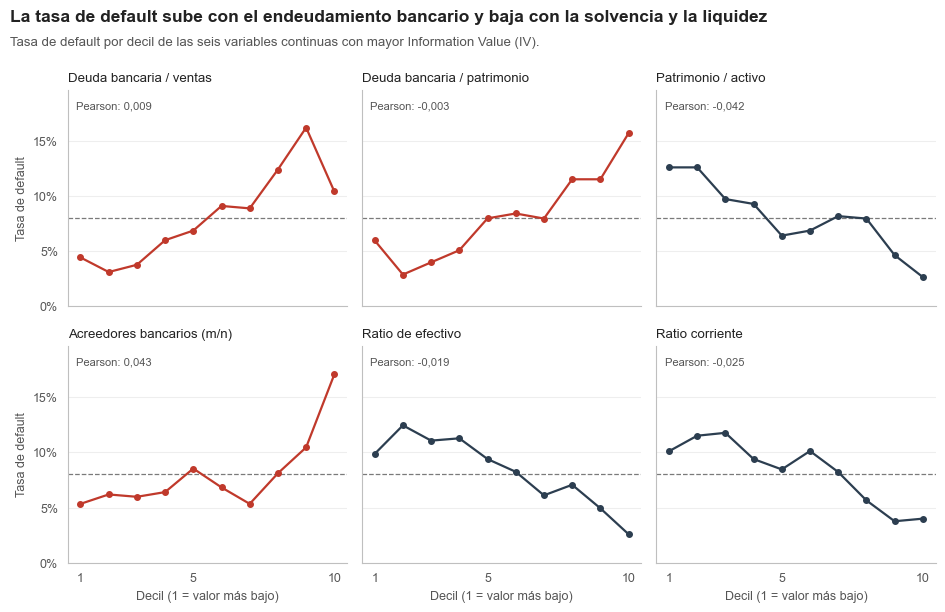

Guardada: graficos_tesis/fig_2_6_default_por_decil.png
IV: {'Deuda bancaria / ventas': 0.2833, 'Deuda bancaria / patrimonio': 0.2472, 'Patrimonio / activo': 0.1826, 'Acreedores bancarios (m/n)': 0.1711, 'Ratio de efectivo': 0.1573, 'Ratio corriente': 0.1515}
Spearman decil-tasa: {'Deuda bancaria / ventas': 0.92, 'Deuda bancaria / patrimonio': 0.89, 'Patrimonio / activo': -0.89, 'Acreedores bancarios (m/n)': 0.72, 'Ratio de efectivo': -0.9, 'Ratio corriente': -0.84}
Pearson variable-evento: {'Deuda bancaria / ventas': 0.009, 'Deuda bancaria / patrimonio': -0.003, 'Patrimonio / activo': -0.042, 'Acreedores bancarios (m/n)': 0.043, 'Ratio de efectivo': -0.019, 'Ratio corriente': -0.025}


In [88]:
# Figura 2.6 — Tasa de default por decil de las seis variables continuas con mayor Information Value
# (celda iv_feature_selection, iv_fs_df). Se usa el IV y no la informacion mutua porque el IV no depende del
# ruido del estimador: el ranking de MI cambiaba con la cantidad de columnas. En cada panel, la correlacion
# de Pearson entre la variable original y el evento: casi nula aunque la tasa cambie con claridad por decil.
_cands = [c for c in iv_fs_df['Feature'] if c in df_train.columns and df_train[c].nunique() > 20][:6]
_res, PEARSON_F26 = {}, {}
for c in _cands:
    d = df_train[[c, 'DEFAULT_FUTURE']].replace([np.inf, -np.inf], np.nan).dropna()
    d['dec'] = pd.qcut(d[c].rank(method='first'), 10, labels=range(1, 11))
    _res[c] = d.groupby('dec', observed=True)['DEFAULT_FUTURE'].mean()
    PEARSON_F26[c] = float(np.corrcoef(d[c].astype(float), d['DEFAULT_FUTURE'])[0, 1])
_prom = df_train['DEFAULT_FUTURE'].mean()
_rho = {c: spearmanr(range(1, 11), _res[c].values)[0] for c in _cands}
_ymax = max(s.max() for s in _res.values()) * 1.15

fig, axes = plt.subplots(2, 3, figsize=(9.5, 5.6), sharey=True, sharex=True)
for ax, c in zip(axes.ravel(), _cands):
    s = _res[c]
    col = ENFASIS if _rho[c] > 0.5 else (OSCURO if _rho[c] < -0.5 else REFERENCIA)
    ax.axhline(_prom, color=REFERENCIA, ls='--', lw=0.9)
    ax.plot(s.index.astype(int), s.values, color=col, marker='o', ms=4, lw=1.6)
    ax.set_title(nombre_variable(c), fontsize=9.5, color='#222222', loc='left')
    ax.text(0.03, 0.95, f'Pearson: {formato_coma(PEARSON_F26[c], 3)}', transform=ax.transAxes, ha='left', va='top',
            fontsize=8, color=GRIS_TXT, bbox=CAJA)
    ax.set_ylim(0, _ymax)
    ax.set_xticks([1, 5, 10])
    eje_porcentaje(ax, 'y')
    limpiar_ejes(ax, grid='y')
for ax in axes[1]:
    ax.set_xlabel('Decil (1 = valor más bajo)', color=GRIS_TXT, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel('Tasa de default', color=GRIS_TXT, fontsize=9)
CONCEPTO = {'Acreeds. Bancarios MNal.': 'el endeudamiento bancario', 'Acreeds. Bancarios': 'el endeudamiento bancario',
            'Importe_sobre_Patrimonio': 'el endeudamiento bancario', 'Importe_sobre_Ventas': 'el endeudamiento bancario',
            'Ratio_Patrimonio': 'la solvencia', 'Multiplicador': 'el apalancamiento', 'Ratio_Corriente': 'la liquidez',
            'Ratio_Efectivo': 'la liquidez', 'Prueba_Acida': 'la liquidez', 'Deuda_sobre_Activos': 'el endeudamiento',
            'Relacion_deuda_patrimonio': 'el endeudamiento'}
_sube = sin_repetidos(CONCEPTO.get(c, nombre_variable(c).lower()) for c in _cands if _rho[c] > 0.5)
_baja = sin_repetidos(CONCEPTO.get(c, nombre_variable(c).lower()) for c in _cands if _rho[c] < -0.5)
_partes = []
if _sube: _partes.append('sube con ' + unir_con_y(_sube))
if _baja: _partes.append('baja con ' + unir_con_y(_baja))
guardar_figura(fig,
          'La tasa de default ' + ' y '.join(_partes),
          f'Tasa de default por decil de las seis variables continuas con mayor Information Value (IV).',
          f'Fuente: {FUENTE_EC} y {FUENTE_CR}.\nNotas: deciles calculados sobre las observaciones con dato; '
          'la tendencia se mide con la correlación de Spearman entre el decil y la tasa (|ρ| > 0,5). En cada panel, la '
          'correlación de Pearson entre la variable original y el evento: es casi nula aunque la tasa cambie con claridad '
          'entre deciles.',
          'fig_2_6_default_por_decil.png')
print('IV:', {nombre_variable(c): float(iv_fs_df.set_index('Feature').loc[c, 'IV']) for c in _cands})
print('Spearman decil-tasa:', {nombre_variable(c): round(float(_rho[c]), 2) for c in _cands})
print('Pearson variable-evento:', {nombre_variable(c): round(PEARSON_F26[c], 3) for c in _cands})


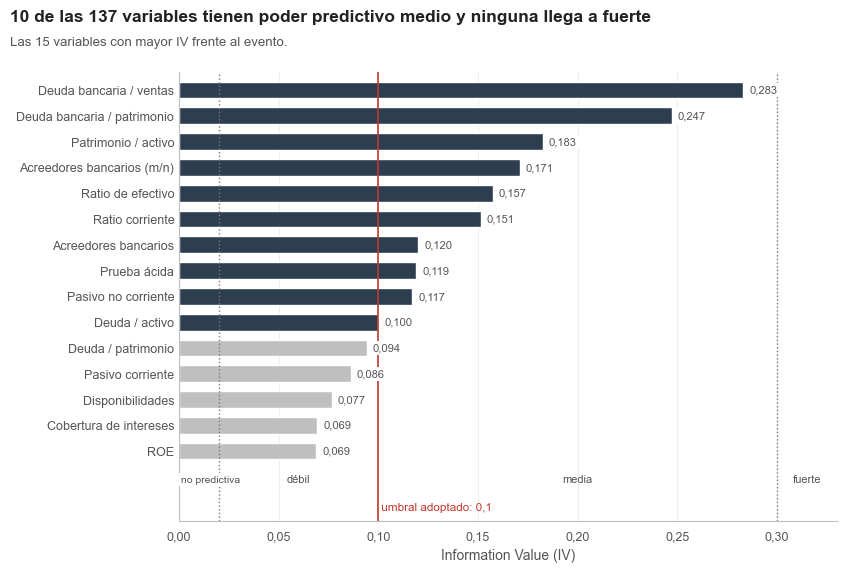

Guardada: graficos_tesis/fig_3_2_iv_escala_siddiqi.png


In [89]:
# Figura 3.2 — Information Value de las 15 variables con mayor IV, con la escala de Siddiqi (2017)
_iv = iv_fs_df.head(15).iloc[::-1]
_n_sel = int((iv_fs_df['IV'] >= 0.1).sum())

fig, ax = plt.subplots(figsize=(8.5, 5.2))
_xmax = max(0.33, _iv['IV'].max() * 1.15)
ax.barh(range(len(_iv)), _iv['IV'], color=[OSCURO if v >= 0.1 else CONTEXTO for v in _iv['IV']], height=0.65)
for i, v in enumerate(_iv['IV']):
    ax.text(v + 0.003, i, formato_coma(v, 3), va='center', fontsize=8, color=GRIS_TXT, bbox=CAJA, zorder=4)
for _x0 in (0.02, 0.3):
    ax.axvline(_x0, color=REFERENCIA, ls=':', lw=1)
ax.axvline(0.1, color=ENFASIS, lw=1.2)
ax.text(0.001, -1.1, 'no predictiva', ha='left', va='center', fontsize=7.5, color=GRIS_TXT, bbox=CAJA, zorder=4)
for _xc, _t in [(0.06, 'débil'), (0.2, 'media'), ((0.3 + _xmax) / 2, 'fuerte')]:
    ax.text(_xc, -1.1, _t, ha='center', va='center', fontsize=8, color=GRIS_TXT)
ax.text(0.1, -2.2, ' umbral adoptado: 0,1', color=ENFASIS, fontsize=8.5, va='center')
ax.set_yticks(range(len(_iv)))
ax.set_yticklabels([nombre_variable(f) for f in _iv['Feature']], fontsize=8.5)
ax.set_ylim(-2.7, len(_iv) - 0.3)
ax.set_xlim(0, _xmax)
eje_decimal_coma(ax, 'x', 2)
ax.set_xlabel('Information Value (IV)', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
ax.tick_params(axis='y', length=0)
guardar_figura(fig,
          f'{_n_sel} de las {len(iv_fs_df)} variables tienen poder predictivo medio y ninguna llega a fuerte',
          'Las 15 variables con mayor IV frente al evento.',
          f'Fuente: {FUENTE_EC} y {FUENTE_CR}; IV calculado sobre deciles.\n'
          'Notas: escala de Siddiqi (2017): menos de 0,02, no predictiva; de 0,02 a 0,1, débil; de 0,1 a 0,3, media; '
          '0,3 o más, fuerte.',
          'fig_3_2_iv_escala_siddiqi.png')

In [90]:
# AUC univariado de cada variable candidata (seccion 3.3.2): el AUC que se obtiene ordenando a las empresas solo
# por esa variable, con los faltantes imputados por la mediana de entrenamiento (X_train de la celda de imputacion).
# Se toma max(AUC, 1 - AUC), porque una variable puede discriminar en cualquiera de los dos sentidos.
auc_univariado = pd.Series({c: roc_auc_score(y_train, X_train[c]) for c in nonconst})
auc_univariado = np.maximum(auc_univariado, 1 - auc_univariado).sort_values(ascending=False)
print(f'Variables evaluadas: {len(auc_univariado)}')
print(f'Variables con AUC univariado > 0,60: {(auc_univariado > 0.60).sum()}')
print(auc_univariado.head(10).round(4).to_string())


Variables evaluadas: 137
Variables con AUC univariado > 0,60: 4
Importe_sobre_Ventas         0.6352
Importe_sobre_Patrimonio     0.6287
Ratio_Patrimonio             0.6061
Ratio_Efectivo               0.6022
Ratio_Corriente              0.5941
Total Pasivo No Corriente    0.5892
Acreeds. Bancarios MNal.     0.5834
Prueba_Acida                 0.5782
Deuda_sobre_Activos          0.5757
Relacion_deuda_patrimonio    0.5726


## Correlacion


In [91]:
# Ranking de features por mutual information con target
# Pearson se mantiene solo para reportar el signo
print("Ranking por mutual information")

ratios_fe = [c for c in ['ROA', 'ROE', 'Ratio_Corriente', 'Prueba_Acida', 'Ratio_Efectivo',
                          'Margen_Bruto', 'Margen_Operativo', 'Margen_Neto', 'Margen_EBITDA',
                          'Deuda_sobre_Activos', 'Deuda_LP_sobre_Activos', 'Ratio_Patrimonio',
                          'Rotacion_Activos', 'Relacion_deuda_patrimonio', 'Multiplicador',
                          'Cobertura_de_intereses', 'Intensidad_Activo_Fijo', 'Ratio_GAV',
                          'Ratio_Exportaciones', 'Intensidad_Depreciacion']
              if c in nonconst]
lags_fe = [c for c in nonconst if c.startswith(('delta_', 'pct_chg_'))]
raw_features = [c for c in nonconst if c not in ratios_fe and c not in lags_fe]

print(f"Features raw:     {len(raw_features)}")
print(f"Ratios FE:        {len(ratios_fe)}")
print(f"Lags temporales:  {len(lags_fe)}")
print(f"Total numericas:  {len(nonconst)}")

X_train_corr = pd.DataFrame(X_train[nonconst].values, columns=nonconst, index=X_train.index)
X_for_mi = X_train_corr

# MI con target (primario)
mi_target = pd.Series(
    mutual_info_classif(X_for_mi.values, y_train.values, random_state=42, n_neighbors=5),
    index=X_for_mi.columns
).sort_values(ascending=False)

# Pearson con target (solo para el signo)
pearson_target = X_train_corr.corrwith(y_train).dropna()

# Top 10 por MI
top10_mi = mi_target.head(10)


Ranking por mutual information
Features raw:     113
Ratios FE:        14
Lags temporales:  10
Total numericas:  137


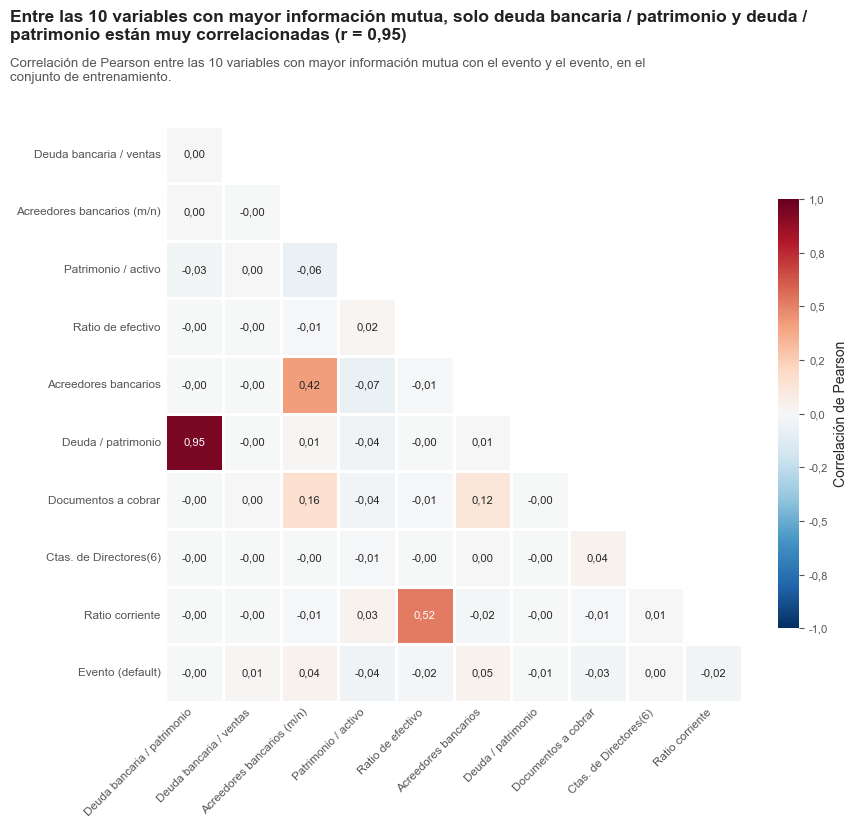

Pares con |r| >= 0.7 dentro del top 10: 1
Importe_sobre_Patrimonio  Relacion_deuda_patrimonio    0.949


In [92]:
# Heatmap de correlaciones (Pearson) — mismas top 10 features por MI + target.
# Complementario al heatmap de MI (celda siguiente): Pearson muestra la
# estructura LINEAL y el SIGNO de cada relacion; la MI captura ademas la
# redundancia no lineal. Criterio de seleccion de variables a mostrar:
# top 10 por mutual information con el target (declarado en el titulo).
top_feats_corr = top10_mi.index.tolist()
corr_sel = X_train_corr[top_feats_corr].copy()
corr_sel['DEFAULT_FUTURE'] = y_train.values.astype(int)
corr_matrix = corr_sel.corr()

# Pares con |r| alto dentro del top (redundancia lineal a vigilar)
_pares = (corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool))
          .stack().sort_values(key=abs, ascending=False))
_pares = _pares[~_pares.index.map(frozenset).duplicated()]
_altos = _pares[_pares.abs() >= 0.7]

_etq_corr = [nombre_variable(c) if c != 'DEFAULT_FUTURE' else 'Evento (default)' for c in corr_matrix.columns]
_sub_corr = corr_matrix.iloc[1:, :-1]
mask_p = np.triu(np.ones_like(_sub_corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(_sub_corr, mask=mask_p, annot=np.vectorize(lambda v: formato_coma(v, 2))(_sub_corr.values), fmt='',
            cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, ax=ax, linewidths=0.8, linecolor='white',
            annot_kws={'size': 8}, xticklabels=_etq_corr[:-1], yticklabels=_etq_corr[1:],
            cbar_kws={'label': 'Correlación de Pearson', 'shrink': 0.7})
_cb = ax.collections[0].colorbar
_cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: formato_coma(v, 1)))
_cb.ax.tick_params(colors=GRIS_TXT, labelsize=8)
_cb.outline.set_visible(False)
plt.xticks(rotation=45, ha='right', fontsize=8.5, color=GRIS_TXT)
plt.yticks(rotation=0, fontsize=8.5, color=GRIS_TXT)
ax.tick_params(length=0)
ax.grid(False)
if len(_altos) == 1:
    (_a, _b), _r = _altos.index[0], _altos.iloc[0]
    _tit_corr = (f'Entre las 10 variables con mayor información mutua, solo {nombre_variable(_a).lower()} y {nombre_variable(_b).lower()} '
                 f'están muy correlacionadas (r = {formato_coma(_r, 2)})')
elif len(_altos) > 1:
    _tit_corr = f'Entre las 10 variables con mayor información mutua, {len(_altos)} pares tienen una correlación de 0,7 o más'
else:
    _tit_corr = 'Ninguna correlación entre las 10 variables con mayor información mutua llega a 0,7 en valor absoluto'
guardar_figura(fig, _tit_corr,
          'Correlación de Pearson entre las 10 variables con mayor información mutua con el evento y el evento, en el '
          'conjunto de entrenamiento.', '', None)

print(f"Pares con |r| >= 0.7 dentro del top 10: {len(_altos)}")
if len(_altos):
    print(_altos.round(3).to_string())


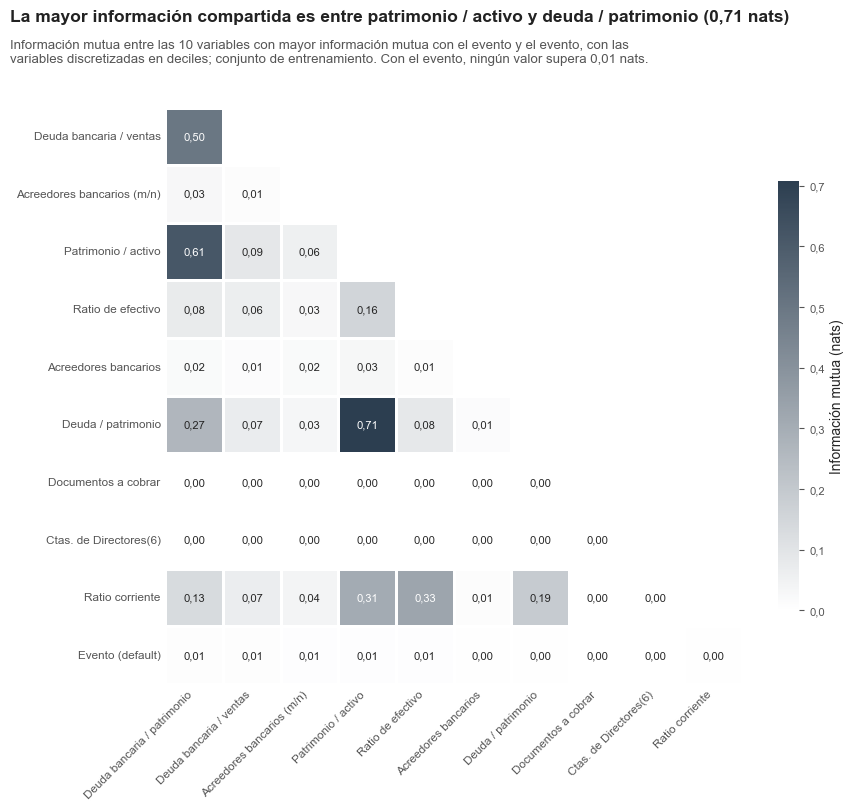

In [93]:
# Heatmap por MI top 10 features con target

from sklearn.metrics import mutual_info_score

# Features del top 10 con target
top_feats = top10_mi.index.tolist()
X_top = X_train_corr[top_feats].copy()
X_top_disc = pd.DataFrame({c: discretizar_deciles(X_top[c]) for c in X_top.columns}, index=X_top.index)
X_top_disc['DEFAULT_FUTURE'] = y_train.values.astype(int)

H_top = X_top_disc.apply(entropia)
cols = X_top_disc.columns.tolist()
n = len(cols)
mi_matrix = pd.DataFrame(np.zeros((n, n)), index=cols, columns=cols)
for i, ci in enumerate(cols):
    for j, cj in enumerate(cols):
        if i == j:
            mi_matrix.iloc[i, j] = H_top[ci]  # MI(X,X) = H(X)
        elif j > i:
            mi_ij = mutual_info_score(X_top_disc[ci], X_top_disc[cj])
            mi_matrix.iloc[i, j] = mi_ij
            mi_matrix.iloc[j, i] = mi_ij


off_diag_max = mi_matrix.where(~np.eye(n, dtype=bool)).max().max()

from matplotlib.colors import LinearSegmentedColormap
_etq_mi = [nombre_variable(c) if c != 'DEFAULT_FUTURE' else 'Evento (default)' for c in cols]
_sub_mi = mi_matrix.iloc[1:, :-1]
mask = np.triu(np.ones_like(_sub_mi, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(_sub_mi, mask=mask, annot=np.vectorize(lambda v: formato_coma(v, 2))(_sub_mi.values), fmt='',
            cmap=LinearSegmentedColormap.from_list('claro_oscuro', ['#FFFFFF', OSCURO]), vmin=0, vmax=off_diag_max,
            square=True, ax=ax, linewidths=0.8, linecolor='white', annot_kws={'size': 8},
            xticklabels=_etq_mi[:-1], yticklabels=_etq_mi[1:], cbar_kws={'label': 'Información mutua (nats)', 'shrink': 0.7})
_cb = ax.collections[0].colorbar
_cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: formato_coma(v, 1)))
_cb.ax.tick_params(colors=GRIS_TXT, labelsize=8)
_cb.outline.set_visible(False)
plt.xticks(rotation=45, ha='right', fontsize=8.5, color=GRIS_TXT)
plt.yticks(rotation=0, fontsize=8.5, color=GRIS_TXT)
ax.tick_params(length=0)
ax.grid(False)
_vars_mi = [c for c in cols if c != 'DEFAULT_FUTURE']
_mm = mi_matrix.loc[_vars_mi, _vars_mi].where(~np.eye(len(_vars_mi), dtype=bool)).stack()
(_a, _b), _v = _mm.idxmax(), _mm.max()
_t_max = mi_matrix.loc[_vars_mi, 'DEFAULT_FUTURE'].max()
guardar_figura(fig, f'La mayor información compartida es entre {nombre_variable(_a).lower()} y {nombre_variable(_b).lower()} ({formato_coma(_v, 2)} nats)',
          'Información mutua entre las 10 variables con mayor información mutua con el evento y el evento, con las variables '
          f'discretizadas en deciles; conjunto de entrenamiento. Con el evento, ningún valor supera {formato_coma(_t_max, 2)} nats.',
          '', None)


In [94]:
# Investigo correlacion entre variables

# Discretizar todas las features
X_all_filled = X_train_corr
X_disc_all = pd.DataFrame(
    {c: discretizar_deciles(X_all_filled[c]) for c in X_all_filled.columns},
    index=X_all_filled.index
)
H_all = X_disc_all.apply(entropia)

# MI para todos los pares
cols_all = X_disc_all.columns.tolist()
n_pairs_total = len(cols_all) * (len(cols_all) - 1) // 2

all_pairs = []
for ii in range(len(cols_all)):
    for jj in range(ii + 1, len(cols_all)):
        mi = mutual_info_score(X_disc_all[cols_all[ii]], X_disc_all[cols_all[jj]])
        all_pairs.append({
            'Feature_1': cols_all[ii],
            'Feature_2': cols_all[jj],
            'MI': mi,
        })

all_pairs_df = pd.DataFrame(all_pairs).sort_values('MI', ascending=False)

# Threshold: top 5% de pares por MI
threshold_mi = all_pairs_df['MI'].quantile(0.95)
high_pairs = all_pairs_df[all_pairs_df['MI'] >= threshold_mi].copy().reset_index(drop=True)

# Incluyo signo de Correlacion de Pearson
pearson_matrix = X_train_corr.corr()
high_pairs['r_pearson'] = high_pairs.apply(
    lambda r: round(pearson_matrix.loc[r['Feature_1'], r['Feature_2']], 3)
    if r['Feature_1'] in pearson_matrix.index and r['Feature_2'] in pearson_matrix.columns else np.nan,
    axis=1
)
fe_set_corr = set(ratios_fe + lags_fe)
high_pairs['Tipo_1'] = high_pairs['Feature_1'].apply(lambda f: 'FE' if f in fe_set_corr else 'Raw')
high_pairs['Tipo_2'] = high_pairs['Feature_2'].apply(lambda f: 'FE' if f in fe_set_corr else 'Raw')

high_pairs = high_pairs[['Feature_1', 'Tipo_1', 'Feature_2', 'Tipo_2', 'MI', 'r_pearson']]
high_pairs['MI'] = high_pairs['MI'].round(3)

print(f"Threshold MI (percentil 95): {threshold_mi:.3f} nats")
print(f"Pares con MI >= threshold: {len(high_pairs)}")
print(f"MI maxima observada: {all_pairs_df['MI'].max():.3f} nats")
print(f"MI mediana: {all_pairs_df['MI'].median():.3f} nats")
print()
print("Top 20 pares con mayor MI cruda:")
display(high_pairs.head(20))


Threshold MI (percentil 95): 0.156 nats
Pares con MI >= threshold: 466
MI maxima observada: 1.662 nats
MI mediana: 0.004 nats

Top 20 pares con mayor MI cruda:


,Feature_1,Tipo_1,Feature_2,Tipo_2,MI,r_pearson
0,Desempleo,Raw,Desempleo_var_interanual,Raw,1.662,0.799
1,Desempleo,Raw,Desempleo_var_trimestral,Raw,1.520,0.563
2,Desempleo_var_trimestral,Raw,Desempleo_var_interanual,Raw,1.504,0.749
3,PIB,Raw,PIB_var_trimestral,Raw,1.441,0.666
4,Resultado Operativo,Raw,Resultado Neto,Raw,1.327,0.960
5,PIB_var_trimestral,Raw,PIB_var_interanual,Raw,1.290,0.015
6,Relacion_deuda_patrimonio,FE,Deuda_sobre_Activos,FE,1.288,0.034
7,PIB,Raw,PIB_var_interanual,Raw,1.281,0.033
8,PIB_var_interanual,Raw,Desempleo_var_interanual,Raw,1.129,-0.458
9,PIB_var_interanual,Raw,Desempleo,Raw,1.126,-0.509


## Entrenamiento de modelos 

In [95]:
# Dataset despues del split
  
print('Datos para los modelos')
  
print(f'{"Particion":<12} {"Obs":>6} {"Features":>9} {"Default%":>9} {"Empresas":>9}')
for name, Xp, yp in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
    n_emp = df_model.loc[Xp.index, 'RUT'].nunique() if 'RUT' in df_model.columns else '?'
    print(f'{name:<12} {len(Xp):>6,} {Xp.shape[1]:>9} {yp.mean()*100:>8.1f}% {n_emp:>9}')
print(f'{"TOTAL":<12} {len(X_train)+len(X_test):>6,}')

print(f'\nFeatures con OHE: {X_train.shape[1]}')
ohe_feats = [c for c in X_train.columns if c.startswith(tuple(f'{c_}_' for c_ in cols_categoricas))]   # incluye SECTOR_
non_ohe = X_train.shape[1] - len(ohe_feats)
print(f'  Numericas originales: {non_ohe}')
print(f'  OHE (cualitativas): {len(ohe_feats)}')

Datos para los modelos
Particion       Obs  Features  Default%  Empresas
Train         4,690       138      8.0%      2547
Test          1,153       138      6.9%       632
TOTAL         5,843

Features con OHE: 138
  Numericas originales: 110
  OHE (cualitativas): 28


In [96]:
# Transformacion en deciles
# Cada feature se reemplaza por su decil (0-9).

# Creo el transformer (fit en X_train)
decile_fn = create_decile_transformer(X_train)

X_tr_dec, X_te_dec = decile_fn(X_train, X_test)
num_check = [c for c in X_train.select_dtypes(include='number').columns
              if X_train[c].nunique(dropna=True) > 1]
print(f"\nVerificacion Deciles:")
print(f"  Shape: {X_tr_dec.shape} (train), {X_te_dec.shape} (test)")
print(f"  Rango: [{X_tr_dec[num_check].min().min():.0f}, {X_tr_dec[num_check].max().max():.0f}]")

# Test con subset de features
subset = num_check[:10]
X_sub_tr, X_sub_te = decile_fn(X_train[subset], X_test[subset])
print(f"  Test subset ({len(subset)} cols): OK \u2014 shape {X_sub_tr.shape}")

# WoE encoding (supervisado: usa y_train para fit) 
# WoE_i = ln((Goods_i/Total_Goods) / (Bads_i/Total_Bads)) por bin (10 bins por feature).
# Vs Deciles: WoE incorpora informacion del target -> mejor para modelos lineales (LR).
woe_fn = create_woe_transformer(X_train, y_train, n_bins=10)

X_tr_woe, X_te_woe = woe_fn(X_train, X_test)
woe_cols = [c for c in num_check if (X_tr_woe[c] != X_train[c]).any()]
print(f"\nVerificacion WoE:")
print(f"  Shape: {X_tr_woe.shape} (train), {X_te_woe.shape} (test)")
if woe_cols:
    wmin = X_tr_woe[woe_cols].min().min()
    wmax = X_tr_woe[woe_cols].max().max()
    print(f"  Rango WoE: [{wmin:.3f}, {wmax:.3f}]")
print(f"  NaN post-transform: {X_tr_woe[num_check].isna().sum().sum()} (debe ser 0)")

X_sub_tr_w, X_sub_te_w = woe_fn(X_train[subset], X_test[subset])
print(f"  Test subset ({len(subset)} cols): OK \u2014 shape {X_sub_tr_w.shape}")



Verificacion Deciles:
  Shape: (4690, 138) (train), (1153, 138) (test)
  Rango: [0, 9]
  Test subset (10 cols): OK — shape (4690, 10)


WoE transformer creado:
  Features encodeadas: 101
  Constantes excluidas: 0
  Bins por feature: 10

Verificacion WoE:
  Shape: (4690, 138) (train), (1153, 138) (test)
  Rango WoE: [-0.936, 8.742]
  NaN post-transform: 0 (debe ser 0)
  Test subset (10 cols): OK — shape (4690, 10)


Chi-squared feature selection (sobre deciles)
  Shape post-deciles: (4690, 137)
  Rango: [0, 9]
  NaN check: 0 (debe ser 0)

Features totales:       137
Significativos (p<0.05): 32
Seleccionados (final):  32

Top 10 features por Chi2:
                  Feature  Chi2_Score  P_Value  Significant_p<0.05
     Importe_sobre_Ventas    117.7970      0.0                True
 Importe_sobre_Patrimonio    114.3464      0.0                True
Total Pasivo No Corriente     85.6404      0.0                True
         Ratio_Patrimonio     85.0372      0.0                True
           Ratio_Efectivo     81.2366      0.0                True
          Ratio_Corriente     70.2690      0.0                True
             Prueba_Acida     47.1905      0.0                True
      Deuda_sobre_Activos     44.1070      0.0                True
Relacion_deuda_patrimonio     41.7297      0.0                True
       Acreeds. Bancarios     34.2154      0.0                True


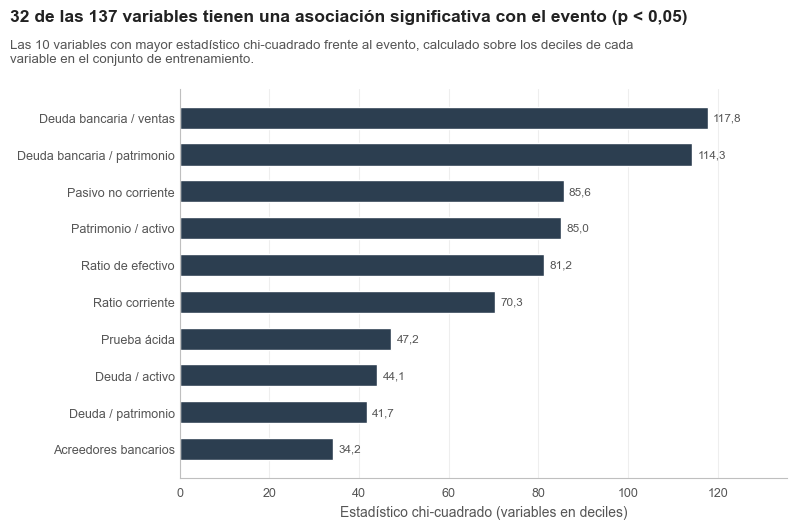


VIF de las 32 variables Chi2 (deciles de train): max 8.9 (TOTAL PATRIMONIO), 0 con VIF > 10
TOTAL PATRIMONIO                8.9
Deuda_sobre_Activos             8.0
Relacion_deuda_patrimonio       7.7
TOTAL PASIVO                    7.6
Total Pasivo Corriente          6.9
Sub-total - Disponibilidades    6.0
Ratio_Patrimonio                5.8
Ratio_Efectivo                  5.3
Importe_sobre_Patrimonio        3.7
Prueba_Acida                    3.6


In [97]:
# Chi2

from sklearn.feature_selection import chi2
from matplotlib.patches import Patch

print('Chi-squared feature selection (sobre deciles)')

# Mismo discretizador que el selector Chi2 del pipeline (pipeline_cv.DecileTransformer): solo se
# discretizan las continuas; las binarias (cualitativas codificadas) pasan como 0/1. Sobre X_train
# completo, con los faltantes imputados por la mediana como en el pipeline.
import pipeline_cv as pcv
_X_nc = pcv.MedianImputer().fit(X_train[nonconst]).transform(X_train[nonconst])
X_train_dec = pcv.DecileTransformer().fit(_X_nc).transform(_X_nc)
print(f'  Shape post-deciles: {X_train_dec.shape}')
print(f'  Rango: [{X_train_dec.values.min():.0f}, {X_train_dec.values.max():.0f}]')
print(f'  NaN check: {X_train_dec.isna().sum().sum()} (debe ser 0)')

chi2_scores, chi2_pvalues = chi2(X_train_dec.values, y_train.astype(int).values)

chi2_results = pd.DataFrame({
    'Feature': nonconst,
    'Chi2_Score': chi2_scores,
    'P_Value': chi2_pvalues,
}).sort_values('Chi2_Score', ascending=False).reset_index(drop=True)

chi2_results['Significant_p<0.05'] = chi2_results['P_Value'] < 0.05

# Seleccion: features con p < 0.05
chi2_selected_features = chi2_results.loc[
    chi2_results['P_Value'] < 0.05, 'Feature'
].tolist()

print(f'\nFeatures totales:       {len(nonconst)}')
print(f'Significativos (p<0.05): {(chi2_results["P_Value"] < 0.05).sum()}')
print(f'Seleccionados (final):  {len(chi2_selected_features)}')

print(f'\nTop 10 features por Chi2:')
print(chi2_results.head(10).round(4).to_string(index=False))


# Top 10 features por Chi2 Score

top10 = chi2_results.head(10)
colors = [OSCURO if p < 0.05 else CONTEXTO for p in top10['P_Value']]
fig, ax = plt.subplots(figsize=(8, 4.6))
_yy = np.arange(len(top10))[::-1]
ax.barh(_yy, top10['Chi2_Score'].values, color=colors, height=0.6)
for y_, v_ in zip(_yy, top10['Chi2_Score'].values):
    ax.text(v_ + top10['Chi2_Score'].max() * 0.01, y_, formato_coma(v_, 1), va='center', fontsize=8.5, color=GRIS_TXT)
ax.set_yticks(_yy)
ax.set_yticklabels([nombre_variable(f) for f in top10['Feature']], fontsize=9)
ax.set_xlim(0, top10['Chi2_Score'].max() * 1.15)
eje_decimal_coma(ax, 'x', 0)
ax.set_xlabel('Estadístico chi-cuadrado (variables en deciles)', color=GRIS_TXT)
ax.tick_params(axis='y', length=0)
limpiar_ejes(ax, grid='x')
guardar_figura(fig, f"{int((chi2_results['P_Value'] < 0.05).sum())} de las {len(nonconst)} variables tienen una asociación "
               'significativa con el evento (p < 0,05)',
          'Las 10 variables con mayor estadístico chi-cuadrado frente al evento, calculado sobre los deciles de cada '
          'variable en el conjunto de entrenamiento.', '', None)
# Redundancia dentro del conjunto seleccionado (A1b): VIF sobre los deciles de train.
# VIF_j = 1 / (1 - R2_j) = diagonal de la inversa de la matriz de correlacion.
_corr_sel = X_train_dec[chi2_selected_features].corr().values
_vif = pd.Series(np.diag(np.linalg.pinv(_corr_sel)), index=chi2_selected_features).sort_values(ascending=False)
print(f'\nVIF de las {len(chi2_selected_features)} variables Chi2 (deciles de train): '
      f'max {_vif.iloc[0]:.1f} ({_vif.index[0]}), {(_vif > 10).sum()} con VIF > 10')
print(_vif.head(10).round(1).to_string())


### Búsqueda de estrategias con todo el preprocesamiento dentro del pipeline

In [98]:
# Grillas de hiperparametros de cada modelo (las mismas de la exploracion anterior; la de la regresion
# logistica se amplio hacia C chicos, porque C = 0,001 quedaba en el borde)
RF_PARAM_GRID = {
    'classifier__n_estimators': [300, 500],
    'classifier__max_depth': [5, 8, 12],
    'classifier__min_samples_leaf': [10, 20, 50],
    'classifier__min_samples_split': [5, 10],
    'classifier__max_features': ['sqrt', 0.3, 0.5],
    'classifier__max_samples': [0.7, 0.9],
}
LR_PARAM_GRID = {
    'classifier__C': [1e-4, 2.5e-4, 5e-4, 1e-3, 2.5e-3, 5e-3, 0.01, 0.05, 0.1, 0.5, 1.0, 10.0, 100.0],
    'classifier__penalty': ['l1', 'l2'],
}
DT_PARAM_GRID = {
    'classifier__max_depth': [3, 4, 5, 6, 8, 10, 15, None],
    'classifier__min_samples_leaf': [10, 25, 50, 100, 200],
    'classifier__min_samples_split': [2, 5, 10, 50, 100],
    'classifier__ccp_alpha': [0.0, 1e-4, 5e-4, 1e-3, 5e-3],
}
MLP_PARAM_GRID = {
    'classifier__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64),
                                       (64, 32, 16), (128, 64, 32), (256, 128, 64)],
    'classifier__activation': ['relu', 'tanh'],
    'classifier__alpha': [1e-5, 5e-5, 1e-4, 5e-4, 1e-3],
    'classifier__learning_rate_init': [1e-4, 5e-4, 1e-3, 5e-3],
}
XGB_PARAM_GRID = {
    'classifier__n_estimators':     [100, 200, 500],
    'classifier__max_depth':        [3, 4, 5],
    'classifier__learning_rate':    [0.01, 0.05, 0.1],
    'classifier__min_child_weight': [5, 10, 20],
    'classifier__subsample':        [0.6, 0.8],
    'classifier__colsample_bytree': [0.5, 0.8],
    'classifier__reg_alpha':        [0, 0.1, 1.0],
    'classifier__reg_lambda':       [1.0, 5.0, 10.0],
    'classifier__gamma':            [0, 0.5, 1.0],
}
for _n, _g in [('RF', RF_PARAM_GRID), ('LR', LR_PARAM_GRID), ('DT', DT_PARAM_GRID),
               ('MLP', MLP_PARAM_GRID), ('XGB', XGB_PARAM_GRID)]:
    print(f'{_n}: {int(np.prod([len(v) for v in _g.values()])):,} combinaciones de hiperparametros')


RF: 216 combinaciones de hiperparametros
LR: 26 combinaciones de hiperparametros
DT: 1,000 combinaciones de hiperparametros
MLP: 320 combinaciones de hiperparametros
XGB: 8,748 combinaciones de hiperparametros


In [99]:
# Infraestructura de la busqueda: modulo pipeline_cv.py (transformadores que se ajustan dentro del
# pipeline y funciones de busqueda), datos crudos, particiones y modelos.
import pickle
import pipeline_cv as pcv
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN

EXPLORAR_PIPECV = False   # True: repite la busqueda completa (unas 3 horas); False: lee results/pipecv/
PIPECV_DIR = Path('results/pipecv')
PIPECV_DIR.mkdir(parents=True, exist_ok=True)
CACHE_SEL = str((PIPECV_DIR / 'cache_seleccion').resolve())   # cache en disco de la seleccion por fold

Xtr, Xte = X_train_crudo, X_test_crudo
ytr, yte = y_train.astype(int), y_test.astype(int)
g_tr = grupos_train.loc[Xtr.index]
g_te = groups.loc[Xte.index]
spw = float((ytr == 0).sum() / (ytr == 1).sum())

# Estimadores base de la RFECV (fijos, mas simples que los modelos finales)
EST_RF = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=50,
                                class_weight='balanced', random_state=42, n_jobs=1)
EST_LR = LogisticRegression(penalty='l2', solver='liblinear', C=1.0, class_weight='balanced',
                            max_iter=1000, random_state=42)
EST_XGB = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, min_child_weight=10,
                        subsample=0.8, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=5.0, gamma=0.5,
                        scale_pos_weight=spw, eval_metric='logloss', random_state=42, n_jobs=1)


configs_resampling_pipe = [
    ('None', None, {}),
    ('SMOTE(0.3)', SMOTE, {'sampling_strategy': 0.3, 'random_state': 42, 'k_neighbors': 5}),
    ('SMOTE(0.5)', SMOTE, {'sampling_strategy': 0.5, 'random_state': 42, 'k_neighbors': 5}),
    ('SMOTEENN(0.3)', SMOTEENN, {'sampling_strategy': 0.3, 'random_state': 42}),
    ('SMOTEENN(0.5)', SMOTEENN, {'sampling_strategy': 0.5, 'random_state': 42}),
]

# La regresion logistica usa saga, que no penaliza el intercepto: con liblinear y C chico el
# intercepto quedaba encogido y las probabilidades, infladas (media 0,30 con una tasa de 0,08).
MODELOS_PIPE = {
    'RF':  dict(clf=RandomForestClassifier(random_state=42, n_jobs=-1), grid=RF_PARAM_GRID,
                sel=crear_selectores(EST_RF, False, g_tr, CACHE_SEL), scaler=False),
    'LR':  dict(clf=LogisticRegression(solver='saga', max_iter=5000, random_state=42), grid=LR_PARAM_GRID,
                sel=crear_selectores(EST_LR, True, g_tr, CACHE_SEL), scaler=True),
    'DT':  dict(clf=DecisionTreeClassifier(random_state=42), grid=DT_PARAM_GRID,
                sel=crear_selectores(EST_RF, False, g_tr, CACHE_SEL), scaler=False),
    'MLP': dict(clf=MLPClassifier(max_iter=500, early_stopping=True, validation_fraction=0.15,
                                  n_iter_no_change=15, random_state=42), grid=MLP_PARAM_GRID,
                sel=crear_selectores(EST_LR, True, g_tr, CACHE_SEL), scaler=True),
    'XGB': dict(clf=XGBClassifier(eval_metric='logloss', scale_pos_weight=spw, random_state=42, n_jobs=1),
                grid=XGB_PARAM_GRID, sel=crear_selectores(EST_XGB, False, g_tr, CACHE_SEL), scaler=False),
}
NOMBRES_PIPE = {'LR': 'Regresión logística', 'RF': 'Random Forest', 'MLP': 'MLP', 'XGB': 'XGBoost',
                'DT': 'Árbol de decisión'}

folds_cv = list(GroupKFold(n_splits=5).split(Xtr, ytr, groups=g_tr))
print(f'Entrenamiento: {Xtr.shape[0]:,} observaciones x {Xtr.shape[1]} variables candidatas, '
      f'{int(ytr.sum())} eventos; test: {Xte.shape[0]:,} observaciones, {int(yte.sum())} eventos')
print(f'Particiones: GroupKFold(5) por empresa; scale_pos_weight (XGBoost) = {spw:.2f}')


Entrenamiento: 4,690 observaciones x 137 variables candidatas, 376 eventos; test: 1,153 observaciones, 80 eventos
Particiones: GroupKFold(5) por empresa; scale_pos_weight (XGBoost) = 11.47


In [100]:
# Paso 1. Exploracion: 140 estrategias por modelo (4 outliers x 3 transformaciones x 3 selecciones x
# 5 balanceos, Chi-cuadrado solo con deciles), cada una con RandomizedSearchCV de 30 iteraciones.
# Por estrategia: AUC de CV (media y desvio entre folds), sobreajuste dentro del fold y metricas sobre
# las probabilidades fuera de muestra (KS, umbral de maxima separacion KS, precision, recall, F1, Brier).
if EXPLORAR_PIPECV:
    from joblib import Parallel, delayed
    _tareas, _vistos = [], set()
    for _m in MODELOS_PIPE.values():
        for _lab, _sel in _m['sel'].items():
            if (_lab, repr(_sel.estimator)) in _vistos:
                continue
            _vistos.add((_lab, repr(_sel.estimator)))
            _tareas += [(_sel, tr) for tr, _ in folds_cv] + [(_sel, np.arange(len(ytr)))]
    Parallel(n_jobs=-1)(delayed(precalcular_seleccion)(s, i, Xtr, ytr) for s, i in _tareas)
    oof_exploracion = {}
    for _name, _m in MODELOS_PIPE.items():
        _df, _best, _, _oo = pcv.run_full_grid(_name, _m['clf'], _m['grid'], Xtr, ytr, g_tr, _m['sel'],
                                               configs_resampling_pipe, _m['scaler'], n_iter=30, n_jobs=-1,
                                               out_csv=str(PIPECV_DIR / f'grid_{_name}.csv'), folds=folds_cv)
        oof_exploracion.update({(_name, k): v for k, v in _oo.items()})
    with open(PIPECV_DIR / 'oof_exploracion.pkl', 'wb') as _fh:
        pickle.dump(oof_exploracion, _fh)

exploracion = pd.concat([pd.read_csv(PIPECV_DIR / f'grid_{n}.csv') for n in MODELOS_PIPE], ignore_index=True)
exploracion['resampling'] = exploracion['resampling'].fillna('None')   # read_csv lee el texto 'None' como vacio
print(f'Exploracion: {len(exploracion)} estrategias ({exploracion.groupby("Modelo").size().to_dict()})\n')
_cols = ['Modelo', 'Strategy', 'CV_AUC', 'CV_std', 'Overfit_CV', 'KS', 'Recall', 'Precision', 'Brier', 'Prob_media']
display(exploracion.sort_values('CV_AUC', ascending=False).groupby('Modelo').head(3)[_cols]
        .sort_values(['Modelo', 'CV_AUC'], ascending=[True, False]).round(4))


Exploracion: 700 estrategias ({'DT': 140, 'LR': 140, 'MLP': 140, 'RF': 140, 'XGB': 140})



,Modelo,Strategy,CV_AUC,CV_std,Overfit_CV,KS,Recall,Precision,Brier,Prob_media
296,DT,Raw + YJ + IV + SMOTE(0.3),0.6588,0.0387,0.0580,0.2333,0.6011,0.1217,0.1001,0.2085
299,DT,Raw + YJ + IV + SMOTEENN(0.5),0.6579,0.0301,0.0268,0.2447,0.6569,0.1190,0.1635,0.3075
297,DT,Raw + YJ + IV + SMOTE(0.5),0.6550,0.0424,0.0590,0.2300,0.4973,0.1276,0.1373,0.2876
161,LR,Raw + Deciles + RFECV + SMOTE(0.3),0.6997,0.0323,0.0193,0.2836,0.7154,0.1244,0.0912,0.2204
266,LR,Z-score + Deciles + RFECV + SMOTE(0.3),0.6995,0.0325,0.0194,0.2838,0.6941,0.1243,0.0912,0.2205
160,LR,Raw + Deciles + RFECV + None,0.6992,0.0318,0.0262,0.2811,0.6915,0.1253,0.0707,0.0802
548,MLP,Z-score + Deciles + RFECV + SMOTEENN(0.3),0.6933,0.0227,0.0398,0.2894,0.6410,0.1263,0.1201,0.2479
558,MLP,Z-score + Deciles + Chi2_dec + SMOTEENN(0.3),0.6920,0.0377,0.0460,0.2851,0.6596,0.1316,0.1137,0.2316
513,MLP,IQR + Deciles + RFECV + SMOTEENN(0.3),0.6918,0.0232,0.0377,0.2794,0.6144,0.1286,0.1254,0.2509
80,RF,IQR + YJ + RFECV + None,0.6870,0.0378,0.1245,0.2766,0.6676,0.1239,0.0715,0.0804


In [101]:
# Paso 2. Ajuste fino: para la mejor estrategia de cada modelo (mayor AUC de CV en la exploracion), una grilla
# local alrededor de sus mejores hiperparametros (GridSearchCV si tiene hasta 150 configuraciones; si no, 150 al azar).
if EXPLORAR_PIPECV:
    _finos, oof_finos = [], {}
    for _name, _m in MODELOS_PIPE.items():
        _top = exploracion[exploracion.Modelo == _name].sort_values('CV_AUC', ascending=False).head(1)
        for _, _row in _top.iterrows():
            _out, _oo = pcv.ajuste_fino(_row, _name, _m['clf'], _m['grid'], Xtr, ytr, _m['sel'],
                                        configs_resampling_pipe, _m['scaler'], folds_cv, n_jobs=-1, max_configs=150)
            _finos.append(_out)
            oof_finos[(_name, _row['Strategy'])] = _oo
    resumen_estrategias = pd.concat([exploracion, pd.DataFrame(_finos)], ignore_index=True)
    resumen_estrategias['familia'] = resumen_estrategias['resampling'].map(
        lambda r: 'None' if r == 'None' else r.split('(')[0])
    resumen_estrategias.to_csv(PIPECV_DIR / 'resumen_estrategias.csv', index=False)
    resumen_estrategias.to_excel(PIPECV_DIR / 'resumen_estrategias.xlsx', index=False)
    # mejor estrategia de cada familia de balanceo (exploracion), para la seccion de SMOTE y SMOTEENN
    _oof_fam = {}
    for _name in MODELOS_PIPE:
        _sub = resumen_estrategias[(resumen_estrategias.Modelo == _name) & (resumen_estrategias.Etapa == 'Exploracion')]
        for _fam, _ss in _sub.groupby('familia'):
            _r = _ss.loc[_ss['CV_AUC'].idxmax()]
            _p, _pf = oof_exploracion[(_name, _r['Strategy'])]
            _oof_fam[(_name, _fam)] = dict(row=_r.to_dict(), oof=_p, per_fold=_pf)
    with open(PIPECV_DIR / 'oof_familias.pkl', 'wb') as _fh:
        pickle.dump(dict(oof=_oof_fam, folds=folds_cv, y=ytr.values), _fh)
else:
    resumen_estrategias = pd.read_csv(PIPECV_DIR / 'resumen_estrategias.csv')
    if 'resampling' in resumen_estrategias:   # read_csv lee el texto 'None' como vacio
        resumen_estrategias['resampling'] = resumen_estrategias['resampling'].fillna('None')
    # La busqueda guardada afino las 3 mejores estrategias de cada modelo. Cada ajuste fino es independiente
    # (mismos folds y semilla), asi que conservar solo el de la mejor estrategia equivale a repetirlo para ella.
    _expl = resumen_estrategias[resumen_estrategias.Etapa == 'Exploracion']
    _mejor = set(_expl.loc[_expl.groupby('Modelo')['CV_AUC'].idxmax(), ['Modelo', 'Strategy']].itertuples(index=False, name=None))
    _par = pd.Series(list(zip(resumen_estrategias.Modelo, resumen_estrategias.Strategy)), index=resumen_estrategias.index)
    resumen_estrategias = resumen_estrategias[(resumen_estrategias.Etapa != 'Ajuste fino') | _par.isin(_mejor)].copy()

ajuste_fino_df = resumen_estrategias[resumen_estrategias.Etapa == 'Ajuste fino']
print('Ajuste fino (mejora sobre la exploracion; el error estandar es el desvio entre folds / raiz de 5):')
display(ajuste_fino_df[['Modelo', 'Strategy', 'CV_AUC', 'Mejora_vs_exploracion', 'Error_estandar', 'Overfit_CV',
                        'n_grilla_local', 'Best_Params']].sort_values(['Modelo', 'CV_AUC'], ascending=[True, False]).round(4))


Ajuste fino (mejora sobre la exploracion; el error estandar es el desvio entre folds / raiz de 5):


,Modelo,Strategy,CV_AUC,Mejora_vs_exploracion,Error_estandar,Overfit_CV,n_grilla_local,Best_Params
706,DT,Raw + YJ + IV + SMOTE(0.3),0.6608,0.0020,0.0173,0.0410,400.0,"{'classifier__min_samples_split': 4, 'classifi..."
703,LR,Raw + Deciles + RFECV + SMOTE(0.3),0.6997,0.0000,0.0145,0.0193,5.0,"{'classifier__C': 0.001, 'classifier__penalty'..."
709,MLP,Z-score + Deciles + RFECV + SMOTEENN(0.3),0.6933,0.0000,0.0102,0.0398,20.0,"{'classifier__activation': 'tanh', 'classifier..."
700,RF,IQR + YJ + RFECV + None,0.6881,0.0012,0.0169,0.1432,1024.0,"{'classifier__n_estimators': 500, 'classifier_..."
712,XGB,IQR + Deciles + Chi2_dec + None,0.6863,0.0033,0.0162,0.0731,307200.0,"{'classifier__subsample': 0.7, 'classifier__re..."


### Efecto de SMOTE y SMOTEENN

Para cada modelo se compara la mejor estrategia de cada familia de balanceo (sin resampling, SMOTE y SMOTEENN), solo con la validación cruzada

In [102]:
# Mejor estrategia de cada familia de balanceo, por modelo: validacion cruzada y modelo final reentrenado con todo el entrenamiento
from sklearn.metrics import brier_score_loss
with open(PIPECV_DIR / 'oof_familias.pkl', 'rb') as _fh:
    _ofam = pickle.load(_fh)
_y_oof = np.asarray(_ofam['y'])
_filas = []
for (modelo, fam), v in _ofam['oof'].items():
    p, pf, row = v['oof'], v['per_fold'], v['row']
    aucs = np.array([row[f'fold{j}'] for j in range(len(folds_cv))])
    thr = []
    for (tr, va), pv in zip(folds_cv, pf):
        f_, t_, th_ = roc_curve(_y_oof[va], pv)
        thr.append(float(th_[np.argmax(t_ - f_)]))
    u = float(np.mean(thr)); pred = (p >= u).astype(int)
    _filas.append(dict(Modelo=modelo, Familia=fam, Estrategia=row['Strategy'], CV_AUC=aucs.mean(), CV_std=aucs.std(),
                       _folds=aucs, KS=ks_stat(_y_oof, p), Umbral=u,
                       Precision=precision_score(_y_oof, pred, zero_division=0), Recall=recall_score(_y_oof, pred),
                       F1=f1_score(_y_oof, pred), Prob_media=float(p.mean()), Brier=brier_score_loss(_y_oof, p)))
balanceo_resumen = pd.DataFrame(_filas)
_base = {m: balanceo_resumen[(balanceo_resumen.Modelo == m) & (balanceo_resumen.Familia == 'None')]['_folds'].iloc[0]
         for m in balanceo_resumen.Modelo.unique()}
balanceo_resumen['Dif_vs_None'] = [(r['_folds'] - _base[r['Modelo']]).mean() for _, r in balanceo_resumen.iterrows()]
balanceo_resumen['Folds_mejor'] = [int(((r['_folds'] - _base[r['Modelo']]) > 0).sum()) for _, r in balanceo_resumen.iterrows()]
balanceo_resumen = (balanceo_resumen.drop(columns='_folds')
                    .assign(_o=lambda d: d['Familia'].map({'None': 0, 'SMOTE': 1, 'SMOTEENN': 2}))
                    .sort_values(['Modelo', '_o']).drop(columns='_o').reset_index(drop=True))
# Modelo final de cada familia: la mejor estrategia de la exploracion, reentrenada con todo el entrenamiento
_auc_fin, _pm_fin = [], []
for _, _rw in balanceo_resumen.iterrows():
    _row = dict(_ofam['oof'][(_rw['Modelo'], _rw['Familia'])]['row'])
    _row['outlier'], _row['transform'], _row['features'], _row['resampling'] = _row['Strategy'].split(' + ')
    _pp = pcv.pipeline_from_row(_row, MODELOS_PIPE[_rw['Modelo']]['clf'], MODELOS_PIPE[_rw['Modelo']]['sel'],
                                configs_resampling_pipe, MODELOS_PIPE[_rw['Modelo']]['scaler']).fit(Xtr, ytr)
    _ptr = _pp.predict_proba(Xtr)[:, 1]
    _auc_fin.append(roc_auc_score(ytr, _ptr)); _pm_fin.append(float(_ptr.mean()))
balanceo_resumen['AUC_train_final'] = _auc_fin
balanceo_resumen['Prob_media_train_final'] = _pm_fin
balanceo_resumen['Dif_train_vs_None'] = [r['AUC_train_final'] - balanceo_resumen[(balanceo_resumen.Modelo == r['Modelo']) &
                                         (balanceo_resumen.Familia == 'None')]['AUC_train_final'].iloc[0]
                                         for _, r in balanceo_resumen.iterrows()]
balanceo_resumen.to_csv(PIPECV_DIR / 'balanceo_resumen.csv', index=False)
print(f'Tasa observada de default en entrenamiento: {_y_oof.mean():.3f}')
display(balanceo_resumen[['Modelo', 'Familia', 'Estrategia', 'AUC_train_final', 'Dif_train_vs_None', 'Prob_media_train_final',
                          'CV_AUC', 'CV_std', 'Dif_vs_None', 'Folds_mejor', 'KS',
                          'Umbral', 'Precision', 'Recall', 'F1', 'Prob_media', 'Brier']].round(4))
for m, sub in balanceo_resumen.groupby('Modelo'):
    b = sub.loc[sub.CV_AUC.idxmax()]; n0 = sub[sub.Familia == 'None'].iloc[0]
    print(f"  {m}: mejor familia por CV = {b.Familia} ({b.CV_AUC:.4f}); sin balanceo {n0.CV_AUC:.4f}; "
          f"probabilidad media sin balanceo {n0.Prob_media:.3f}, con SMOTE/SMOTEENN "
          f"{sub[sub.Familia != 'None'].Prob_media.min():.3f} a {sub[sub.Familia != 'None'].Prob_media.max():.3f}")

Tasa observada de default en entrenamiento: 0.080


,Modelo,Familia,Estrategia,AUC_train_final,Dif_train_vs_None,Prob_media_train_final,CV_AUC,CV_std,Dif_vs_None,Folds_mejor,KS,Umbral,Precision,Recall,F1,Prob_media,Brier
0,DT,None,IQR + Deciles + IV + None,0.7048,0.0000,0.0802,0.6522,0.0272,0.0000,0,0.2344,0.0825,0.1248,0.5957,0.2064,0.0797,0.0723
1,DT,SMOTE,Raw + YJ + IV + SMOTE(0.3),0.7249,0.0200,0.2063,0.6588,0.0387,0.0066,3,0.2363,0.2069,0.1217,0.6011,0.2024,0.2085,0.1001
2,DT,SMOTEENN,Raw + YJ + IV + SMOTEENN(0.5),0.6758,-0.0290,0.3030,0.6579,0.0301,0.0056,4,0.2486,0.3582,0.1190,0.6569,0.2016,0.3075,0.1635
3,LR,None,Raw + Deciles + RFECV + None,0.7126,0.0000,0.0802,0.6992,0.0318,0.0000,0,0.2813,0.0729,0.1253,0.6915,0.2122,0.0802,0.0707
4,LR,SMOTE,Raw + Deciles + RFECV + SMOTE(0.3),0.7075,-0.0050,0.2217,0.6997,0.0323,0.0005,3,0.2836,0.2169,0.1244,0.7154,0.2119,0.2204,0.0912
5,LR,SMOTEENN,Raw + Deciles + RFECV + SMOTEENN(0.3),0.7053,-0.0072,0.2149,0.6984,0.0299,-0.0008,2,0.2888,0.2248,0.1255,0.7261,0.2140,0.2328,0.0965
6,MLP,None,Winsor + Deciles + IV + None,0.7870,0.0000,0.0887,0.6864,0.0375,0.0000,0,0.2632,0.0847,0.1305,0.5878,0.2135,0.0839,0.0724
7,MLP,SMOTE,IQR + YJ + IV + SMOTE(0.5),0.7423,-0.0447,0.2960,0.6905,0.0358,0.0041,2,0.2898,0.3196,0.1324,0.6463,0.2197,0.2963,0.1287
8,MLP,SMOTEENN,Z-score + Deciles + RFECV + SMOTEENN(0.3),0.7501,-0.0369,0.2090,0.6933,0.0227,0.0070,4,0.2894,0.2312,0.1263,0.6410,0.2110,0.2479,0.1201
9,RF,None,IQR + YJ + RFECV + None,0.8061,0.0000,0.0801,0.6870,0.0378,0.0000,0,0.2766,0.0815,0.1239,0.6676,0.2090,0.0804,0.0715


  DT: mejor familia por CV = SMOTE (0.6588); sin balanceo 0.6522; probabilidad media sin balanceo 0.080, con SMOTE/SMOTEENN 0.209 a 0.308
  LR: mejor familia por CV = SMOTE (0.6997); sin balanceo 0.6992; probabilidad media sin balanceo 0.080, con SMOTE/SMOTEENN 0.220 a 0.233
  MLP: mejor familia por CV = SMOTEENN (0.6933); sin balanceo 0.6864; probabilidad media sin balanceo 0.084, con SMOTE/SMOTEENN 0.248 a 0.296
  RF: mejor familia por CV = None (0.6870); sin balanceo 0.6870; probabilidad media sin balanceo 0.080, con SMOTE/SMOTEENN 0.181 a 0.181
  XGB: mejor familia por CV = None (0.6831); sin balanceo 0.6831; probabilidad media sin balanceo 0.448, con SMOTE/SMOTEENN 0.573 a 0.629


In [103]:
# Comparacion pareada: cada estrategia de preprocesamiento (outliers + transformacion + seleccion) con y sin
# cada balanceo, en la exploracion. A diferencia de la "mejor estrategia de cada familia", aisla el efecto del
# balanceo, porque compara el mismo preprocesamiento.
_ex = resumen_estrategias[resumen_estrategias.Etapa == 'Exploracion'].copy()
_ex['_base'] = _ex['Strategy'].str.rsplit(' + ', n=1).str[0]
_ex['_res'] = _ex['Strategy'].str.rsplit(' + ', n=1).str[1]
_filas = []
for _m, _s in _ex.groupby('Modelo'):
    _pv = _s.pivot_table(index='_base', columns='_res', values='CV_AUC')
    for _r in [c for c in _pv.columns if c != 'None']:
        _d = (_pv[_r] - _pv['None']).dropna()
        _filas.append(dict(Modelo=_m, Balanceo=_r, Familia=_r.split('(')[0], n=len(_d), Mediana=_d.median(),
                           P25=_d.quantile(0.25), P75=_d.quantile(0.75), Pct_mejora=float((_d > 0).mean()),
                           _dif=_d.values))
balanceo_pareado = pd.DataFrame(_filas)
balanceo_pareado.drop(columns='_dif').to_csv(PIPECV_DIR / 'balanceo_pareado.csv', index=False)
print('Diferencia de AUC de validacion cruzada con y sin balanceo, mismo preprocesamiento '
      '(n = estrategias comparadas; Pct_mejora = proporcion en que el balanceo mejora):')
display(balanceo_pareado.drop(columns='_dif').round(4))


Diferencia de AUC de validacion cruzada con y sin balanceo, mismo preprocesamiento (n = estrategias comparadas; Pct_mejora = proporcion en que el balanceo mejora):


,Modelo,Balanceo,Familia,n,Mediana,P25,P75,Pct_mejora
0,DT,SMOTE(0.3),SMOTE,28,-0.0105,-0.0146,-0.0060,0.1429
1,DT,SMOTE(0.5),SMOTE,28,-0.0072,-0.0137,0.0005,0.2857
2,DT,SMOTEENN(0.3),SMOTEENN,28,-0.0008,-0.0085,0.0034,0.3929
3,DT,SMOTEENN(0.5),SMOTEENN,28,-0.0023,-0.0068,0.0025,0.2857
4,LR,SMOTE(0.3),SMOTE,28,0.0001,-0.0015,0.0016,0.5000
5,LR,SMOTE(0.5),SMOTE,28,-0.0006,-0.0014,0.0012,0.3214
6,LR,SMOTEENN(0.3),SMOTEENN,28,-0.0010,-0.0033,-0.0003,0.2500
7,LR,SMOTEENN(0.5),SMOTEENN,28,-0.0009,-0.0022,0.0000,0.2857
8,MLP,SMOTE(0.3),SMOTE,28,0.0066,0.0023,0.0099,0.8929
9,MLP,SMOTE(0.5),SMOTE,28,0.0044,-0.0001,0.0100,0.7500


### Elección del modelo

In [104]:
# Paso 3. Mejor estrategia de cada modelo (ajuste fino). La eleccion entre modelos (mayor AUC de entrenamiento del modelo final) se hace en la
# celda siguiente, junto con el ajuste de los modelos finales y su evaluacion.
mejores_pipe = {}
for _m in MODELOS_PIPE:
    _s = ajuste_fino_df[ajuste_fino_df.Modelo == _m].sort_values('CV_AUC', ascending=False)
    _r = _s.iloc[0].to_dict()
    _r['outlier'], _r['transform'], _r['features'], _r['resampling'] = _r['Strategy'].split(' + ')
    mejores_pipe[_m] = _r
print(pd.DataFrame({m: {'Estrategia': r['Strategy'], 'CV_AUC': round(r['CV_AUC'], 4), 'CV_std': round(r['CV_std'], 4),
                        'Overfit_CV': round(r['Overfit_CV'], 4), 'Prob_media': round(r['Prob_media'], 4),
                        'Brier': round(r['Brier'], 4)} for m, r in mejores_pipe.items()}).T.to_string())


                                    Estrategia  CV_AUC  CV_std Overfit_CV Prob_media   Brier
RF                     IQR + YJ + RFECV + None  0.6881   0.036     0.1432     0.0806  0.0714
LR          Raw + Deciles + RFECV + SMOTE(0.3)  0.6997  0.0323     0.0193     0.2204  0.0912
DT                  Raw + YJ + IV + SMOTE(0.3)  0.6608  0.0427      0.041     0.2122  0.1003
MLP  Z-score + Deciles + RFECV + SMOTEENN(0.3)  0.6933  0.0227     0.0398     0.2479  0.1201
XGB            IQR + Deciles + Chi2_dec + None  0.6863  0.0313     0.0731     0.4375  0.2114


In [105]:
# Ajuste final de los cinco modelos con todo el entrenamiento, eleccion con sus metricas de entrenamiento y
# evaluacion en test. Las probabilidades de CV (fuera de muestra, mismos folds) alimentan el umbral
# de maxima separacion KS, la sensibilidad a costos y el scorecard.
CLF_FINAL = {'RF': RandomForestClassifier(random_state=42, n_jobs=-1),
             'LR': LogisticRegression(solver='saga', max_iter=5000, random_state=42),
             'DT': DecisionTreeClassifier(random_state=42),
             'MLP': MLPClassifier(max_iter=500, early_stopping=True, validation_fraction=0.15,
                                  n_iter_no_change=15, random_state=42),
             'XGB': XGBClassifier(eval_metric='logloss', scale_pos_weight=spw, random_state=42, n_jobs=-1)}
_pos = {}
for _k, _gg in enumerate(g_te.values):
    _pos.setdefault(_gg, []).append(_k)
_grs = list(_pos)


pipes_finales, cv_fold_preds, cv_fold_aucs = {}, {}, {}
ensemble_train_probas, ensemble_test_probas, resultados_pipe = {}, {}, {}
for _m in ['LR', 'RF', 'MLP', 'XGB', 'DT']:
    _r = mejores_pipe[_m]
    _pipe = pcv.pipeline_from_row(_r, CLF_FINAL[_m], MODELOS_PIPE[_m]['sel'], configs_resampling_pipe,
                                  MODELOS_PIPE[_m]['scaler'])
    _p_oof, _pf = pcv.oof_predict(_pipe, Xtr, ytr, folds_cv)
    cv_fold_preds[_m] = _pf
    cv_fold_aucs[_m] = [roc_auc_score(ytr.iloc[va], pv) for (_, va), pv in zip(folds_cv, _pf)]
    _pipe.fit(Xtr, ytr)
    pipes_finales[_m] = _pipe
    ensemble_train_probas[_m] = _pipe.predict_proba(Xtr)[:, 1]
    ensemble_test_probas[_m] = _pipe.predict_proba(Xte)[:, 1]
    _thrs = []
    for (_, va), pv in zip(folds_cv, _pf):
        _f, _t, _th = roc_curve(ytr.iloc[va], pv)
        _thrs.append(float(_th[np.argmax(_t - _f)]))
    _thr = float(np.mean(_thrs))
    _pt = ensemble_test_probas[_m]; _pred = (_pt >= _thr).astype(int)
    _auc_tr, _auc_te = roc_auc_score(ytr, ensemble_train_probas[_m]), roc_auc_score(yte, _pt)
    _lo, _hi = ic_auc_bootstrap(_pt, yte.values, _pos, _grs)
    resultados_pipe[_m] = {
        'Model': _m, 'Strategy': _r['Strategy'], 'n_features': len(_pipe.named_steps['selector'].selected_),
        'cv_auc': round(float(np.mean(cv_fold_aucs[_m])), 4), 'cv_auc_std': round(float(np.std(cv_fold_aucs[_m])), 4),
        'overfit_cv': round(float(_r['Overfit_CV']), 4),
        'train_auc': round(_auc_tr, 4), 'test_auc': round(_auc_te, 4), 'test_ic95': (round(float(_lo), 3), round(float(_hi), 3)),
        'overfit_gap': round(_auc_tr - _auc_te, 4), 'test_ks': round(ks_stat(yte, _pt), 4),
        'test_threshold': round(_thr, 4), 'test_precision': round(precision_score(yte, _pred, zero_division=0), 4),
        'test_recall': round(recall_score(yte, _pred), 4), 'test_f1': round(f1_score(yte, _pred), 4),
        'test_alertas': round(float(_pred.mean()), 4), 'test_brier': round(brier_score_loss(yte, _pt), 4),
        'test_prob_media': round(float(_pt.mean()), 4), 'threshold_cv': _thr,
    }
    _ptr = ensemble_train_probas[_m]; _predtr = (_ptr >= _thr).astype(int)
    resultados_pipe[_m].update({
        'train_ks': round(ks_stat(ytr, _ptr), 4), 'train_precision': round(precision_score(ytr, _predtr, zero_division=0), 4),
        'train_recall': round(recall_score(ytr, _predtr), 4), 'train_f1': round(f1_score(ytr, _predtr), 4),
        'train_alertas': round(float(_predtr.mean()), 4), 'train_prob_media': round(float(_ptr.mean()), 4)})
    print(f"{_m}: CV {resultados_pipe[_m]['cv_auc']:.4f}  test {_auc_te:.4f} [{_lo:.3f}, {_hi:.3f}]  "
          f"train {_auc_tr:.4f}  variables {resultados_pipe[_m]['n_features']}")

# Interfaz que usan las celdas siguientes (punto de operacion, scorecard, explicabilidad, registro, figuras)
ensemble_models_info = {m: {'modelo': pipes_finales[m], 'features': list(pipes_finales[m].named_steps['selector'].selected_),
                            'outlier': mejores_pipe[m]['outlier'], 'transform': mejores_pipe[m]['transform'],
                            'metrics': resultados_pipe[m]} for m in pipes_finales}
ensemble_candidates = {}   # sin ensambles en esta version
all_candidates = {m: {'results': resultados_pipe[m], 'modelo': pipes_finales[m], 'pipeline': pipes_finales[m],
                      'features': ensemble_models_info[m]['features'], 'outlier': mejores_pipe[m]['outlier'],
                      'strategy': mejores_pipe[m]['Strategy'], 'is_ensemble': False,
                      'cv_auc_mean': float(np.mean(cv_fold_aucs[m])), 'cv_auc_std': float(np.std(cv_fold_aucs[m])),
                      'test_proba_sel': ensemble_test_probas[m], 'test_auc_sel': resultados_pipe[m]['test_auc'],
                      'threshold_cv': resultados_pipe[m]['threshold_cv']} for m in pipes_finales}


# Eleccion en dos pasos: la estrategia de cada modelo se eligio por AUC de validacion cruzada (ajuste fino);
# entre los cinco modelos finales (reentrenados con todo el entrenamiento) se elige el de mayor AUC de entrenamiento.
# El test no interviene.
MODELO_ELEGIDO = max(resultados_pipe, key=lambda m: resultados_pipe[m]['train_auc'])
CRITERIO_SELECCION = ('Estrategia de cada modelo por AUC de validacion cruzada (GroupKFold(5) por RUT, tras el ajuste '
                      'fino); modelo por mayor AUC de entrenamiento del modelo final')
print('\nAUC de CV: ' + ', '.join(f"{m} {all_candidates[m]['cv_auc_mean']:.4f} (desvio {all_candidates[m]['cv_auc_std']:.4f})"
                                 for m in sorted(all_candidates, key=lambda m: -all_candidates[m]['cv_auc_mean'])))
print('Modelos finales en entrenamiento: ' + ', '.join(
    f"{m} AUC {resultados_pipe[m]['train_auc']:.4f} recall {resultados_pipe[m]['train_recall']:.3f}" for m in resultados_pipe))
print(f"Calibracion del elegido: probabilidad media {resultados_pipe[MODELO_ELEGIDO]['train_prob_media']:.4f} "
      f"frente a una tasa de {float(ytr.mean()):.4f}")
winner_name = MODELO_ELEGIDO
winner = all_candidates[winner_name]
is_ensemble = False
threshold_operativo = float(winner['threshold_cv'])
proba_train_ganador = ensemble_train_probas[winner_name]
proba_test_ganador = ensemble_test_probas[winner_name]
mejor_modelo = mejor_pipeline = pipes_finales[winner_name]
mejores_features_final = mejores_features = list(winner['features'])
mejor_outlier = winner['outlier']
mejor_estrategia = winner['strategy']
ensemble_winner_members = ensemble_winner_weights = None

comparativa_individuales = pd.DataFrame([{
    'Modelo': m, 'Elegido': m == winner_name, 'Strategy': r['Strategy'], 'Variables': r['n_features'],
    'CV_AUC': r['cv_auc'], 'CV_std': r['cv_auc_std'], 'Overfit_CV': r['overfit_cv'], 'Train_AUC': r['train_auc'],
    'Test_AUC': r['test_auc'], 'IC95_test': f"{r['test_ic95'][0]:.3f} a {r['test_ic95'][1]:.3f}",
    'Overfit_Gap': r['overfit_gap'], 'Test_KS': r['test_ks'], 'Threshold_CV': r['test_threshold'],
    'Test_Precision': r['test_precision'], 'Test_Recall': r['test_recall'], 'Test_F1': r['test_f1'],
    'Test_Alertas': r['test_alertas'], 'Test_Brier': r['test_brier'], 'Test_Prob_media': r['test_prob_media'],
    'Train_KS': r['train_ks'], 'Train_Precision': r['train_precision'], 'Train_Recall': r['train_recall'],
    'Train_F1': r['train_f1'], 'Train_Alertas': r['train_alertas'], 'Train_Prob_media': r['train_prob_media'],
} for m, r in resultados_pipe.items()]).sort_values('CV_AUC', ascending=False).reset_index(drop=True)
comparativa_individuales.to_csv(PIPECV_DIR / 'test_resultados.csv', index=False)
print(f'\nModelo elegido: {winner_name} — {mejor_estrategia} ({len(mejores_features_final)} variables)')
print(f'Umbral operativo (maxima separacion KS, promedio por fold): {threshold_operativo:.4f}')
display(comparativa_individuales.round(4))


LR: CV 0.6997  test 0.7148 [0.654, 0.769]  train 0.7075  variables 22


RF: CV 0.6881  test 0.7510 [0.694, 0.802]  train 0.8252  variables 107


MLP: CV 0.6909  test 0.6901 [0.629, 0.752]  train 0.7501  variables 22


XGB: CV 0.6863  test 0.7395 [0.679, 0.790]  train 0.7516  variables 32


DT: CV 0.6608  test 0.7112 [0.655, 0.764]  train 0.7256  variables 10

AUC de CV: LR 0.6997 (desvio 0.0323), MLP 0.6909 (desvio 0.0235), RF 0.6881 (desvio 0.0360), XGB 0.6863 (desvio 0.0313), DT 0.6608 (desvio 0.0427)
Modelos finales en entrenamiento: LR AUC 0.7075 recall 0.753, RF AUC 0.8252 recall 0.832, MLP AUC 0.7501 recall 0.662, XGB AUC 0.7516 recall 0.766, DT AUC 0.7256 recall 0.734
Calibracion del elegido: probabilidad media 0.0801 frente a una tasa de 0.0802

Modelo elegido: RF — IQR + YJ + RFECV + None (107 variables)
Umbral operativo (maxima separacion KS, promedio por fold): 0.0835


,Modelo,Elegido,Strategy,Variables,CV_AUC,CV_std,Overfit_CV,Train_AUC,Test_AUC,IC95_test,Overfit_Gap,Test_KS,Threshold_CV,Test_Precision,Test_Recall,Test_F1,Test_Alertas,Test_Brier,Test_Prob_media,Train_KS,Train_Precision,Train_Recall,Train_F1,Train_Alertas,Train_Prob_media
0,LR,False,Raw + Deciles + RFECV + SMOTE(0.3),22,0.6997,0.0323,0.0193,0.7075,0.7148,0.654 a 0.769,-0.0073,0.3434,0.2169,0.1144,0.7250,0.1976,0.4397,0.0850,0.2167,0.3232,0.1314,0.7527,0.2238,0.4591,0.2217
1,MLP,False,Z-score + Deciles + RFECV + SMOTEENN(0.3),22,0.6909,0.0235,0.0398,0.7501,0.6901,0.629 a 0.752,0.0600,0.3160,0.2312,0.1236,0.5500,0.2018,0.3088,0.1004,0.1935,0.3724,0.1607,0.6622,0.2587,0.3303,0.2090
2,RF,True,IQR + YJ + RFECV + None,107,0.6881,0.0360,0.1432,0.8252,0.7510,0.694 a 0.802,0.0742,0.4492,0.0835,0.1332,0.7875,0.2278,0.4102,0.0619,0.0790,0.4950,0.1663,0.8324,0.2772,0.4013,0.0801
3,XGB,False,IQR + Deciles + Chi2_dec + None,32,0.6863,0.0313,0.0731,0.7516,0.7395,0.679 a 0.790,0.0121,0.3655,0.4754,0.1219,0.7375,0.2092,0.4198,0.2034,0.4319,0.3837,0.1466,0.7660,0.2460,0.4190,0.4401
4,DT,False,Raw + YJ + IV + SMOTE(0.3),10,0.6608,0.0427,0.0410,0.7256,0.7112,0.655 a 0.764,0.0144,0.3786,0.2062,0.1075,0.6625,0.1850,0.4276,0.0906,0.2066,0.3496,0.1356,0.7340,0.2289,0.4341,0.2091


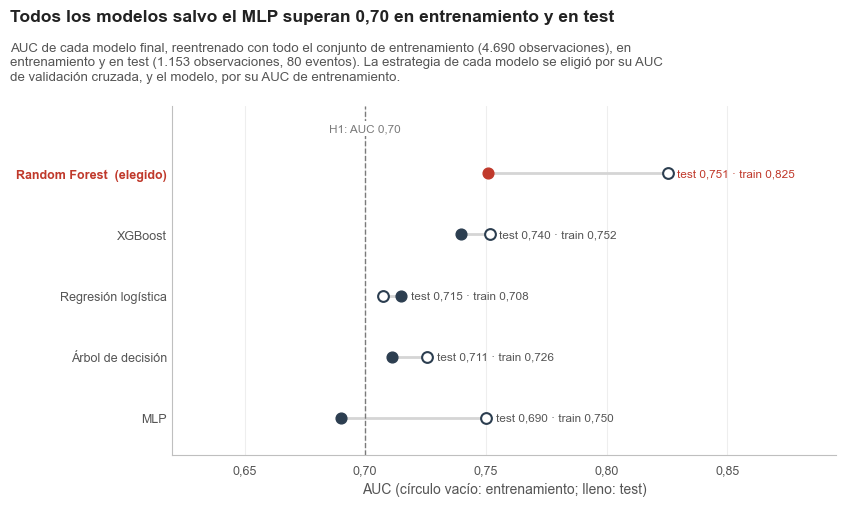

Guardada: graficos_tesis/fig_4_1_comparacion_modelos.png


In [106]:
# Figura 4.1 — Comparacion de modelos: modelo final en entrenamiento contra test (el centro de H1)
ART_MODELO = {'LR': 'la regresión logística', 'RF': 'el Random Forest', 'XGB': 'XGBoost', 'MLP': 'el MLP',
              'DT': 'el árbol de decisión'}
# 'de' + artículo: 'del Random Forest', 'de la regresión logística'
DE_MODELO = {k: ('del ' + v[3:]) if v.startswith('el ') else ('de ' + v) for k, v in ART_MODELO.items()}
_nom = {'RF': 'Random Forest', 'XGB': 'XGBoost', 'LR': 'Regresión logística', 'MLP': 'MLP',
        'DT': 'Árbol de decisión', 'Promedio simple Top-3': 'Ensamble (promedio Top-3)'}
cmp = pd.DataFrame([{'modelo': _nom[k], 'clave': k, 'test': all_candidates[k]['test_auc_sel'],
                     'cv': resultados_pipe[k]['train_auc']} for k in _nom if k in all_candidates])
cmp = cmp.sort_values('test').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.axvline(0.70, color=REFERENCIA, ls='--', lw=1)
ax.text(0.70, len(cmp) - 0.35, 'H1: AUC 0,70', color=REFERENCIA, fontsize=8.5, ha='center', va='bottom', bbox=CAJA)
for i, r in cmp.iterrows():
    elegido = r['clave'] == winner_name
    ax.plot([r['cv'], r['test']], [i, i], color='#D5D5D5', lw=2, zorder=1)
    ax.scatter(r['cv'], i, s=60, facecolor='white', edgecolor=OSCURO, lw=1.5, zorder=3)
    ax.scatter(r['test'], i, s=60, color=ENFASIS if elegido else OSCURO, zorder=3)
    ax.text(max(r['cv'], r['test']) + 0.004, i, f"test {formato_coma(r['test'], 3)} · train {formato_coma(r['cv'], 3)}",
            va='center', fontsize=8.5, color=ENFASIS if elegido else GRIS_TXT)
ax.set_yticks(range(len(cmp)))
ax.set_yticklabels([m + ('  (elegido)' if k == winner_name else '') for m, k in zip(cmp['modelo'], cmp['clave'])])
ax.set_xlim(0.62, max(0.81, float(cmp[['cv', 'test']].max().max()) + 0.07))
ax.set_ylim(-0.6, len(cmp) + 0.1)
eje_decimal_coma(ax, 'x', 2)
ax.set_xlabel('AUC (círculo vacío: entrenamiento; lleno: test)', color=GRIS_TXT)
limpiar_ejes(ax, grid='x')
ax.tick_params(axis='y', length=0)
for t, k in zip(ax.get_yticklabels(), cmp['clave']):
    if k == winner_name:
        t.set_color(ENFASIS); t.set_fontweight('bold')
_ambas = cmp[(cmp['test'] >= 0.70) & (cmp['cv'] >= 0.70)]
guardar_figura(fig,
          'Ningún modelo supera 0,70 en entrenamiento y en test a la vez' if _ambas.empty else
          'Los cinco modelos superan 0,70 en entrenamiento y en test' if len(_ambas) == len(cmp) else
          (f"Todos los modelos salvo {ART_MODELO[cmp.loc[~cmp['clave'].isin(_ambas['clave']), 'clave'].iloc[0]]} superan 0,70 en entrenamiento y en test"
           if len(_ambas) == len(cmp) - 1 else
           f"{_ambas['modelo'].iloc[0]} supera 0,70 en entrenamiento y en test" if len(_ambas) == 1 else
           f"{', '.join(_ambas['modelo'].iloc[:-1])} y {_ambas['modelo'].iloc[-1]} superan 0,70 en entrenamiento y en test"),
          f'AUC de cada modelo final, reentrenado con todo el conjunto de entrenamiento ({formato_coma(len(ytr), 0)} observaciones), '
          f'en entrenamiento y en test ({formato_coma(N_TEST, 0)} observaciones, {EV_TEST} eventos). '
          'La estrategia de cada modelo se eligió por su AUC de validación cruzada, y el modelo, por su AUC de entrenamiento.',
          f'Fuente: elaboración propia sobre {FUENTE_EC} y {FUENTE_CR}.\n'
          f'Notas: el IC 95% '
          f'{DE_MODELO[winner_name]} por bootstrap de empresas es '
          f"{formato_coma(resultados_pipe[winner_name]['test_ic95'][0], 3)} a {formato_coma(resultados_pipe[winner_name]['test_ic95'][1], 3)}.",
          'fig_4_1_comparacion_modelos.png')


Diferencia de AUC de CV (mejor familia con balanceo - sin balanceo): {'DT': np.float64(0.0066), 'XGB': np.float64(-0.0112), 'MLP': np.float64(0.007), 'RF': np.float64(-0.0037), 'LR': np.float64(0.0005)}


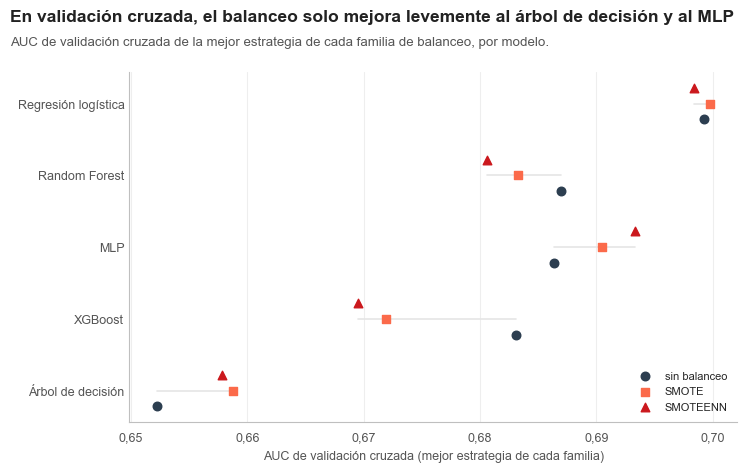

Guardada: graficos_tesis/fig_4_1b_balanceo.png


In [107]:
# Figura 4.1b — AUC de validacion cruzada de la mejor estrategia de cada familia de balanceo, por modelo
# (15/11: reemplaza a la version de tres paneles; la comparacion pareada sigue en balanceo_pareado y en la Tabla 5)
_b = balanceo_resumen.copy()
_mods = _b[_b.Familia == 'None'].sort_values('CV_AUC')['Modelo'].tolist()
_etq_f = {'None': 'sin balanceo', 'SMOTE': 'SMOTE', 'SMOTEENN': 'SMOTEENN'}
_col_f = {'None': OSCURO, 'SMOTE': '#fb6a4a', 'SMOTEENN': '#cb181d'}
_mk_f = {'None': 'o', 'SMOTE': 's', 'SMOTEENN': '^'}

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for j, fam in enumerate(['None', 'SMOTE', 'SMOTEENN']):
    s = _b[_b.Familia == fam].set_index('Modelo').reindex(_mods)
    ax.scatter(s['CV_AUC'], np.arange(len(_mods)) + (j - 1) * 0.22, marker=_mk_f[fam], color=_col_f[fam], s=38,
               label=_etq_f[fam], zorder=3)
for i, m in enumerate(_mods):   # linea que une las tres familias de cada modelo
    v = _b[_b.Modelo == m]['CV_AUC']
    ax.plot([v.min(), v.max()], [i, i], color='#E5E5E5', lw=1.2, zorder=1)
ax.set_yticks(range(len(_mods)))
ax.set_yticklabels([primera_mayuscula(NOMBRE_MODELO.get(m, m)) for m in _mods])
ax.tick_params(axis='y', length=0)
ax.set_xlabel('AUC de validación cruzada (mejor estrategia de cada familia)', color=GRIS_TXT, fontsize=9)
eje_decimal_coma(ax, 'x', 2)
limpiar_ejes(ax, grid='x')
ax.legend(frameon=False, fontsize=8, loc='lower right')
# mejora: la mejor familia con balanceo supera a la sin balanceo por mas de 0,002
_dcv = {m: _b[(_b.Modelo == m) & (_b.Familia != 'None')]['Dif_vs_None'].max() for m in _mods}
_mejora = [m for m in _mods if _dcv[m] > 0.002]
_tit = ('En validación cruzada, el balanceo solo mejora levemente ' +
        unir_con_y([ART_MODELO.get(m, m) for m in _mejora])) if _mejora else \
       'En validación cruzada, el balanceo no mejora el AUC de ningún modelo'
_tit = _tit.replace('mejora levemente el ', 'mejora levemente al ', 1).replace(' y el ', ' y al ')
print('Diferencia de AUC de CV (mejor familia con balanceo - sin balanceo):', {m: round(v, 4) for m, v in _dcv.items()})
guardar_figura(fig, _tit,
          'AUC de validación cruzada de la mejor estrategia de cada familia de balanceo, por modelo.',
          '', 'fig_4_1b_balanceo.png')


## Diagnosticos del modelo elegido


In [108]:
# Metricas de los cinco modelos en validacion cruzada, entrenamiento y test
metricas_df = comparativa_individuales[['Modelo', 'CV_AUC', 'Train_AUC', 'Test_AUC', 'IC95_test', 'Overfit_Gap',
                                        'Test_KS', 'Test_F1', 'Test_Precision', 'Test_Recall']]
print('Metricas de los cinco modelos (ordenado por AUC de CV)')
print(metricas_df.round(4).to_string(index=False))


Metricas de los cinco modelos (ordenado por AUC de CV)
Modelo  CV_AUC  Train_AUC  Test_AUC     IC95_test  Overfit_Gap  Test_KS  Test_F1  Test_Precision  Test_Recall
    LR  0.6997     0.7075    0.7148 0.654 a 0.769      -0.0073   0.3434   0.1976          0.1144       0.7250
   MLP  0.6909     0.7501    0.6901 0.629 a 0.752       0.0600   0.3160   0.2018          0.1236       0.5500
    RF  0.6881     0.8252    0.7510 0.694 a 0.802       0.0742   0.4492   0.2278          0.1332       0.7875
   XGB  0.6863     0.7516    0.7395 0.679 a 0.790       0.0121   0.3655   0.2092          0.1219       0.7375
    DT  0.6608     0.7256    0.7112 0.655 a 0.764       0.0144   0.3786   0.1850          0.1075       0.6625


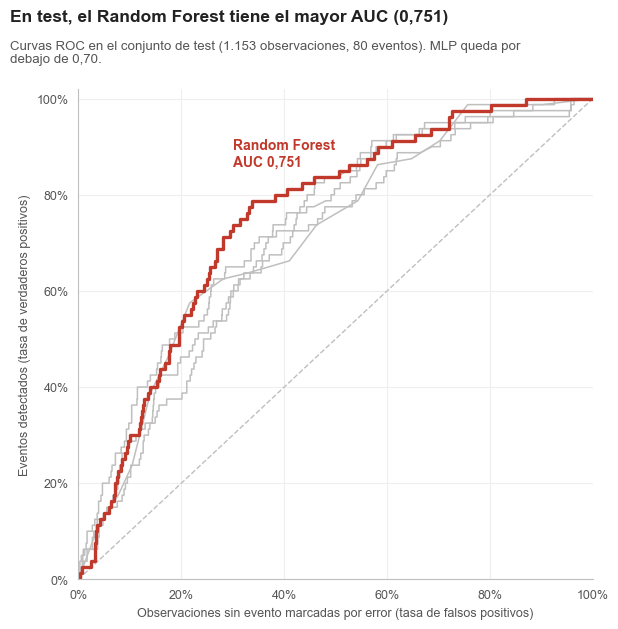

Guardada: graficos_tesis/fig_4_2_curvas_roc.png


In [109]:
# Figura 4.2 — Curvas ROC en test: el modelo elegido en color, el resto en gris
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot([0, 1], [0, 1], color=CONTEXTO, ls='--', lw=1)
_aucs = {}
for name in ensemble_models_info.keys():
    p = ensemble_test_probas[name]
    _aucs[name] = roc_auc_score(y_test, p)
    if name == winner_name:
        continue
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=CONTEXTO, lw=1.1)
fpr, tpr, _ = roc_curve(y_test, ensemble_test_probas[winner_name])
ax.plot(fpr, tpr, color=ENFASIS, lw=2.4)
_nm_w = NOMBRE_MODELO.get(winner_name, winner_name)
ax.text(0.30, 0.86, f'{_nm_w[:1].upper() + _nm_w[1:]}\nAUC {formato_coma(_aucs[winner_name], 3)}', color=ENFASIS, fontsize=10, fontweight='bold')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
eje_porcentaje(ax, 'x'); eje_porcentaje(ax, 'y')
ax.set_xlabel('Observaciones sin evento marcadas por error (tasa de falsos positivos)', color=GRIS_TXT, fontsize=9)
ax.set_ylabel('Eventos detectados (tasa de verdaderos positivos)', color=GRIS_TXT, fontsize=9)
limpiar_ejes(ax, grid='both')
_otros = {k: v for k, v in _aucs.items() if k != winner_name}
_seg = max(_otros, key=_otros.get)
_bajo = [NOMBRE_MODELO.get(k, k) for k, v in _otros.items() if v < 0.70]
guardar_figura(fig,
          (f'En test, {ART_MODELO[winner_name]} (AUC {formato_coma(_aucs[winner_name], 3)}) queda cerca del mejor, '
           f'{NOMBRE_MODELO.get(_seg, _seg)} ({formato_coma(_otros[_seg], 3)})' if _otros[_seg] > _aucs[winner_name] else
           f'En test, {ART_MODELO[winner_name]} tiene el mayor AUC ({formato_coma(_aucs[winner_name], 3)})'),
          f'Curvas ROC en el conjunto de test ({formato_coma(N_TEST, 0)} observaciones, {EV_TEST} eventos). '
          + (f"{unir_con_y(_bajo)[0].upper() + unir_con_y(_bajo)[1:]} {'queda' if len(_bajo) == 1 else 'quedan'} por debajo de 0,70."
           if _bajo else 'Los demás modelos también superan 0,70.'),
          f'Fuente: elaboración propia sobre {FUENTE_EC} y {FUENTE_CR}.',
          'fig_4_2_curvas_roc.png', ancho_txt=70)


Threshold operativo (maxima separacion KS, promedio por fold): 0.0835


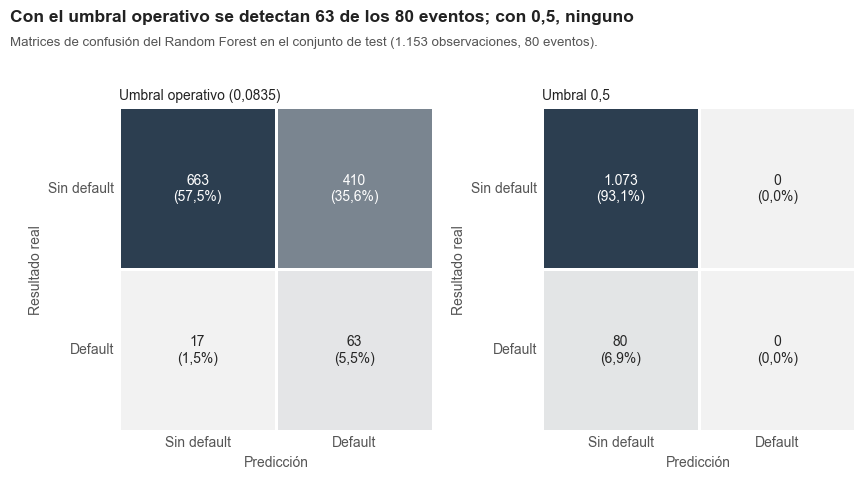

Guardada: graficos_tesis/fig_4_0_matriz_confusion.png

Operativo (0.0835):
  Precision: 0.1332
  Recall:    0.7875
  F1:        0.2278

Threshold 0.5:
  Precision: 0.0000
  Recall:    0.0000
  F1:        0.0000


In [110]:
# Punto de operacion — matrices de confusion al threshold OPERATIVO vs 0.5.
# El threshold operativo es el promedio de los umbrales de maxima separacion KS por fold de
# la validacion cruzada (celda de seleccion): el test NO participa en la
# eleccion del punto de operacion, solo reporta las metricas resultantes.
print(f"Threshold operativo (maxima separacion KS, promedio por fold): {threshold_operativo:.4f}")

from matplotlib.colors import LinearSegmentedColormap
# Threshold operativo (maxima separacion KS, promedio por fold)
y_pred_op = (proba_test_ganador >= threshold_operativo).astype(int)
cm1 = confusion_matrix(y_test, y_pred_op)
cm1_pct = cm1 / cm1.sum() * 100
# Threshold 0.5
y_pred_05 = (proba_test_ganador >= 0.5).astype(int)
cm2 = confusion_matrix(y_test, y_pred_05)
cm2_pct = cm2 / cm2.sum() * 100

_etq_cm = ['Sin default', 'Default']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 4.2), gridspec_kw={'wspace': 0.35})
for _ax_cm, _m_cm, _p_cm, _tit_cm in [(ax1, cm1, cm1_pct, f'Umbral operativo ({formato_coma(threshold_operativo, 4)})'),
                                      (ax2, cm2, cm2_pct, 'Umbral 0,5')]:
    _lab_cm = [[f'{formato_coma(c, 0)}\n({formato_coma(p, 1)}%)' for c, p in zip(rc, rp)] for rc, rp in zip(_m_cm, _p_cm)]
    sns.heatmap(_m_cm, annot=_lab_cm, fmt='', cmap=LinearSegmentedColormap.from_list('claro_oscuro', ['#F2F2F2', OSCURO]),
                cbar=False, ax=_ax_cm, linewidths=1, linecolor='white', xticklabels=_etq_cm, yticklabels=_etq_cm,
                annot_kws={'fontsize': 10})
    _ax_cm.set_xlabel('Predicción', color=GRIS_TXT)
    _ax_cm.set_ylabel('Resultado real', color=GRIS_TXT)
    _ax_cm.set_title(_tit_cm, fontsize=10, color='#222222', loc='left')
    _ax_cm.tick_params(length=0, colors=GRIS_TXT)
    _ax_cm.set_yticklabels(_etq_cm, rotation=0)
_ev_cm = int(cm1[1].sum())
guardar_figura(fig, f'Con el umbral operativo se detectan {cm1[1, 1]} de los {_ev_cm} eventos; con 0,5, '
               + ('ninguno' if cm2[1, 1] == 0 else str(cm2[1, 1])),
          f'Matrices de confusión del {NOMBRE_MODELO.get(winner_name, winner_name)} en el conjunto de test '
          f'({formato_coma(len(y_test), 0)} observaciones, {formato_coma(_ev_cm, 0)} eventos).', '', 'fig_4_0_matriz_confusion.png')
for nombre_t, preds in [(f'Operativo ({threshold_operativo:.4f})', y_pred_op), ('Threshold 0.5', y_pred_05)]:
    print(f"\n{nombre_t}:")
    print(f"  Precision: {precision_score(y_test, preds, zero_division=0):.4f}")
    print(f"  Recall:    {recall_score(y_test, preds):.4f}")
    print(f"  F1:        {f1_score(y_test, preds):.4f}")

# --- Sensibilidad del threshold a costos asimetricos ---
# En credito, un falso negativo (default no detectado: perdida LGD x EAD) cuesta
# mas que un falso positivo (credito bueno derivado a revision: margen perdido).
# La maxima separacion KS pondera implicitamente TPR y FPR por igual; aca se muestra, para
# distintas relaciones de costo, el promedio entre folds del threshold que
# minimiza el costo esperado C = c_FN*FN + c_FP*FP en el hold-out de cada
# fold (validacion cruzada), y su efecto en test.
ths_grid = np.round(np.linspace(0.005, 0.95, 600), 4)
rows_cost = []
for ratio in [1, 5, 10, 20]:
    t_stars = []
    for k, (_, va_idx) in enumerate(folds_cv):
        p_va = proba_fold_candidato(cv_fold_preds, winner_name, k)
        y_va = y_train.iloc[va_idx].values
        costos = []
        for t in ths_grid:
            pred_f = (p_va >= t)
            fn = int((~pred_f & (y_va == 1)).sum())
            fp = int((pred_f & (y_va == 0)).sum())
            costos.append(ratio * fn + fp)
        t_stars.append(float(ths_grid[int(np.argmin(costos))]))
    t_star = float(np.mean(t_stars))
    pred_te = (proba_test_ganador >= t_star).astype(int)
    rows_cost.append({
        'Costo_FN:FP': f'{ratio}:1',
        'Threshold*_CV': round(t_star, 4),
        'Prec_test': round(precision_score(y_test, pred_te, zero_division=0), 4),
        'Rec_test': round(recall_score(y_test, pred_te), 4),
        'F1_test': round(f1_score(y_test, pred_te), 4),
        'Pct_alertas_test': f"{pred_te.mean()*100:.1f}%",
    })
tabla_costos = pd.DataFrame(rows_cost)

## Scoring

In [111]:
# Se preparan scores.
# Desarrollo = probabilidades de la CV: cada observacion de train con el modelo del fold que no la vio
# (las mismas de la CV anidada y del umbral de maxima separacion KS). El train in-sample es optimista, sobre todo
# en arboles, y dejaba bandas no monotonas en test (decision del autor 2026-10-15).
proba_cv_ganador = np.full(len(y_train), np.nan)
for _k, (_, _va) in enumerate(folds_cv):
    proba_cv_ganador[_va] = np.asarray(proba_fold_candidato(cv_fold_preds, winner_name, _k))
assert not np.isnan(proba_cv_ganador).any(), 'Hay observaciones de train sin prediccion de CV'

scores_dev   = np.array([proba_to_points(p) for p in proba_cv_ganador])
defaults_dev = y_train.values

scores_test   = np.array([proba_to_points(p) for p in proba_test_ganador])
defaults_test = y_test.values

print(f"Desarrollo (train, CV out-of-fold): N={len(scores_dev)}, rango=[{scores_dev.min():.0f}, {scores_dev.max():.0f}], DR={defaults_dev.mean()*100:.2f}%")
print(f"Validacion (test):      N={len(scores_test)}, rango=[{scores_test.min():.0f}, {scores_test.max():.0f}], DR={defaults_test.mean()*100:.2f}%")
print(f"Percentiles desarrollo: P5={np.percentile(scores_dev,5):.0f}, P25={np.percentile(scores_dev,25):.0f}, "
      f"P50={np.percentile(scores_dev,50):.0f}, P75={np.percentile(scores_dev,75):.0f}, P95={np.percentile(scores_dev,95):.0f}")


Desarrollo (train, CV out-of-fold): N=4690, rango=[682, 947], DR=8.02%
Validacion (test):      N=1153, rango=[704, 880], DR=6.94%
Percentiles desarrollo: P5=721, P25=753, P50=782, P75=816, P95=860


In [112]:
# Se busca separar a los scores en 4 bandas
# Buscamos los 3 cortes que maximicen el Information Value (IV) del binning, sujeto a:
# Monotonia: DR debe decrecer al subir el score
# Funcion objetivo: Information Value (IV).
# Mide cuanta informacion sobre el default aporta la asignacion a bandas.
# Los cortes se derivan SOLO sobre los scores de train (desarrollo, CV out-of-fold);
# el test se reserva para validar las bandas resultantes.

import matplotlib.cm as cm
step = 10

# Rango de busqueda: rango completo de scores de desarrollo
p_lo, p_hi = scores_dev.min(), scores_dev.max()
search_range = range(int(p_lo), int(p_hi), step)

# Pre-computar totales (constantes a lo largo de la busqueda)
n_bads_total = int(defaults_dev.sum())
n_goods_total = len(defaults_dev) - n_bads_total

best_obj, best_thresholds = -1, None
results_search = []

# Diagnostico
n_evaluados = 0
n_ok_monotonia = 0

for t1 in search_range:
    for t2 in range(t1 + step, int(p_hi), step):
        for t3 in range(t2 + step, int(p_hi), step):
            n_evaluados += 1

            bands = np.zeros(len(scores_dev), dtype=int)
            bands[scores_dev >= t1] = 1
            bands[scores_dev >= t2] = 2
            bands[scores_dev >= t3] = 3

            counts = np.bincount(bands, minlength=4)

            # Sin filtro de tamano minimo de banda

            # Si alguna banda quedo vacia, drs tendra NaN -> la monotonia falla y se descarta
            with np.errstate(invalid='ignore'):
                drs = [defaults_dev[bands == b].mean() if counts[b] > 0 else np.nan
                       for b in range(4)]

            # Monotonia estricta: DR debe decrecer con score
            if any(np.isnan(d) for d in drs):
                continue
            if not all(drs[i] > drs[i+1] for i in range(3)):
                continue
            n_ok_monotonia += 1

            # Information Value: sum_b (pct_goods_b - pct_bads_b) * ln(pct_goods_b / pct_bads_b)
            iv = 0.0
            valid = True
            for b_idx in range(4):
                mask_b = (bands == b_idx)
                bads_b = int(defaults_dev[mask_b].sum())
                goods_b = int(mask_b.sum()) - bads_b
                if bads_b == 0 or goods_b == 0:
                    # Banda pura (todos goods o todos bads) -> log(0), descartar
                    valid = False
                    break
                pct_bads = bads_b / n_bads_total
                pct_goods = goods_b / n_goods_total
                iv += (pct_goods - pct_bads) * np.log(pct_goods / pct_bads)

            if not valid:
                continue

            obj = iv

            # Diagnosticos operativos (gaps y min_gap) — informativos, no parte de la nota
            gaps = [drs[i] - drs[i+1] for i in range(3)]
            min_gap = min(gaps)

            if obj > best_obj:
                best_obj = obj
                best_thresholds = (t1, t2, t3)

            results_search.append({
                't1': t1, 't2': t2, 't3': t3,
                'dr_0': drs[0], 'dr_1': drs[1], 'dr_2': drs[2], 'dr_3': drs[3],
                'n_0': counts[0], 'n_1': counts[1], 'n_2': counts[2], 'n_3': counts[3],
                'min_gap': min_gap, 'iv': iv, 'obj': obj
            })

# Diagnostico de busqueda
print(f"Rango busqueda: scores de desarrollo [{int(p_lo)}, {int(p_hi)}] (rango completo)")
print(f"Funcion objetivo: Information Value (IV) sobre desarrollo (train, CV out-of-fold)")
print(f"Sin restriccion de tamano minimo por banda")
print(f"Combinaciones (t1,t2,t3) evaluadas:  {n_evaluados:,}")
print(f"  pasaron monotonia estricta:        {n_ok_monotonia:,}")
print(f"  candidatas finales (IV valido):    {len(results_search):,}\n")

# Validacion: si no hay combinacion valida, lanzar error claro
if best_thresholds is None:
    raise RuntimeError(
        "Ninguna combinacion satisface las restricciones (monotonia + IV finito)."
    )

print(f"Umbrales optimos (desarrollo): {best_thresholds}  (IV = {best_obj:.4f})\n")

# Se aplica el scorecard: fiteado en desarrollo (train), validado en test
thresholds_4 = sorted(list(best_thresholds))
labels_4 = ['Critico', 'Comprometido', 'Aceptable', 'Bueno']
colors_4 = [cm.RdYlGn(i / 3) for i in range(4)]   # misma escala de riesgo que el grafico de bandas (Critico rojo -> Bueno verde)


df_4      = aplicar_scorecard(scores_dev, defaults_dev, thresholds_4, labels_4)    # desarrollo
df_4_test = aplicar_scorecard(scores_test, defaults_test, thresholds_4, labels_4)   # validacion

for conjunto_b, df_b in [('DESARROLLO (train)', df_4), ('VALIDACION (test)', df_4_test)]:
    print(f"Scorecard 4 bandas — {conjunto_b} — umbrales: {thresholds_4}")
    print(f"{'Banda':>14s} {'N':>6s} {'%Tot':>6s} {'DR':>8s} {'N_def':>6s}")
    for label in labels_4:
        sub = df_b[df_b['band'] == label]
        if len(sub) == 0:
            print(f"{label:>14s} {0:>6d}    0.0%       -      0")
            continue
        dr = sub['default'].mean() * 100
        print(f"{label:>14s} {len(sub):>6d} {len(sub)/len(df_b)*100:>5.1f}% {dr:>7.2f}% "
              f"{int(sub['default'].sum()):>6d}")

    # Verificacion monotonia
    dr_vals = [df_b[df_b['band'] == l]['default'].mean() for l in labels_4 if len(df_b[df_b['band'] == l]) > 0]
    gaps = [dr_vals[i] - dr_vals[i+1] for i in range(len(dr_vals)-1)]
    is_mono = all(g > 0 for g in gaps)
    iv_b = iv_bandas_scorecard(df_b, labels_4)
    iv_txt = f"{iv_b:.4f}" if not np.isnan(iv_b) else "no computable (banda pura/vacia)"
    print(f"IV del binning: {iv_txt}")
    print(f"Monotonia (DR decreciente Critico->Bueno): {'OK' if is_mono else 'Violacion'}\n")



print("\nEquivalencia en PD de los cortes del scorecard:")
for corte, banda_desde in zip(thresholds_4, ['Comprometido', 'Aceptable', 'Bueno']):
    print(f"  score >= {corte} (entra a {banda_desde}): PD <= {score_a_pd(corte)*100:.2f}%")
thr_score_op = float(proba_to_points(threshold_operativo))
banda_thr = labels_4[int(np.searchsorted(thresholds_4, thr_score_op, side='right'))]
print(f"\nThreshold operativo {threshold_operativo:.4f} = score {thr_score_op:.0f} -> cae en banda '{banda_thr}'.")
print("Roles: el threshold define el punto de operacion BINARIO (alerta si PD >= threshold, es decir,")
print(f"score <= {thr_score_op:.0f}); las bandas definen la accion operativa GRANULAR.")
print("Proporcion de cada banda que queda en alerta:")
for _lab in labels_4:
    _sd = scores_dev[np.asarray(aplicar_scorecard(scores_dev, defaults_dev, thresholds_4, labels_4)['band'] == _lab)]
    _st = scores_test[np.asarray(aplicar_scorecard(scores_test, defaults_test, thresholds_4, labels_4)['band'] == _lab)]
    print(f"  {_lab:13s} train {np.mean(_sd <= thr_score_op):6.1%}   test {np.mean(_st <= thr_score_op):6.1%}")


Rango busqueda: scores de desarrollo [682, 946] (rango completo)
Funcion objetivo: Information Value (IV) sobre desarrollo (train, CV out-of-fold)
Sin restriccion de tamano minimo por banda
Combinaciones (t1,t2,t3) evaluadas:  2,925
  pasaron monotonia estricta:        1,422
  candidatas finales (IV valido):    1,028

Umbrales optimos (desarrollo): (722, 762, 792)  (IV = 0.4170)

Scorecard 4 bandas — DESARROLLO (train) — umbrales: [722, 762, 792]
         Banda      N   %Tot       DR  N_def
       Critico    252   5.4%   21.43%     54
  Comprometido   1253  26.7%   13.01%    163
     Aceptable   1244  26.5%    7.07%     88
         Bueno   1941  41.4%    3.66%     71
IV del binning: 0.4170
Monotonia (DR decreciente Critico->Bueno): OK

Scorecard 4 bandas — VALIDACION (test) — umbrales: [722, 762, 792]
         Banda      N   %Tot       DR  N_def
       Critico     37   3.2%    8.11%      3
  Comprometido    329  28.5%   16.41%     54
     Aceptable    290  25.2%    4.14%     12
       

Reparto con atraso: {'Critico': 0.038, 'Comprometido': 0.675, 'Aceptable': 0.15, 'Bueno': 0.138} | sin atraso: {'Critico': 0.032, 'Comprometido': 0.256, 'Aceptable': 0.259, 'Bueno': 0.453}


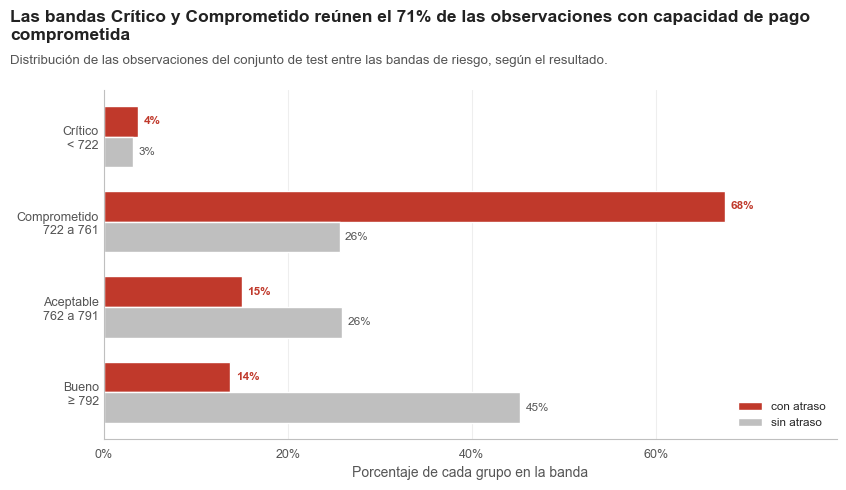

Guardada: graficos_tesis/fig_4_4_distribucion_score.png


In [113]:
# Figura 4.4 — Reparto de las observaciones de test entre las bandas de riesgo, segun el resultado
# (15/11: reemplaza al histograma del score; los cortes y el umbral operativo se informan en el texto)
_etq_b = {'Critico': 'Crítico', 'Comprometido': 'Comprometido', 'Aceptable': 'Aceptable', 'Bueno': 'Bueno'}
_st = np.asarray(scores_test, dtype=float); _dt = np.asarray(defaults_test).astype(int)
_cortes = list(thresholds_4)
_banda = np.select([_st < _cortes[0], _st < _cortes[1], _st < _cortes[2]], labels_4[:3], labels_4[3])
_rango = [f'< {formato_coma(_cortes[0], 0)}', f'{formato_coma(_cortes[0], 0)} a {formato_coma(_cortes[1] - 1, 0)}',
          f'{formato_coma(_cortes[1], 0)} a {formato_coma(_cortes[2] - 1, 0)}', f'≥ {formato_coma(_cortes[2], 0)}']
_p1 = pd.Series(_banda[_dt == 1]).value_counts(normalize=True).reindex(labels_4).fillna(0)
_p0 = pd.Series(_banda[_dt == 0]).value_counts(normalize=True).reindex(labels_4).fillna(0)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
_y = np.arange(len(labels_4))[::-1]; h = 0.36
ax.barh(_y + h / 2, _p1.values, h, color=ENFASIS, label='con atraso')
ax.barh(_y - h / 2, _p0.values, h, color=CONTEXTO, label='sin atraso')
for yy, a, b in zip(_y, _p1.values, _p0.values):
    ax.text(a + 0.006, yy + h / 2, formato_porcentaje(a, 0), va='center', fontsize=8.5, color=ENFASIS, fontweight='bold')
    ax.text(b + 0.006, yy - h / 2, formato_porcentaje(b, 0), va='center', fontsize=8.5, color=GRIS_TXT)
ax.set_yticks(_y)
ax.set_yticklabels([f'{_etq_b[l]}\n{r}' for l, r in zip(labels_4, _rango)], fontsize=9)
ax.tick_params(axis='y', length=0)
ax.set_xlim(0, max(_p1.max(), _p0.max()) * 1.18)
eje_porcentaje(ax, 'x')
ax.set_xlabel('Porcentaje de cada grupo en la banda', color=GRIS_TXT)
ax.legend(frameon=False, fontsize=8.5, loc='lower right')
limpiar_ejes(ax, grid='x')
_bajas = labels_4[:2]
print('Reparto con atraso:', _p1.round(3).to_dict(), '| sin atraso:', _p0.round(3).to_dict())
guardar_figura(fig,
          f'Las bandas {_etq_b[_bajas[0]]} y {_etq_b[_bajas[1]]} reúnen el {formato_porcentaje(_p1[_bajas].sum(), 0)} de las observaciones '
          'con capacidad de pago comprometida',
          'Distribución de las observaciones del conjunto de test entre las bandas de riesgo, según el resultado.',
          '', 'fig_4_4_distribucion_score.png')


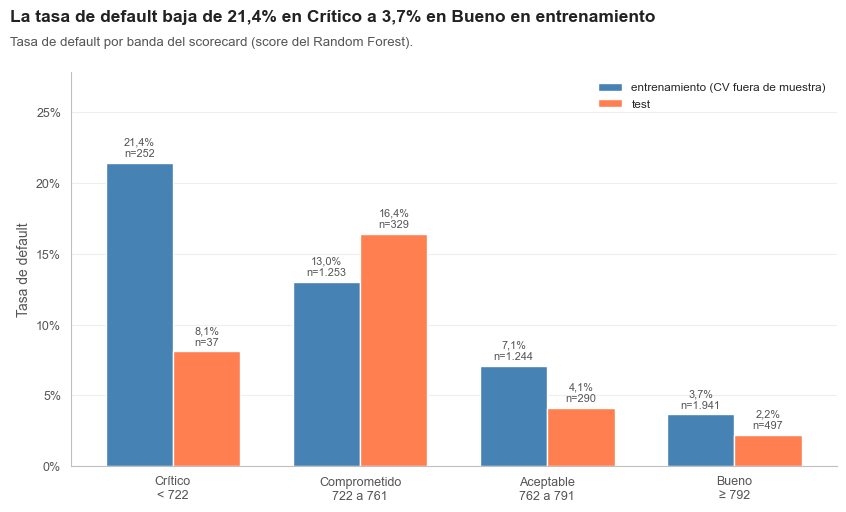

Guardada: graficos_tesis/fig_4_5_default_por_banda.png


In [114]:
# Figura 4.5 — Tasa de default por banda: entrenamiento (CV fuera de muestra) y test lado a lado
_etq_b = {'Critico': 'Crítico', 'Comprometido': 'Comprometido', 'Aceptable': 'Aceptable', 'Bueno': 'Bueno'}
_r = []
for lab in labels_4:
    a, b = df_4[df_4['band'] == lab], df_4_test[df_4_test['band'] == lab]
    _r.append((lab, a['default'].mean(), len(a), b['default'].mean(), len(b), int(b['default'].sum())))
bt = pd.DataFrame(_r, columns=['banda', 'dr_tr', 'n_tr', 'dr_te', 'n_te', 'ev_te'])
_x = np.arange(len(bt)); w = 0.36

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.bar(_x - w / 2, bt['dr_tr'], w, color=COLOR_TRAIN, label='entrenamiento (CV fuera de muestra)')
ax.bar(_x + w / 2, bt['dr_te'], w, color=COLOR_TEST, label='test')
for i, r in bt.iterrows():
    ax.text(i - w / 2, r['dr_tr'] + 0.003, f"{formato_porcentaje(r['dr_tr'])}\nn={formato_coma(r['n_tr'], 0)}", ha='center', va='bottom',
            fontsize=7.8, color=GRIS_TXT)
    ax.text(i + w / 2, r['dr_te'] + 0.003, f"{formato_porcentaje(r['dr_te'])}\nn={formato_coma(r['n_te'], 0)}", ha='center', va='bottom',
            fontsize=7.8, color=GRIS_TXT)
ax.set_xticks(_x)
ax.set_xticklabels([f"{_etq_b[l]}\n{t}" for l, t in zip(labels_4, [f'< {thresholds_4[0]}',
                    f'{thresholds_4[0]} a {thresholds_4[1] - 1}', f'{thresholds_4[1]} a {thresholds_4[2] - 1}',
                    f'≥ {thresholds_4[2]}'])])
ax.set_ylim(0, bt[['dr_tr', 'dr_te']].max().max() * 1.3)
eje_porcentaje(ax, 'y')
ax.set_ylabel('Tasa de default', color=GRIS_TXT)
ax.legend(frameon=False, fontsize=8.5, loc='upper right')
limpiar_ejes(ax, grid='y')
_ratio = bt['dr_te'].iloc[0] / bt['dr_te'].iloc[-1] if bt['dr_te'].iloc[-1] > 0 else np.nan
guardar_figura(fig,
          (f"La tasa de default cae de {formato_porcentaje(bt['dr_te'].iloc[0])} en la banda Crítico a {formato_porcentaje(bt['dr_te'].iloc[-1])} "
           'en Bueno, también en test') if bt['dr_te'].is_monotonic_decreasing else
          (f"La tasa de default baja de {formato_porcentaje(bt['dr_tr'].iloc[0])} en Crítico a {formato_porcentaje(bt['dr_tr'].iloc[-1])} en Bueno en "
           'entrenamiento'),
          f'Tasa de default por banda del scorecard (score {DE_MODELO[winner_name]}).',
          f'Fuente: elaboración propia sobre {FUENTE_EC} y {FUENTE_CR}.\n'
          f"Notas: la banda {_etq_b[bt['banda'].iloc[int(bt['ev_te'].idxmin())]]} tiene {int(bt['ev_te'].min())} {'evento' if int(bt['ev_te'].min()) == 1 else 'eventos'} en test, por lo que su tasa es poco precisa. "
          'Los cortes se ajustaron sobre el entrenamiento y el test solo los valida.',
          'fig_4_5_default_por_banda.png')


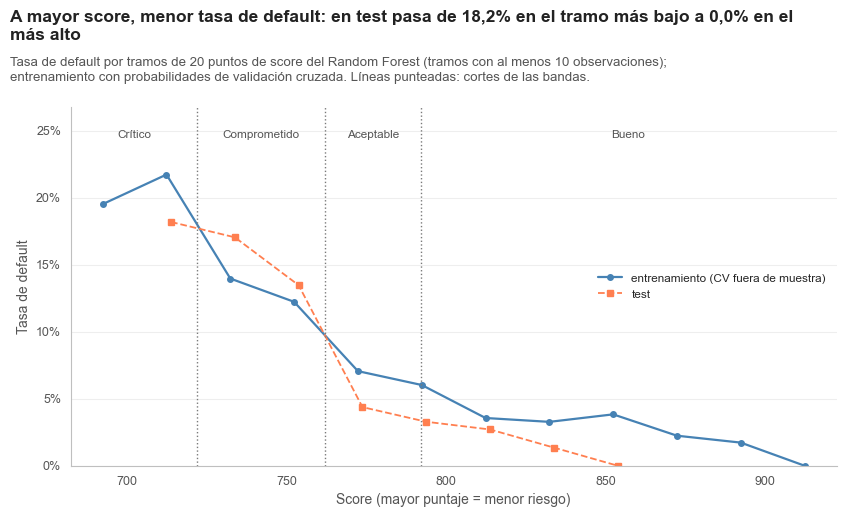

In [115]:
# Se grafica Default Rate vs Score (desarrollo y validacion)
sc_dev,  crv_dev  = tasa_default_por_tramo(scores_dev,  defaults_dev)
sc_test, crv_test = tasa_default_por_tramo(scores_test, defaults_test)

_etq_banda = {'Critico': 'Crítico', 'Comprometido': 'Comprometido', 'Aceptable': 'Aceptable', 'Bueno': 'Bueno'}
_cd, _ct = np.array(crv_dev) / 100, np.array(crv_test) / 100
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(sc_dev, _cd, '-o', color=COLOR_TRAIN, ms=4, lw=1.6, label='entrenamiento (CV fuera de muestra)')
ax.plot(sc_test, _ct, '--s', color=COLOR_TEST, ms=4, lw=1.3, label='test')
for thr in thresholds_4:
    ax.axvline(thr, color=REFERENCIA, ls=':', lw=1)
_top = max(_cd.max(), _ct.max()) * 1.12
_lims = [min(sc_dev[0], sc_test[0]) - 10] + list(thresholds_4) + [max(sc_dev[-1], sc_test[-1]) + 10]
for _lb, (_a, _b) in zip(labels_4, zip(_lims[:-1], _lims[1:])):
    ax.text((_a + _b) / 2, _top, _etq_banda.get(_lb, _lb), ha='center', va='bottom', fontsize=8.5, color=GRIS_TXT)
ax.set_xlim(_lims[0], _lims[-1])
ax.set_ylim(0, _top * 1.1)
eje_porcentaje(ax, 'y')
ax.set_xlabel('Score (mayor puntaje = menor riesgo)', color=GRIS_TXT)
ax.set_ylabel('Tasa de default', color=GRIS_TXT)
ax.legend(frameon=False, fontsize=8.5, loc='center right')
limpiar_ejes(ax, grid='y')
guardar_figura(fig, f'A mayor score, menor tasa de default: en test pasa de {formato_porcentaje(_ct[0])} en el tramo más bajo a '
               f'{formato_porcentaje(_ct[-1])} en el más alto',
          f'Tasa de default por tramos de 20 puntos de score del {NOMBRE_MODELO.get(winner_name, winner_name)} (tramos con al '
          'menos 10 observaciones); entrenamiento con probabilidades de validación cruzada. Líneas punteadas: cortes de '
          'las bandas.', '', None)


## Explicabilidad 

In [116]:
# LIME aplicado al modelo elegido. El pipeline recibe las 137 variables candidatas, pero solo usa las que
# eligio su selector: LIME perturba esas variables, en su escala original (faltantes completados con las
# medianas de entrenamiento del propio pipeline); las demas columnas se completan con sus medianas, que el
# selector descarta, asi que no cambian la prediccion.
warnings.filterwarnings('ignore')
print(f"LIME — MODELO ELEGIDO ({winner_name})")
_med_all = mejor_modelo.named_steps['imputer'].medians_.reindex(cols_pipe)
lime_features = list(mejores_features_final)
X_tr_lime = Xtr[lime_features].fillna(_med_all[lime_features])
X_te_lime = Xte[lime_features].fillna(_med_all[lime_features])


predecir_para_lime = crear_predictor_lime(mejor_modelo, lime_features, cols_pipe, _med_all)


class_names = ['No default', 'Default (1-12 meses)']
_transf_w = mejores_pipe[winner_name]['transform']
print(f"Features: {len(lime_features)}, Estrategia: {mejor_estrategia}")
proba_test_lime = predecir_para_lime(X_te_lime.values)[:, 1]
assert np.allclose(proba_test_lime, proba_test_ganador, atol=1e-12), 'LIME no explica el modelo evaluado'
print(f"AUC test (verificacion de que LIME explica el modelo evaluado): {roc_auc_score(y_test, proba_test_lime):.4f}")

X_train_imputed = X_tr_lime.values
X_test_imputed = X_te_lime.values
explainer = lime_tabular.LimeTabularExplainer(training_data=X_train_imputed, feature_names=lime_features,
                                              class_names=class_names, mode='classification',
                                              discretize_continuous=True, random_state=42)

# CASO A EXPLICAR (el mismo para LIME y SHAP): la observacion de TRAIN con mayor probabilidad de default
# segun el modelo elegido. Criterio declarado, no una fila al azar.
idx_caso = int(np.argmax(proba_train_ganador))
caso_X = X_train_imputed[idx_caso]
caso_y = int(y_train.iloc[idx_caso])
caso_pd = float(proba_train_ganador[idx_caso])
print(f"Caso elegido: observacion de train con mayor P(default) = {caso_pd:.2%} (posicion {idx_caso}); "
      f"clase real: {class_names[caso_y]}")
exp = explainer.explain_instance(data_row=caso_X, predict_fn=predecir_para_lime, num_features=10, num_samples=5000)
actual_pred = predecir_para_lime(caso_X.reshape(1, -1))[0]
print("\nTop contribuciones LIME (positivo = empuja a default; condiciones en valores originales):")
for feature, weight in exp.as_list():
    print(f"  {feature}: {weight:+.3f}")


LIME — MODELO ELEGIDO (RF)
Features: 107, Estrategia: IQR + YJ + RFECV + None


AUC test (verificacion de que LIME explica el modelo evaluado): 0.7510
Caso elegido: observacion de train con mayor P(default) = 23.39% (posicion 2849); clase real: Default (1-12 meses)



Top contribuciones LIME (positivo = empuja a default; condiciones en valores originales):
  Acreeds. Bancarios MNal. > 0.00: +0.021
  Importe_sobre_Ventas > 0.39: +0.016
  Importe_sobre_Patrimonio > 0.57: +0.015
  Acreeds. Bancarios > 0.00: +0.015
  Deuda_sobre_Activos > 0.68: +0.009
  Ratio_Patrimonio <= 0.49: +0.009
  Total Pasivo No Corriente > 2248269.75: +0.009
  Cobertura_de_intereses <= 21.37: +0.008
  Ratio_Efectivo <= 0.07: +0.007
  Relacion_deuda_patrimonio > 0.99: +0.007


In [117]:
# SHAP del modelo elegido, para el mismo caso que LIME (solo explicacion local).
# Regresion logistica: SHAP exacto en forma cerrada (Lundberg y Lee, 2017; lo que implementa
# shap.LinearExplainer). En log-odds: phi_j = coef_j * (z_j - E[z_j]) y base = intercepto + sum coef_j E[z_j],
# donde z es la variable tal como entra al clasificador (despues de outliers, deciles y escalado) y E[.] la
# media de todo el train. Para leerlo en puntos de probabilidad, junto a LIME, las contribuciones se reescalan
# en proporcion: phi_prob_j = phi_j * (P_caso - P_base) / (logit_caso - logit_base); su suma reproduce
# P_caso - P_base. Supuesto: atribucion interventional (independencia entre variables).
# Arboles (RF/DT/XGB): TreeSHAP interventional con 200 observaciones de referencia.
import shap
from sklearn.linear_model import LogisticRegression as _LR
assert 'idx_caso' in dir(), "Ejecutar antes la celda de LIME (define el caso)"
_clf = mejor_modelo.named_steps['classifier']
shap_features = lime_features


Z_tr = transformar_espacio_clasificador(mejor_modelo, completar_variables_entrada(X_tr_lime.values, lime_features, cols_pipe, _med_all))
assert Z_tr.shape[1] == len(shap_features), 'El preprocesamiento cambio la cantidad de variables'
z_caso = Z_tr[[idx_caso]]
pd_modelo = float(predecir_para_lime(X_tr_lime.values[[idx_caso]])[0, 1])
if isinstance(_clf, _LR):
    SHAP_TIPO = 'SHAP exacto (modelo lineal)'
    coef = _clf.coef_.ravel()
    z_ref = Z_tr.mean(axis=0)
    base_logit = float(_clf.intercept_[0] + coef @ z_ref)
    base_pd = float(1 / (1 + np.exp(-base_logit)))
    phi_logit = coef * (z_caso.ravel() - z_ref)
    logit_caso = base_logit + float(phi_logit.sum())
    pd_caso = float(1 / (1 + np.exp(-logit_caso)))
    residuo_aditividad = abs(pd_caso - pd_modelo)
    assert residuo_aditividad < 1e-9, f"La descomposicion no reproduce la prediccion (residuo {residuo_aditividad:.2e})"
    phi = phi_logit * (pd_caso - base_pd) / (logit_caso - base_logit)
    SHAP_NOTA = (f'SHAP exacto del modelo lineal en log-odds (base {formato_signo_coma(base_logit, "+.2f")}, caso {formato_signo_coma(logit_caso, "+.2f")}), '
                 f'reescalado en proporción a puntos de probabilidad; la suma de la base y las contribuciones reproduce '
                 f'la predicción (residuo {formato_signo_coma(residuo_aditividad, ".1e")}).')
else:
    SHAP_TIPO = 'SHAP (TreeSHAP)'
    _fondo = Z_tr[np.random.default_rng(42).choice(len(Z_tr), size=min(200, len(Z_tr)), replace=False)]
    explainer_shap = shap.TreeExplainer(_clf, data=_fondo, feature_perturbation='interventional',
                                        model_output='probability')
    _sv = explainer_shap.shap_values(z_caso)
    _sv = _sv[1] if isinstance(_sv, list) else (_sv[..., 1] if np.ndim(_sv) == 3 else _sv)
    phi = np.asarray(_sv).ravel(); phi_logit = None
    _ev = np.ravel(explainer_shap.expected_value)
    base_pd = float(_ev[1] if len(_ev) > 1 else _ev[0])
    pd_caso = base_pd + float(phi.sum())
    residuo_aditividad = abs(pd_caso - pd_modelo)
    assert residuo_aditividad < 1e-4, f"La descomposicion no reproduce la prediccion (residuo {residuo_aditividad:.2e})"
    SHAP_NOTA = (f'SHAP intervencional con 200 observaciones de referencia; la suma de la base y las contribuciones '
                 f'reproduce la predicción (residuo {format(residuo_aditividad, ".1e").replace(".", ",")}).')

tabla_shap = (pd.DataFrame({'feature': shap_features, 'valor': X_tr_lime.values[idx_caso], 'phi_prob': phi})
              .assign(abs_phi=lambda d: d['phi_prob'].abs()).sort_values('abs_phi', ascending=False)
              .reset_index(drop=True))
print(f"{SHAP_TIPO} — caso de mayor P(default) en train (posicion {idx_caso}), modelo {winner_name}")
print(f"  Clase real: {class_names[caso_y]}")
print(f"  Base: P(default) {base_pd:.2%}  |  caso: {pd_caso:.2%}  |  predict_proba del modelo: {pd_modelo:.2%}")
print(f"  Verificacion de aditividad: |base + sum(phi) - prediccion| = {residuo_aditividad:.1e}")
print("\nTop 10 contribuciones en puntos de probabilidad (positivo = empuja a default; 'valor' = dato del caso):")
print(tabla_shap.head(10)[['feature', 'valor', 'phi_prob']].to_string(
    index=False, formatters={'phi_prob': lambda v: f'{v:+.4f}', 'valor': lambda v: f'{v:,.4g}'}))

_lime_map = {lime_features[i]: w for i, w in exp.as_map()[1]}
_top_shap = tabla_shap.head(10)['feature'].tolist()
_comunes = [f for f in _top_shap if f in _lime_map]
_mismo_signo = [f for f in _comunes if np.sign(_lime_map[f]) == np.sign(tabla_shap.set_index('feature').loc[f, 'phi_prob'])]
print(f"\nContraste con LIME: {len(_comunes)}/10 variables del top SHAP estan en el top 10 de LIME; "
      f"{len(_mismo_signo)}/{len(_comunes)} con el mismo signo.")


SHAP (TreeSHAP) — caso de mayor P(default) en train (posicion 2849), modelo RF
  Clase real: Default (1-12 meses)
  Base: P(default) 7.78%  |  caso: 23.39%  |  predict_proba del modelo: 23.39%
  Verificacion de aditividad: |base + sum(phi) - prediccion| = 1.2e-09

Top 10 contribuciones en puntos de probabilidad (positivo = empuja a default; 'valor' = dato del caso):
                     feature     valor phi_prob
    Acreeds. Bancarios MNal. 1.611e+06  +0.0261
          Acreeds. Bancarios 3.516e+06  +0.0184
        Importe_sobre_Ventas    0.6081  +0.0182
    Importe_sobre_Patrimonio      2.26  +0.0152
              Ratio_Efectivo  0.005774  +0.0117
            Ratio_Patrimonio    0.3195  +0.0090
   Total Pasivo No Corriente 3.516e+06  +0.0087
   Relacion_deuda_patrimonio      2.13  +0.0062
Sub-total - Disponibilidades 1.448e+04  +0.0060
                   delta_ROE   -0.7156  +0.0047

Contraste con LIME: 8/10 variables del top SHAP estan en el top 10 de LIME; 8/8 con el mismo signo.


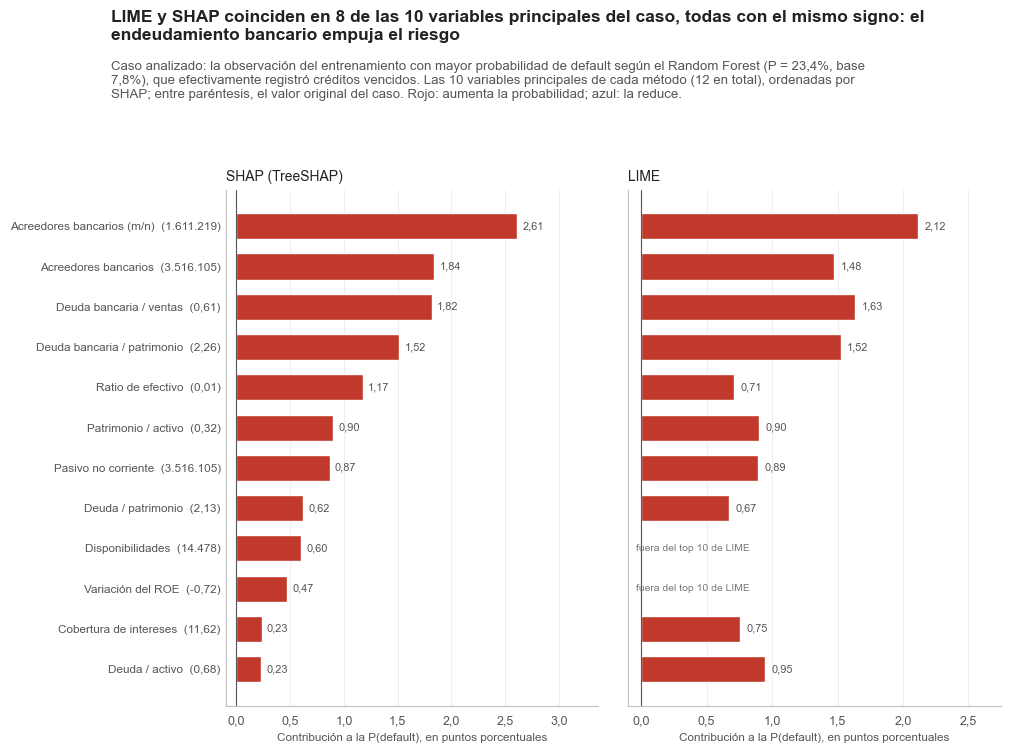

Guardada: graficos_tesis/fig_5_1_lime_shap.png


In [118]:
# Figura 5.1 — LIME y SHAP del mismo caso, con el mismo orden de variables (Gestalt: comparacion directa)
# Filas: la union del top 10 de SHAP y el top 10 de LIME, ordenada por SHAP. SHAP tiene contribucion para
# todas las variables; LIME (10 variables, como en el API) solo para las suyas.
_lime = {lime_features[i]: w for i, w in exp.as_map()[1]}
_union = set(tabla_shap.head(10)['feature']) | set(_lime)
_top = tabla_shap[tabla_shap['feature'].isin(_union)].copy()   # tabla_shap ya esta ordenada por |SHAP|
_top['lime'] = _top['feature'].map(_lime)
_top = _top.iloc[::-1].reset_index(drop=True)


_etqs = [f"{nombre_variable(f)}  ({formato_adaptativo(v)})" for f, v in zip(_top['feature'], _top['valor'])]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 0.5 * len(_top) + 0.7), sharey=True, gridspec_kw={'wspace': 0.08})
for ax, col, tit in [(a1, 'phi_prob', SHAP_TIPO), (a2, 'lime', 'LIME')]:
    vals = _top[col] * 100
    colores = [CONTEXTO if pd.isna(v) else (ENFASIS if v > 0 else OSCURO) for v in vals]
    ax.barh(range(len(_top)), vals.fillna(0), color=colores, height=0.65)
    for i, v in enumerate(vals):
        if pd.isna(v):
            ax.text(0.02, i, 'fuera del top 10 de LIME', va='center', fontsize=7.5, color=REFERENCIA,
                    transform=ax.get_yaxis_transform())
        else:
            ax.text(v + (0.05 if v >= 0 else -0.05), i, formato_coma(v, 2), va='center', ha='left' if v >= 0 else 'right',
                    fontsize=7.8, color=GRIS_TXT)
    ax.axvline(0, color=GRIS_TXT, lw=0.8)
    ax.set_title(tit, fontsize=10, loc='left', color='#222222')
    ax.set_xlabel('Contribución a la P(default), en puntos porcentuales', color=GRIS_TXT, fontsize=8.5)
    lo, hi = np.nanmin(vals.fillna(0)), np.nanmax(vals.fillna(0))
    ax.set_xlim(min(0, lo) * 1.6 - (0.6 if lo < 0 else 0.1), hi * 1.25 + 0.1)
    eje_decimal_coma(ax, 'x', 1)
    limpiar_ejes(ax, grid='x')
a1.set_yticks(range(len(_top)))
a1.set_yticklabels(_etqs, fontsize=8.5)
a1.tick_params(axis='y', length=0)
guardar_figura(fig,
          f'LIME y SHAP coinciden en {len(_comunes)} de las 10 variables principales del caso, '
          f'{"todas" if len(_mismo_signo) == len(_comunes) else len(_mismo_signo)} con el mismo signo: '
          'el endeudamiento bancario empuja el riesgo',
          f'Caso analizado: la observación del entrenamiento con mayor probabilidad de default según {ART_MODELO[winner_name]} '
          f'(P = {formato_porcentaje(pd_modelo)}, base {formato_porcentaje(base_pd)}), que {"efectivamente registró" if caso_y == 1 else "no registró"} créditos vencidos. '
          f'Las 10 variables principales de cada método ({len(_top)} en total), ordenadas por SHAP; entre paréntesis, '
          'el valor original del caso. Rojo: aumenta la probabilidad; azul: la reduce.',
          f'Fuente: elaboración propia sobre {FUENTE_EC} y {FUENTE_CR}.\n'
          f'Notas: {SHAP_NOTA} Los pesos de LIME se expresan en las mismas unidades.',
          'fig_5_1_lime_shap.png', ancho_txt=110)

## Exportacion del modelo final


In [119]:
# Guardo el modelo elegido para produccion. El pipeline completo (imputacion, seleccion, outliers,
# transformacion, escalado y clasificador, todo ajustado en train) se guarda tal cual: el export al API
# lo envuelve para que reciba solo las variables que usa el modelo.
artifacts_dir = Path('results')
artifacts_dir.mkdir(exist_ok=True)
save_path = artifacts_dir / 'modelo_final.pkl'

_sel_w = mejor_modelo.named_steps['selector']
_sel_w.grupos = None        # no se serializan los RUT del entrenamiento (la RFECV ya se ajusto)
_sel_w.cache_dir = None     # ni la ruta local de la cache
_imp_w = mejor_modelo.named_steps['imputer']
medianas_modelo = {c: float(_imp_w.medians_[c]) for c in mejores_features_final}

dataset_info = {
    'target': ('Default en [t+1, t+12] (horizonte 12 meses): credito vencido, en gestion, moroso o '
               'castigado por atraso (>= 60 dias) en cualquier institucion'),
    'n_observations': int(len(X_train) + len(X_test)),
    'n_companies': int(pd.concat([df_train['RUT'], df_test_full['RUT']]).nunique()),
    'default_rate': float(pd.concat([y_train, y_test]).mean()),
    'default_rate_train': float(y_train.mean()),
}
parity_info = {
    'X_test_raw': df_test_full.loc[X_test.index, list(mejores_features_final)].reset_index(drop=True),
    'proba_test': np.asarray(proba_test_ganador, dtype=float),
}
best_model = {
    'is_ensemble': False,
    'pipeline_completo': True,
    'modelo': mejor_modelo,
    'pipeline': mejor_pipeline,
    'features': list(mejores_features_final),
    'input_columns': list(cols_pipe),
    'strategy': mejor_estrategia,
    'outlier': mejor_outlier,
    'transform': mejores_pipe[winner_name]['transform'],
    'outlier_limits': None,
    'decile_transformers': None,
    'metrics': resultados_pipe[winner_name],
    'threshold': float(threshold_operativo),
    'preprocessing': {
        'imputation_medians': medianas_modelo,
        'order': ('inf->NaN -> mediana de train en las variables del modelo -> pipeline completo ajustado en train '
                  '(imputacion, seleccion, outliers, transformacion, escalado y clasificador)'),
    },
    'scorecard': {
        'thresholds': [int(t) for t in thresholds_4],
        'labels': list(labels_4),
        'fit_sample': 'train, CV out-of-fold',
        'iv_dev': float(best_obj),
        'iv_test': float(iv_bandas_scorecard(df_4_test, labels_4)),
        'band_default_rates_test': {label: float(df_4_test.loc[df_4_test['band'] == label, 'default'].mean())
                                    for label in labels_4},
        'pdo': 50,
        'base_score': 600,
    },
    'selection': {
        'criterion': CRITERIO_SELECCION,
        'cv_auc_mean': float(winner['cv_auc_mean']),
        'cv_auc_std': float(winner['cv_auc_std']),
        'threshold_origin': 'Maxima separacion KS (TPR - FPR), promedio por fold (CV GroupKFold(5) por RUT, pipeline completo por fold)',
        'train_auc_in_sample': float(roc_auc_score(y_train, proba_train_ganador)),
    },
    'calibration': None,
    'dataset': dataset_info,
    'parity': parity_info,
    'test_metrics': {
        'test_auc': float(roc_auc_score(y_test, proba_test_ganador)),
        'test_auc_ic95': list(resultados_pipe[winner_name]['test_ic95']),
        'test_ks': float(ks_stat(y_test, proba_test_ganador)),
        'threshold': float(threshold_operativo),
    },
}
joblib.dump({winner_name: best_model}, save_path)
print(f'Modelo {winner_name} guardado en {save_path}')
print(f"  Estrategia: {best_model['strategy']} | {len(best_model['features'])} variables (de {len(cols_pipe)} candidatas)")
print(f"  Threshold: {best_model['threshold']:.4f}")
print(f"  Test_AUC: {best_model['test_metrics']['test_auc']:.4f}  IC95 {best_model['test_metrics']['test_auc_ic95']}")
print(f"  Scorecard: cortes={best_model['scorecard']['thresholds']} "
      f"(fit CV out-of-fold train, IV_test={best_model['scorecard']['iv_test']:.4f})")


Modelo RF guardado en results/modelo_final.pkl
  Estrategia: IQR + YJ + RFECV + None | 107 variables (de 137 candidatas)
  Threshold: 0.0835
  Test_AUC: 0.7510  IC95 [0.694, 0.802]
  Scorecard: cortes=[722, 762, 792] (fit CV out-of-fold train, IV_test=0.8421)


In [120]:
# EXPORTAR LIME TRAINING DATA (para la API): muestra de 500 observaciones de train en las variables del
# modelo, en su escala original, con los faltantes completados con las medianas de train.
n_sample = min(500, len(X_tr_lime))
lime_sample = X_tr_lime.sample(n=n_sample, random_state=42).values
lime_path = Path('results') / 'lime_training_data.pkl'
joblib.dump(lime_sample, lime_path)
print(f'LIME training data exportado: {lime_sample.shape} -> {lime_path}')
print(f'  Features: {len(mejores_features_final)} (matchea feature_names.pkl de la API)')


LIME training data exportado: (500, 107) -> results/lime_training_data.pkl
  Features: 107 (matchea feature_names.pkl de la API)


In [121]:
# Uso del modelo guardado y verificacion de paridad
loaded = joblib.load(save_path)
key_loaded = next(iter(loaded.keys()))
info_loaded = loaded[key_loaded]
proba = predecir_con_modelo_guardado(loaded, X_test_crudo)
auc = roc_auc_score(y_test, proba)
auc_evaluado = roc_auc_score(y_test, proba_test_ganador)
diff = float(np.abs(proba - proba_test_ganador).max())
print(f"{key_loaded}: AUC={auc:.4f} | {info_loaded['strategy']} | {len(info_loaded['features'])} variables")
print(f"AUC evaluado: {auc_evaluado:.6f} | AUC pickle recargado: {auc:.6f} | max|dproba|: {diff:.2e}")
assert diff < 1e-12, 'El modelo serializado NO reproduce el modelo evaluado'

# Simulacion del serving del API: llegan solo las variables del modelo, en crudo; los faltantes se completan
# con las medianas serializadas y el resto de las columnas queda vacio.
_X_srv = parity_info['X_test_raw'].replace([np.inf, -np.inf], np.nan)
_X_srv = _X_srv.fillna(info_loaded['preprocessing']['imputation_medians'])
_p_srv = predecir_con_modelo_guardado(loaded, _X_srv)
_diff_srv = float(np.abs(_p_srv - proba_test_ganador).max())
print(f"Serving (solo variables del modelo): max|dproba| = {_diff_srv:.2e}")
assert _diff_srv < 1e-12, 'El camino de serving no reproduce el modelo evaluado'
print("OK: el modelo serializado reproduce exactamente el modelo evaluado.")


RF: AUC=0.7510 | IQR + YJ + RFECV + None | 107 variables
AUC evaluado: 0.750979 | AUC pickle recargado: 0.750979 | max|dproba|: 1.11e-16


Serving (solo variables del modelo): max|dproba| = 1.11e-16
OK: el modelo serializado reproduce exactamente el modelo evaluado.
